# From transactions to a customer operating system
### CDS3004 Data Mining group project — UCI Online Retail (UK giftware retailer)

**Business question:** which customers should we *retain*, which should we *grow*, and *with which products*?

This notebook is the reproducible analysis pipeline behind that decision. It integrates four
data-mining building blocks into one decision framework:

| # | Technique | Role in the decision |
|---|-----------|----------------------|
| 1 | **K-means clustering** | Describe *who* the customers are (RFM-style segments) |
| 2 | **Churn classification** (logistic regression / decision tree / random forest) | Predict *who is about to leave* and rank them by risk |
| 3 | **Association rules** (FP-Growth) | Decide *what to offer* (cross-sell bundles) |
| 4 | **Similarity & distance** | Find *lookalike customers* (prospecting) and *similar products* (substitutes) |

**Data:** 541,909 transaction lines, 2010-12-01 → 2011-12-09, 4,372 customer IDs in the raw extract (4,334 remain after cleaning; those 4,334 are the modelling population).
Two temporal snapshots are built so that the model is tested both in-sample-time (T1) and
out-of-time (T2): features are cut at an *as-of* date, and churn is measured only in the
3 months *after* that date. No future information leaks into the features.

**How to run:** the notebook reads `data/Online_Retail.xlsx` relative to the project root.
In Google Colab, upload the xlsx into a `data/` folder next to the notebook (the setup cell
will install `mlxtend` if needed). Everything below runs top-to-bottom in a few minutes.

Contents: S0 setup · S1 data quality · S2 snapshots & churn labels · S3 similarity & distance ·
S4 feature engineering/selection · S5 clustering · S6 churn models & evaluation ·
S7 association rules · S8 integrated decision framework · S9 summary & model artefacts.

In [1]:
# ============================================================================
# S0.1  Environment setup, deterministic configuration, helper functions
# ============================================================================
import json
import platform
import re
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")  # headless / Colab-safe backend
import matplotlib.pyplot as plt
import seaborn as sns

# silence only benign warnings (no FutureWarnings break the run)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

# ---- dependency: mlxtend (not pre-installed in every environment) ----------
try:
    import mlxtend

    MLXTEND_VERSION = mlxtend.__version__
    print("mlxtend already available:", MLXTEND_VERSION)
except ImportError:  # Colab fallback
    %pip install -q mlxtend
    import mlxtend

    MLXTEND_VERSION = mlxtend.__version__
    print("mlxtend installed:", MLXTEND_VERSION)

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    adjusted_rand_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

try:
    from sklearn.model_selection import cross_val_predict  # noqa: F401
except ImportError:  # pragma: no cover
    pass

# ---- paths: work relative to the project root so the notebook is portable ----
BASE_DIR = Path.cwd().resolve()
while not (BASE_DIR / "data").exists() and BASE_DIR.parent != BASE_DIR:
    BASE_DIR = BASE_DIR.parent

DATA_CANDIDATES = [
    BASE_DIR / "data" / "Online_Retail.xlsx",
    Path.cwd() / "data" / "Online_Retail.xlsx",
    Path("/content/data/Online_Retail.xlsx"),
    Path("/content/Online_Retail.xlsx"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Online_Retail.xlsx not found. In Colab, upload it to /content/data/Online_Retail.xlsx "
        "(or /content/Online_Retail.xlsx). Locally, keep it at data/Online_Retail.xlsx."
    )
BASE_DIR = DATA_PATH.parent.parent if DATA_PATH.parent.name == "data" else DATA_PATH.parent
FIG_DIR = BASE_DIR / "results" / "figures"
TAB_DIR = BASE_DIR / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "legend.fontsize": 8.5,
    }
)
sns.set_theme(style="whitegrid", palette="deep")
sns.set_context("notebook")

T_START = time.time()


# ---- small I/O helpers shared by all sections ------------------------------
try:  # embed every saved figure in the notebook output (Jupyter/Colab/nbconvert)
    from IPython.display import Image, display

    def _inline_image(name):
        display(Image(filename=str(FIG_DIR / (name + ".png"))))
except Exception:  # pragma: no cover - plain script execution
    def _inline_image(name):
        pass


def save_fig(fig, *names):
    # Save one figure under one or more deliverable names (150 dpi), then show it inline.
    for name in names:
        fig.savefig(FIG_DIR / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.close(fig)
    _inline_image(names[0])


def save_table(df, *names, index=False):
    # Save one table under one or more deliverable names.
    for name in names:
        df.to_csv(TAB_DIR / (name + ".csv"), index=index)


def r4(x):
    return None if x is None else round(float(x), 4)


print("project root :", BASE_DIR)
print("data file    :", DATA_PATH)
print("python       :", sys.version.split()[0], "|", platform.platform())
print("pandas       :", pd.__version__)

mlxtend already available: 0.25.0


project root : /Users/aronlin/Documents/deepseek-harness/default-workspace/cds3004-project
data file    : /Users/aronlin/Documents/deepseek-harness/default-workspace/cds3004-project/data/Online_Retail.xlsx
python       : 3.14.6 | macOS-15.5-arm64-arm-64bit-Mach-O
pandas       : 3.1.1


In [2]:
# ---- library versions (also written to results/metrics.json at the end) -----
import matplotlib as mpl

LIB_VERSIONS = {
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit-learn": __import__("sklearn").__version__,
    "matplotlib": mpl.__version__,
    "seaborn": sns.__version__,
    "scipy": __import__("scipy").__version__,
    "mlxtend": MLXTEND_VERSION,
}
for k, v in LIB_VERSIONS.items():
    print(f"{k:12s} {v}")

python       3.14.6
pandas       3.1.1
numpy        2.5.4
scikit-learn 1.9.1
matplotlib   3.11.2
seaborn      0.13.2
scipy        1.18.1
mlxtend      0.25.0


## S1. Data-quality audit and cleaning

The raw extract is a *transaction log*, not an analysis table: it mixes real sales with
cancellations, returns, postage, discounts, manual adjustments and unidentified guests.
Every one of those has to be classified before any modelling, otherwise "revenue",
"frequency" and "churn" mean different things in different parts of the pipeline.

**Audit checklist**
1. **Missing values** — `CustomerID` is missing for ~24.9% of lines. Those rows cannot be
   attributed to a customer, so they must leave the customer-level analysis (they are
   *not* deleted from the raw file; the bias this creates is measured explicitly).
2. **Duplicate rows** — exact duplicates are log artefacts and would double-count baskets.
3. **Cancellations** (`InvoiceNo` starting with `C`) and **negative quantities** — these are
   returns/credit notes, not purchases. We keep them in a separate *returns ledger* so that
   each customer's **return rate** can be computed as a behavioural feature.
4. **Non-positive prices** — free items, manual price overrides, bad entries.
5. **Non-product stock codes** — POST, D, M, C2, DOT, PADS, BANK CHARGES, CRUK, S, AMAZONFEE,
   B, ADJUST, ADJUST2, TEST001/2. Keeping them would make "products bought" and
   market-basket rules meaningless.

**Taxonomy we keep in mind throughout:** identified purchases (clean base) vs anonymous sales
vs returns. The clean base is the *only* table used for customer features.

In [3]:
# ============================================================================
# S1.1  Load raw data and profile it
# ============================================================================
df_raw = pd.read_excel(DATA_PATH)
N_RAW = len(df_raw)
df_raw["InvoiceNo"] = df_raw["InvoiceNo"].astype(str).str.strip()
df_raw["StockCode"] = df_raw["StockCode"].astype(str).str.strip()
df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"])
df_raw["Revenue"] = df_raw["Quantity"] * df_raw["UnitPrice"]

RAW_GROSS_REVENUE = float(
    df_raw.loc[(df_raw.Quantity > 0) & (df_raw.UnitPrice > 0), "Revenue"].sum()
)
RAW_TOTAL_REVENUE = float(df_raw["Revenue"].sum())

DATE_MIN = df_raw["InvoiceDate"].min()
DATE_MAX = df_raw["InvoiceDate"].max()

print(f"rows              : {N_RAW:,}")
print(f"date range        : {DATE_MIN:%Y-%m-%d} .. {DATE_MAX:%Y-%m-%d}")
print(f"customers (ID)    : {df_raw.CustomerID.nunique():,}")
print(f"invoices          : {df_raw.InvoiceNo.nunique():,}")
print(f"stock codes       : {df_raw.StockCode.nunique():,}")
print(f"gross revenue     : GBP {RAW_GROSS_REVENUE:,.2f}")
print(f"net revenue (incl cancellations): GBP {RAW_TOTAL_REVENUE:,.2f}")
print()
print("missing values:")
print(df_raw.isna().sum().to_string())

rows              : 541,909
date range        : 2010-12-01 .. 2011-12-09
customers (ID)    : 4,372
invoices          : 25,900
stock codes       : 4,070
gross revenue     : GBP 10,666,684.54
net revenue (incl cancellations): GBP 9,747,747.93

missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Revenue             0


In [4]:
# ============================================================================
# S1.2  Quantify every issue class
# ============================================================================
SERVICE_CODES = {
    "POST", "D", "M", "C2", "DOT", "PADS", "BANK CHARGES", "CRUK", "S",
    "AMAZONFEE", "B", "ADJUST", "ADJUST2", "TEST001", "TEST002",
}
STOCK_UPPER = df_raw["StockCode"].str.upper()

mask_missing_cid = df_raw["CustomerID"].isna()
mask_cancelled = df_raw["InvoiceNo"].str.upper().str.startswith("C")
mask_nonpos_qty = df_raw["Quantity"] <= 0
mask_nonpos_price = df_raw["UnitPrice"] <= 0
mask_service = STOCK_UPPER.isin(SERVICE_CODES) | STOCK_UPPER.str.startswith("BANK")
mask_dup = df_raw.duplicated()
mask_missing_desc = df_raw["Description"].isna()

anon_revenue = float(df_raw.loc[mask_missing_cid, "Revenue"].sum())
ANON_REVENUE_SHARE_PCT = anon_revenue / RAW_GROSS_REVENUE * 100

counts = {
    "missing_customerid": int(mask_missing_cid.sum()),
    "duplicates": int(mask_dup.sum()),
    "cancelled": int(mask_cancelled.sum()),
    "negative_qty": int((df_raw.Quantity < 0).sum()),
    "zero_qty": int((df_raw.Quantity == 0).sum()),
    "nonpositive_price": int(mask_nonpos_price.sum()),
    "nonproduct_codes": int(mask_service.sum()),
    "missing_description": int(mask_missing_desc.sum()),
}
for k, v in counts.items():
    print(f"{k:22s} {v:>8,}  ({v / N_RAW * 100:5.2f}% of rows)")

print()
print(f"revenue on rows without CustomerID : GBP {anon_revenue:,.2f}")
print(f"  = {ANON_REVENUE_SHARE_PCT:.2f}% of gross revenue  <-- what we lose by dropping guests")
print(f"negative-quantity revenue (returns) : GBP {df_raw.loc[mask_nonpos_qty, 'Revenue'].sum():,.2f}")

missing_customerid      135,080  (24.93% of rows)
duplicates                5,268  ( 0.97% of rows)
cancelled                 9,288  ( 1.71% of rows)
negative_qty             10,624  ( 1.96% of rows)
zero_qty                      0  ( 0.00% of rows)
nonpositive_price         2,517  ( 0.46% of rows)
nonproduct_codes          2,916  ( 0.54% of rows)
missing_description       1,454  ( 0.27% of rows)

revenue on rows without CustomerID : GBP 1,447,682.12
  = 13.57% of gross revenue  <-- what we lose by dropping guests
negative-quantity revenue (returns) : GBP -896,812.49


In [5]:
# ============================================================================
# S1.3  Deliverable tables: dataset schema + issue audit
# ============================================================================
schema_rows = []
notes = {
    "InvoiceNo": "invoice identifier; a leading 'C' marks a cancellation / credit note",
    "StockCode": "SKU; contains non-product service codes (POST, D, M, BANK CHARGES, ...)",
    "Description": "free-text product name; 1,454 missing values",
    "Quantity": "units on the line; negative values are returns / adjustments",
    "InvoiceDate": "timestamp of the invoice line",
    "UnitPrice": "unit price in GBP; non-positive values are free items or errors",
    "CustomerID": "customer identifier; missing for ~24.9% of lines (guest checkouts)",
    "Country": "customer country (United Kingdom dominates)",
}
for col in ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country"]:
    non_null = int(df_raw[col].notna().sum())
    example = df_raw[col].dropna().iloc[0]
    if col == "InvoiceDate":
        example = str(example)
    schema_rows.append(
        {
            "column": col,
            "dtype": str(df_raw[col].dtype),
            "non_null": non_null,
            "missing": int(N_RAW - non_null),
            "example_value": str(example)[:60],
            "note": notes[col],
        }
    )
df_schema = pd.DataFrame(schema_rows)
save_table(df_schema, "t01_dataset_schema")
print(df_schema.to_string(index=False))

     column          dtype  non_null  missing                      example_value                                                                    note
  InvoiceNo            str    541909        0                             536365    invoice identifier; a leading 'C' marks a cancellation / credit note
  StockCode            str    541909        0                             85123A SKU; contains non-product service codes (POST, D, M, BANK CHARGES, ...)
Description         object    540455     1454 WHITE HANGING HEART T-LIGHT HOLDER                            free-text product name; 1,454 missing values
   Quantity          int64    541909        0                                  6            units on the line; negative values are returns / adjustments
InvoiceDate datetime64[us]    541909        0                2010-12-01 08:26:00                                           timestamp of the invoice line
  UnitPrice        float64    541909        0                               2.55  

In [6]:
# issue audit: what is wrong, how much, and what we do about it
issues = [
    ("Missing CustomerID", counts["missing_customerid"],
     "Drop from customer analysis; kept in raw file (measured bias below)"),
    ("Exact duplicate rows", counts["duplicates"],
     "Drop all but the first occurrence"),
    ("Cancelled invoices ('C' prefix)", counts["cancelled"],
     "Drop from purchase base; kept as a separate returns ledger"),
    ("Negative Quantity (returns/adjustments)", counts["negative_qty"],
     "Drop from purchase base; used to build return_rate"),
    ("Zero or negative UnitPrice", counts["nonpositive_price"],
     "Drop (free items, price overrides, errors)"),
    ("Non-product / service StockCodes", counts["nonproduct_codes"],
     "Drop (POST, D, M, C2, DOT, PADS, BANK CHARGES, CRUK, S, AMAZONFEE, B, ADJUST, TEST...)"),
    ("Missing Description", counts["missing_description"],
     "Fill with 'UNKNOWN'; affects product labels only, not modelling"),
]
df_issues = pd.DataFrame(issues, columns=["issue", "count", "decision"])
df_issues["pct_of_rows"] = (df_issues["count"] / N_RAW * 100).round(2)
df_issues = df_issues[["issue", "count", "pct_of_rows", "decision"]]
save_table(df_issues, "t02_data_quality_issues", "t01_data_quality")
print(df_issues.to_string(index=False))

                                  issue  count  pct_of_rows                                                                               decision
                     Missing CustomerID 135080        24.93                    Drop from customer analysis; kept in raw file (measured bias below)
                   Exact duplicate rows   5268         0.97                                                      Drop all but the first occurrence
        Cancelled invoices ('C' prefix)   9288         1.71                             Drop from purchase base; kept as a separate returns ledger
Negative Quantity (returns/adjustments)  10624         1.96                                     Drop from purchase base; used to build return_rate
             Zero or negative UnitPrice   2517         0.46                                             Drop (free items, price overrides, errors)
       Non-product / service StockCodes   2916         0.54 Drop (POST, D, M, C2, DOT, PADS, BANK CHARGES, CRUK, S, AM

In [7]:
# ============================================================================
# S1.4  Cleaning funnel (each decision is counted, so the loss is auditable)
# ============================================================================
SERVICE_UPPER = SERVICE_CODES

funnel = []
df = df_raw.copy()

funnel.append(("Raw dataset as extracted", 0, len(df), "UCI Online Retail, 541,909 transaction lines"))

n_before = len(df)
df = df[df["CustomerID"].notna()].copy()
df["CustomerID"] = df["CustomerID"].astype(int)
funnel.append(("Drop rows with missing CustomerID", n_before - len(df), len(df),
               "cannot be attributed to a customer; guest sales are excluded from customer analytics"))

n_before = len(df)
df = df[~df["InvoiceNo"].str.upper().str.startswith("C")].copy()
funnel.append(("Drop cancelled invoices", n_before - len(df), len(df),
               "credit notes, not purchases; retained separately as the returns ledger"))

n_before = len(df)
df = df[df["Quantity"] > 0].copy()
funnel.append(("Drop Quantity <= 0", n_before - len(df), len(df),
               "returns / stock adjustments inside non-cancelled invoices"))

n_before = len(df)
df = df[df["UnitPrice"] > 0].copy()
funnel.append(("Drop UnitPrice <= 0", n_before - len(df), len(df),
               "free items, manual overrides and data-entry errors"))

n_before = len(df)
df = df[~df["StockCode"].str.upper().isin(SERVICE_UPPER)].copy()
funnel.append(("Drop non-product / service StockCodes", n_before - len(df), len(df),
               "postage, discounts, bank charges, test SKUs would pollute baskets"))

n_before = len(df)
df = df.drop_duplicates().copy()
funnel.append(("Drop exact duplicate rows", n_before - len(df), len(df),
               "duplicated log lines would double-count baskets"))

df = df.reset_index(drop=True)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["date"] = df["InvoiceDate"].dt.normalize()
df["Description"] = df["Description"].fillna("UNKNOWN")

df_funnel = pd.DataFrame(funnel, columns=["decision", "rows_affected", "rows_remaining", "rationale"])
save_table(df_funnel, "t03_cleaning_decisions")
print(df_funnel.to_string(index=False))

clean = df
N_CLEAN = len(clean)
CLEAN_REVENUE = float(clean["Revenue"].sum())
ROWS_RETAINED_PCT = N_CLEAN / N_RAW * 100
REVENUE_RETAINED_PCT = CLEAN_REVENUE / RAW_GROSS_REVENUE * 100
N_CUSTOMERS = clean["CustomerID"].nunique()

# returns ledger: cancellation lines that DO belong to a known customer
returns = df_raw[
    df_raw["InvoiceNo"].str.upper().str.startswith("C")
    & (df_raw["Quantity"] < 0)
    & df_raw["CustomerID"].notna()
].copy()
returns["CustomerID"] = returns["CustomerID"].astype(int)
returns["date"] = returns["InvoiceDate"].dt.normalize()
N_RETURN_LINES = len(returns)

print()
print(f"clean transaction lines : {N_CLEAN:,}  ({ROWS_RETAINED_PCT:.2f}% of raw rows)")
print(f"clean revenue           : GBP {CLEAN_REVENUE:,.2f}  ({REVENUE_RETAINED_PCT:.2f}% of gross revenue)")
print(f"identified customers    : {N_CUSTOMERS:,}")
print(f"clean invoices          : {clean.InvoiceNo.nunique():,}")
print(f"clean products          : {clean.StockCode.nunique():,}")
print(f"returns ledger lines    : {N_RETURN_LINES:,} (kept for return_rate feature)")
print(f"date range (clean)      : {clean.date.min():%Y-%m-%d} .. {clean.date.max():%Y-%m-%d}")

                             decision  rows_affected  rows_remaining                                                                            rationale
             Raw dataset as extracted              0          541909                                         UCI Online Retail, 541,909 transaction lines
    Drop rows with missing CustomerID         135080          406829 cannot be attributed to a customer; guest sales are excluded from customer analytics
              Drop cancelled invoices           8905          397924               credit notes, not purchases; retained separately as the returns ledger
                   Drop Quantity <= 0              0          397924                            returns / stock adjustments inside non-cancelled invoices
                  Drop UnitPrice <= 0             40          397884                                   free items, manual overrides and data-entry errors
Drop non-product / service StockCodes           1547          396337        


clean transaction lines : 391,150  (72.18% of raw rows)
clean revenue           : GBP 8,737,227.64  (81.91% of gross revenue)
identified customers    : 4,334
clean invoices          : 18,402
clean products          : 3,659
returns ledger lines    : 8,905 (kept for return_rate feature)
date range (clean)      : 2010-12-01 .. 2011-12-09


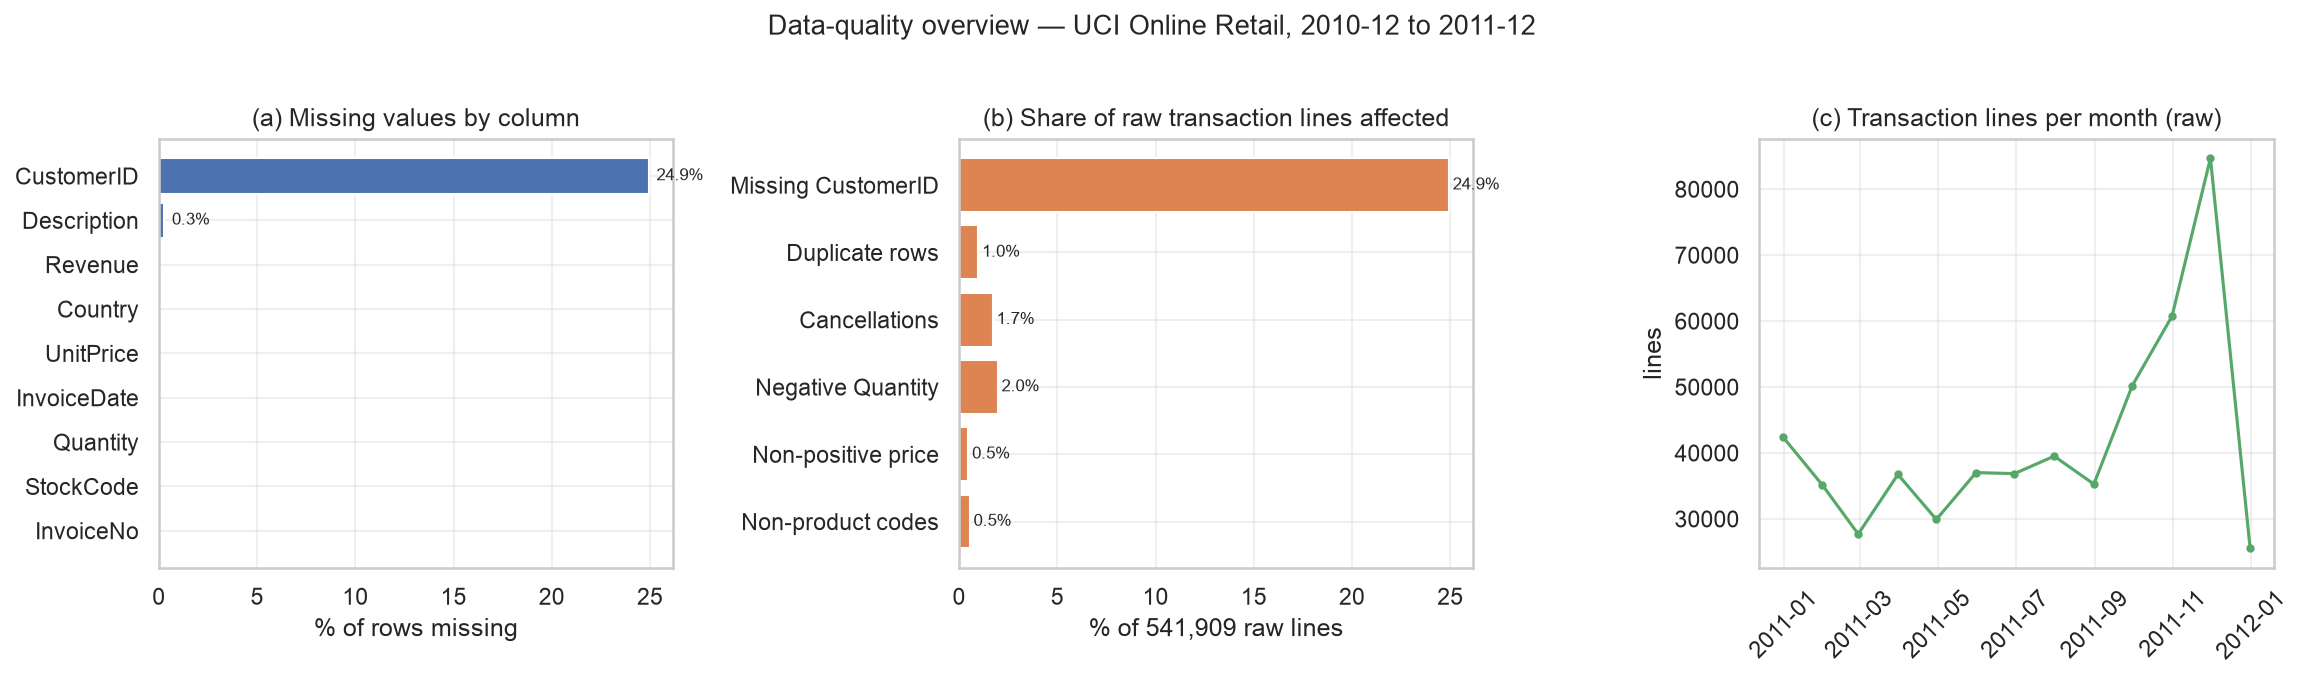

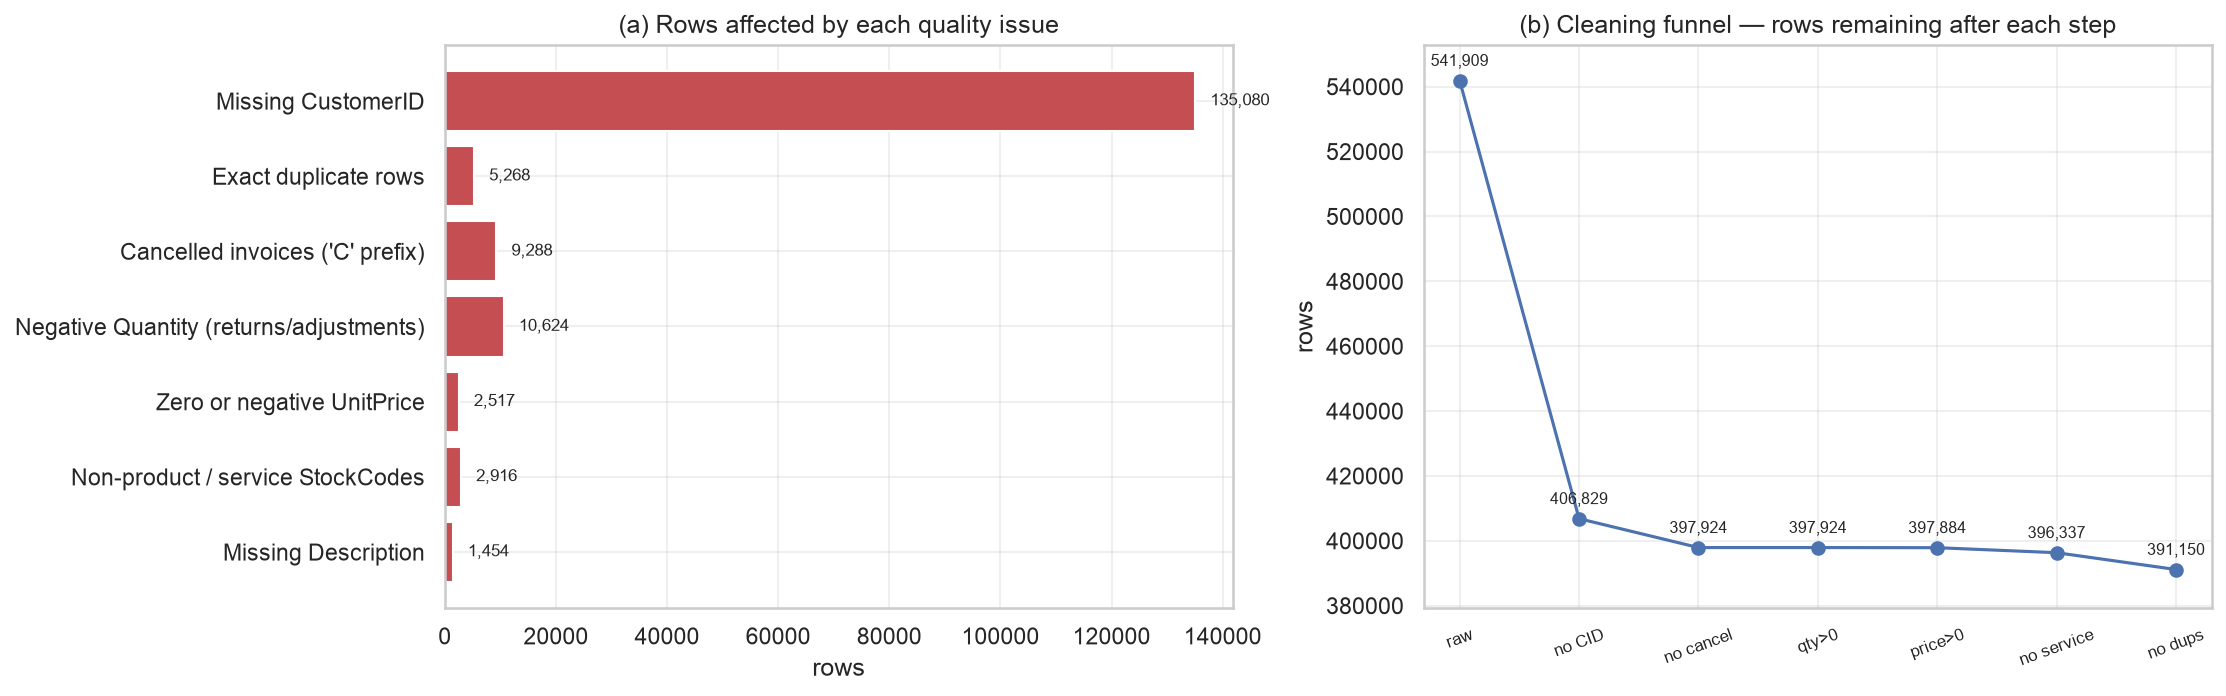

rows retained after each step: [541909, 406829, 397924, 397924, 397884, 396337, 391150]


In [8]:
# ============================================================================
# S1.5  Figures: data-quality overview + before/after cleaning
# ============================================================================
# --- f01_data_quality_overview: missingness, issue shares, 12-month coverage ---
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

miss_pct = (df_raw.isna().mean() * 100).sort_values(ascending=True)
axes[0].barh(miss_pct.index, miss_pct.values, color="#4C72B0")
axes[0].set_title("(a) Missing values by column")
axes[0].set_xlabel("% of rows missing")
for i, v in enumerate(miss_pct.values):
    if v > 0:
        axes[0].text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=8)

share_labels = [
    "Missing CustomerID",
    "Duplicate rows",
    "Cancellations",
    "Negative Quantity",
    "Non-positive price",
    "Non-product codes",
]
share_vals = [
    counts["missing_customerid"],
    counts["duplicates"],
    counts["cancelled"],
    counts["negative_qty"],
    counts["nonpositive_price"],
    counts["nonproduct_codes"],
]
axes[1].barh(share_labels[::-1], [v / N_RAW * 100 for v in share_vals[::-1]], color="#DD8452")
axes[1].set_title("(b) Share of raw transaction lines affected")
axes[1].set_xlabel("% of 541,909 raw lines")
for i, v in enumerate([v / N_RAW * 100 for v in share_vals[::-1]]):
    axes[1].text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=8)

monthly = df_raw.set_index("InvoiceDate").resample("ME").size()
axes[2].plot(monthly.index, monthly.values, marker="o", ms=3, color="#55A868")
axes[2].set_title("(c) Transaction lines per month (raw)")
axes[2].set_ylabel("lines")
axes[2].tick_params(axis="x", rotation=45)
fig.suptitle("Data-quality overview — UCI Online Retail, 2010-12 to 2011-12", fontsize=13, y=1.02)
fig.tight_layout()
save_fig(fig, "f01_data_quality_overview")

# --- f01_data_quality: issue counts and the cleaning funnel -------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
issue_names = [r[0] for r in issues]
issue_counts = [r[1] for r in issues]
axes[0].barh(issue_names[::-1], issue_counts[::-1], color="#C44E52")
axes[0].set_title("(a) Rows affected by each quality issue")
axes[0].set_xlabel("rows")
for i, v in enumerate(issue_counts[::-1]):
    axes[0].text(v + N_RAW * 0.005, i, f"{v:,}", va="center", fontsize=8)

funnel_labels = [f"{r[0]}\n(remaining {r[2]:,})" for r in funnel]
remaining = [r[2] for r in funnel]
axes[1].plot(range(len(funnel)), remaining, marker="o", color="#4C72B0")
axes[1].set_xticks(range(len(funnel)))
step_labels = ["raw", "no CID", "no cancel", "qty>0", "price>0", "no service", "no dups"]
axes[1].set_xticklabels(step_labels, fontsize=8, rotation=20)
axes[1].set_ylim(min(remaining) * 0.97, N_RAW * 1.02)
axes[1].set_title("(b) Cleaning funnel — rows remaining after each step")
axes[1].set_ylabel("rows")
for i, v in enumerate(remaining):
    axes[1].annotate(f"{v:,}", (i, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7.5)
fig.tight_layout()
save_fig(fig, "f01_data_quality")
print("rows retained after each step:", remaining)

## S2. Temporal snapshots and churn labels

A churn model must never see the future. We therefore cut the data at an **as-of date** and
build one row per customer from the preceding **feature window**; the label is whether that
customer buys again in the following **label window** (3 months).

* **T1 (model development)** — as-of `2011-05-31`; features `2010-12-01..2011-05-31`;
  churn = no purchase in `2011-06-01..2011-08-31`.
* **T2 (out-of-time validation + decision cohort)** — as-of `2011-08-31`; features
  `2011-03-01..2011-08-31`; churn = no purchase in `2011-09-01..2011-11-30`.

T1 is used to train and tune; T2 is a genuine *future* cohort, so any performance drop from T1
to T2 is an honest estimate of temporal drift. The snapshot function also builds the
**return rate** from the returns ledger and a **revenue-momentum ratio** (last 90 days vs the
previous 90 days), which are the two behavioural signals that plain RFM misses.

Only customers with at least one purchase inside the feature window get a snapshot row —
otherwise "recency/frequency/monetary" would be undefined.

In [9]:
# ============================================================================
# S2.1  Snapshot builder
# ============================================================================
SNAP_FEATURES = [
    "recency_days", "frequency", "monetary", "avg_basket", "avg_items_per_invoice",
    "distinct_products", "distinct_months", "tenure_days", "avg_gap_days", "std_gap_days",
    "revenue_last90_ratio", "weekend_share", "avg_unit_price", "max_invoice_value", "return_rate",
]
MODEL_FEATURES = SNAP_FEATURES + ["is_uk"]


def build_snapshot(df_clean, returns_df, as_of, window_months=6, label_months=3):
    # One row per customer with activity in [as_of - window, as_of].
    # Features use ONLY information available up to as_of. The churn label is
    # 1 when the customer makes no purchase in (as_of, as_of + label_months].
    as_of = pd.Timestamp(as_of)
    start = as_of - pd.DateOffset(months=window_months) + pd.Timedelta(days=1)
    fw = df_clean[(df_clean["date"] >= start) & (df_clean["date"] <= as_of)]
    g = fw.groupby("CustomerID")

    snap = pd.DataFrame(index=g.size().index)
    snap.index.name = "CustomerID"
    inv = snap.index

    # --- RFM core ---
    snap["recency_days"] = (as_of - g["date"].max()).dt.days
    snap["frequency"] = g["InvoiceNo"].nunique()
    snap["monetary"] = g["Revenue"].sum()

    # --- basket economics ---
    basket = fw.groupby(["CustomerID", "InvoiceNo"])["Revenue"].sum().groupby("CustomerID")
    snap["avg_basket"] = basket.mean()
    snap["avg_items_per_invoice"] = (
        fw.groupby(["CustomerID", "InvoiceNo"]).size().groupby("CustomerID").mean()
    )
    snap["max_invoice_value"] = basket.max()
    snap["avg_unit_price"] = g["UnitPrice"].mean()

    # --- breadth / engagement ---
    snap["distinct_products"] = g["StockCode"].nunique()
    snap["distinct_months"] = g["date"].apply(lambda s: s.dt.to_period("M").nunique())

    first_ever = df_clean[df_clean["date"] <= as_of].groupby("CustomerID")["date"].min()
    snap["tenure_days"] = (as_of - first_ever.reindex(inv)).dt.days

    # --- purchase rhythm: mean / sd of gaps between distinct purchase days ---
    def gap_stats(s):
        days = np.sort(s.unique())
        if len(days) < 2:
            return pd.Series([0.0, 0.0])
        gaps = np.diff(days).astype("timedelta64[D]").astype(float)
        return pd.Series([gaps.mean(), gaps.std(ddof=0)])

    gaps = g["date"].apply(gap_stats).unstack()
    gaps.columns = ["avg_gap_days", "std_gap_days"]
    snap = snap.join(gaps)

    # --- momentum: last 90d revenue vs the 90d before that (smoothed, capped) ---
    last90 = fw[fw["date"] > as_of - pd.Timedelta(days=90)].groupby("CustomerID")["Revenue"].sum()
    prev90 = fw[
        (fw["date"] <= as_of - pd.Timedelta(days=90))
        & (fw["date"] > as_of - pd.Timedelta(days=180))
    ].groupby("CustomerID")["Revenue"].sum()
    momentum = (last90.reindex(inv).fillna(0) + 1) / (prev90.reindex(inv).fillna(0) + 1)
    snap["revenue_last90_ratio"] = momentum.clip(upper=10)

    # --- context / behaviour ---
    snap["weekend_share"] = fw.assign(w=fw["date"].dt.dayofweek >= 5).groupby("CustomerID")["w"].mean()
    snap["is_uk"] = (fw.groupby("CustomerID")["Country"].first() == "United Kingdom").astype(int)

    # --- returns ledger: return lines / (return + purchase lines) ---
    ret_in_window = (
        returns_df[(returns_df["date"] >= start) & (returns_df["date"] <= as_of)]
        .groupby("CustomerID")
        .size()
        .reindex(inv)
        .fillna(0)
    )
    purchase_lines = g.size()
    snap["return_rate"] = ret_in_window / (ret_in_window + purchase_lines)

    # --- label: no purchase in the label window ---
    label_end = as_of + pd.DateOffset(months=label_months)
    future_buyers = set(
        df_clean[(df_clean["date"] > as_of) & (df_clean["date"] <= label_end)]["CustomerID"].unique()
    )
    snap["churn"] = (~snap.index.isin(future_buyers)).astype(int)

    out = snap.reset_index()
    out.attrs["as_of"] = as_of
    out.attrs["feature_window"] = (start, as_of)
    out.attrs["label_window"] = (as_of + pd.Timedelta(days=1), label_end)
    return out


T1 = build_snapshot(clean, returns, "2011-05-31")
T2 = build_snapshot(clean, returns, "2011-08-31")

print("T1 features:", T1.attrs["feature_window"][0].date(), "->", T1.attrs["feature_window"][1].date(),
      "| label window:", T1.attrs["label_window"][0].date(), "->", T1.attrs["label_window"][1].date())
print("T2 features:", T2.attrs["feature_window"][0].date(), "->", T2.attrs["feature_window"][1].date(),
      "| label window:", T2.attrs["label_window"][0].date(), "->", T2.attrs["label_window"][1].date())
print()
print(f"T1 customers: {len(T1):,}   churn rate: {T1.churn.mean():.4f}")
print(f"T2 customers: {len(T2):,}   churn rate: {T2.churn.mean():.4f}")
print()
print("class balance (T1):", T1.churn.value_counts().to_dict())
print("class balance (T2):", T2.churn.value_counts().to_dict())

T1 features: 2010-12-01 -> 2011-05-31 | label window: 2011-06-01 -> 2011-08-31
T2 features: 2011-03-01 -> 2011-08-31 | label window: 2011-09-01 -> 2011-11-30

T1 customers: 2,716   churn rate: 0.5044
T2 customers: 2,809   churn rate: 0.3955

class balance (T1): {1: 1370, 0: 1346}
class balance (T2): {0: 1698, 1: 1111}


In [10]:
# ============================================================================
# S2.2  Cohort summary table + feature dictionary + sanity check
# ============================================================================
cohort_rows = []
for name, snap, as_of in [("T1", T1, "2011-05-31"), ("T2", T2, "2011-08-31")]:
    fw = snap.attrs["feature_window"]
    lw = snap.attrs["label_window"]
    cohort_rows.append(
        {
            "cohort": name,
            "n_customers": len(snap),
            "churn_rate": round(float(snap.churn.mean()), 4),
            "as_of": as_of,
            "feature_window": f"{fw[0]:%Y-%m-%d}..{fw[1]:%Y-%m-%d}",
            "label_window": f"{lw[0]:%Y-%m-%d}..{lw[1]:%Y-%m-%d}",
            "role": "model development (train/val/test)" if name == "T1" else "out-of-time validation + decision cohort",
        }
    )
df_cohort = pd.DataFrame(cohort_rows)
save_table(df_cohort, "t02_cohort_summary")
print(df_cohort.to_string(index=False))

assert T1[MODEL_FEATURES].isna().sum().sum() == 0, "unexpected missing feature values in T1"
assert T2[MODEL_FEATURES].isna().sum().sum() == 0, "unexpected missing feature values in T2"

print()
print("feature ranges (T1):")
print(T1[MODEL_FEATURES].describe().T[["mean", "std", "min", "50%", "max"]].round(2).to_string())

FEATURE_DICT = {
    "recency_days": ("days from last purchase in the feature window to as_of", "RFM"),
    "frequency": ("number of distinct invoices in the feature window", "RFM"),
    "monetary": ("total revenue (GBP) in the feature window", "RFM"),
    "avg_basket": ("mean revenue per invoice", "Monetary"),
    "avg_items_per_invoice": ("mean number of line items per invoice", "Basket"),
    "distinct_products": ("number of distinct StockCodes purchased", "Breadth"),
    "distinct_months": ("number of distinct calendar months with a purchase", "Engagement"),
    "tenure_days": ("days from first-ever purchase to as_of (left-truncated by data start)", "Engagement"),
    "avg_gap_days": ("mean gap in days between distinct purchase days (0 if <2 days)", "Rhythm"),
    "std_gap_days": ("standard deviation of those gaps", "Rhythm"),
    "revenue_last90_ratio": ("(revenue 0-90d + 1) / (revenue 90-180d + 1), capped at 10", "Momentum"),
    "weekend_share": ("share of purchase lines dated on Saturday/Sunday", "Behaviour"),
    "avg_unit_price": ("mean unit price paid (GBP)", "Monetary"),
    "max_invoice_value": ("largest single invoice value (GBP)", "Monetary"),
    "return_rate": ("return lines / (return lines + purchase lines) in the window", "Behaviour"),
    "is_uk": ("1 if the customer's country is the United Kingdom", "Context"),
}
df_fdict = pd.DataFrame(
    [{"feature": k, "definition": v[0], "family": v[1]} for k, v in FEATURE_DICT.items()]
)
save_table(df_fdict, "t04_feature_dictionary")
print()
print(df_fdict.to_string(index=False))

cohort  n_customers  churn_rate      as_of         feature_window           label_window                                     role
    T1         2716      0.5044 2011-05-31 2010-12-01..2011-05-31 2011-06-01..2011-08-31       model development (train/val/test)
    T2         2809      0.3955 2011-08-31 2011-03-01..2011-08-31 2011-09-01..2011-11-30 out-of-time validation + decision cohort

feature ranges (T1):
                          mean      std   min     50%        max
recency_days             63.00    52.39  0.00   49.00     181.00
frequency                 2.71     3.99  1.00    2.00      85.00
monetary               1202.87  4069.61  2.90  464.14  110155.12
avg_basket              405.37  1563.94  2.90  288.24   77183.60
avg_items_per_invoice    20.56    18.13  1.00   16.00     172.67
distinct_products        41.61    54.33  1.00   26.00     879.00
distinct_months           1.94     1.32  1.00    1.00       6.00
tenure_days             111.39    54.76  0.00  117.00     181.00
avg

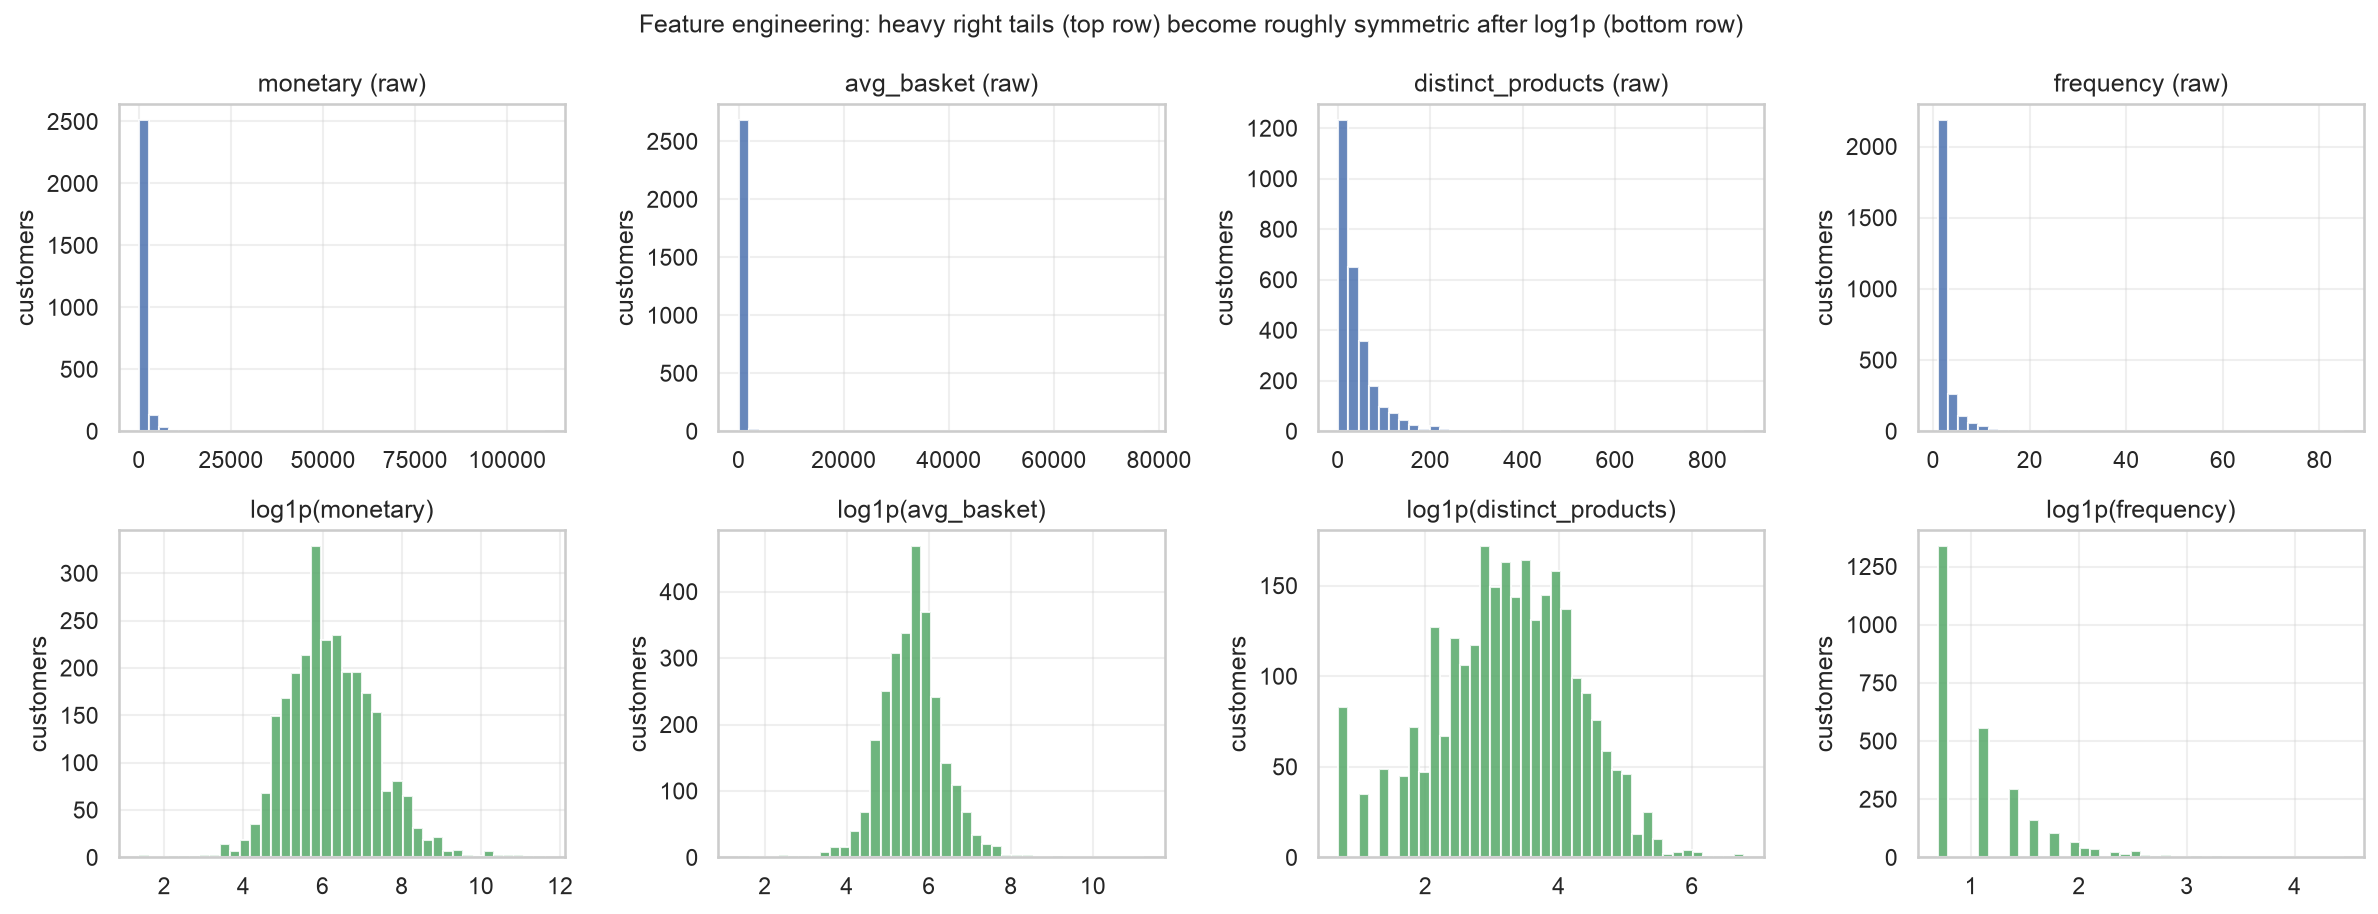

f02_feature_distributions.png written


In [11]:
# ============================================================================
# S2.3  Figure: engineered feature distributions (raw vs log1p)
# ============================================================================
HEAVY_TAILED = ["monetary", "avg_basket", "max_invoice_value", "distinct_products",
                "frequency", "avg_items_per_invoice", "tenure_days"]

SHOW_FEATS = ["monetary", "avg_basket", "distinct_products", "frequency"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.2))
for j, feat in enumerate(SHOW_FEATS):
    axes[0, j].hist(T1[feat].clip(lower=0), bins=40, color="#4C72B0", alpha=0.85)
    axes[0, j].set_title(f"{feat} (raw)")
    axes[0, j].set_ylabel("customers")
    axes[1, j].hist(np.log1p(T1[feat].clip(lower=0)), bins=40, color="#55A868", alpha=0.85)
    axes[1, j].set_title(f"log1p({feat})")
    axes[1, j].set_ylabel("customers")
fig.suptitle("Feature engineering: heavy right tails (top row) become roughly symmetric after log1p (bottom row)", fontsize=12)
fig.tight_layout()
save_fig(fig, "f02_feature_distributions")
print("f02_feature_distributions.png written")

## S3. Similarity and distance analysis

Distance-based methods are only as good as the **metric + transform** pair. We therefore treat
the choice of distance as a modelling decision with evidence:

1. Take the T2 (decision cohort) behavioural features, `log1p` the heavy tails and z-score them
   so that monetary pounds do not dominate counts.
2. Score three candidate distances — **euclidean, cosine, manhattan** — with two independent
   pieces of evidence on the same K=5 K-means solution:
   * **silhouette** (how well separated the clusters are under that metric), and
   * **kNN label agreement** (fit a 5-NN classifier on 70% of the customers using that metric,
     then measure how often its cluster prediction matches the K-means label on the held-out 30%).
3. Use the winning metric for the two business use cases:
   * **lookalike customers** — for 3 high-value customers, find the 5 nearest neighbours
     (prospecting: "find me more customers like this one");
   * **similar products** — item-item cosine similarity on the invoice x product binary matrix
     (substitutes / cross-sell candidates for the assortment).

In [12]:
# ============================================================================
# S3.1  Standardise behavioural features (log1p + StandardScaler)
# ============================================================================
from sklearn.metrics import pairwise_distances


def log_scale(df, feats):
    X = df[feats].astype(float).copy()
    X = np.log1p(X.clip(lower=0))
    scaler = StandardScaler()
    return scaler.fit_transform(X)


X_T2 = log_scale(T2, SNAP_FEATURES)
X_T1 = log_scale(T1, SNAP_FEATURES)
print("T2 distance matrix shape:", X_T2.shape, "| T1:", X_T1.shape)

# a single reference K-means solution (K=5) whose labels are judged under each metric
km_ref = KMeans(n_clusters=5, n_init=10, random_state=RANDOM_STATE).fit(X_T2)
ref_labels = km_ref.labels_
print("reference K=5 cluster sizes:", np.bincount(ref_labels).tolist())

T2 distance matrix shape: (2809, 15) | T1: (2716, 15)
reference K=5 cluster sizes: [426, 755, 532, 580, 516]


In [13]:
# ============================================================================
# S3.2  Compare the three distance metrics
# ============================================================================
rng = np.random.RandomState(RANDOM_STATE)
idx = np.arange(len(X_T2))
rng.shuffle(idx)
split = int(0.7 * len(idx))
train_idx, test_idx = idx[:split], idx[split:]

metric_rows = []
for metric in ["euclidean", "cosine", "manhattan"]:
    sil = silhouette_score(X_T2, ref_labels, metric=metric)
    D = pairwise_distances(X_T2, metric=metric)
    knn = KNeighborsClassifier(n_neighbors=5, metric="precomputed").fit(
        D[np.ix_(train_idx, train_idx)], ref_labels[train_idx]
    )
    pred = knn.predict(D[np.ix_(test_idx, train_idx)])
    agreement = float((pred == ref_labels[test_idx]).mean())
    metric_rows.append(
        {
            "metric": metric,
            "silhouette_k5": round(float(sil), 4),
            "knn_label_agreement": round(agreement, 4),
            "note": "higher silhouette is better; agreement measures label consistency",
        }
    )

df_metric = pd.DataFrame(metric_rows)
df_metric["silhouette_rank"] = df_metric["silhouette_k5"].rank(ascending=False).astype(int)
df_metric["agreement_rank"] = df_metric["knn_label_agreement"].rank(ascending=False).astype(int)
df_metric = df_metric.sort_values("silhouette_k5", ascending=False).reset_index(drop=True)
BEST_METRIC = str(df_metric.loc[0, "metric"])
df_metric["selected"] = df_metric["metric"] == BEST_METRIC

save_table(df_metric, "t03_distance_metrics", "t11_similarity_metric_comparison")
print(df_metric.to_string(index=False))
print()
print(f"chosen distance metric: {BEST_METRIC}"
      "  (best cluster separation; kNN agreement is a tie-break, not the primary criterion)")

SILHOUETTE_BY_METRIC = dict(zip(df_metric["metric"], df_metric["silhouette_k5"]))

   metric  silhouette_k5  knn_label_agreement                                                              note  silhouette_rank  agreement_rank  selected
   cosine         0.3283               0.9359 higher silhouette is better; agreement measures label consistency                1               3      True
manhattan         0.2183               0.9442 higher silhouette is better; agreement measures label consistency                2               1     False
euclidean         0.1844               0.9419 higher silhouette is better; agreement measures label consistency                3               2     False

chosen distance metric: cosine  (best cluster separation; kNN agreement is a tie-break, not the primary criterion)


In [14]:
# ============================================================================
# S3.3  Lookalike customers: 3 high-value customers, top-5 cosine neighbours
# ============================================================================
SIM_T2 = 1.0 - pairwise_distances(X_T2, metric="cosine")  # cosine similarity matrix
np.fill_diagonal(SIM_T2, -1.0)  # never return the customer itself

# three illustrative high-value customers (top monetary value in the decision cohort)
example_positions = np.argsort(-T2["monetary"].to_numpy())[:3]

lookalike_rows = []
for p in example_positions:
    ex = T2.iloc[p]
    order = np.argsort(-SIM_T2[p])[:5]
    for rank, q in enumerate(order, start=1):
        other = T2.iloc[q]
        lookalike_rows.append(
            {
                "example_customer_id": int(ex.CustomerID),
                "example_monetary": round(float(ex.monetary), 2),
                "example_frequency": int(ex.frequency),
                "rank": rank,
                "lookalike_customer_id": int(other.CustomerID),
                "cosine_similarity": round(float(SIM_T2[p, q]), 4),
                "lookalike_monetary": round(float(other.monetary), 2),
                "lookalike_frequency": int(other.frequency),
                "lookalike_recency_days": int(other.recency_days),
            }
        )
df_lookalike = pd.DataFrame(lookalike_rows)
save_table(df_lookalike, "t04_lookalikes")
print("lookalike customers for the three highest-value T2 customers:")
print(df_lookalike.to_string(index=False))

lookalike customers for the three highest-value T2 customers:
 example_customer_id  example_monetary  example_frequency  rank  lookalike_customer_id  cosine_similarity  lookalike_monetary  lookalike_frequency  lookalike_recency_days
               14646         118081.92                 30     1                  14156             0.9877            58890.10                   28                      14
               14646         118081.92                 30     2                  17511             0.9732            37818.61                   14                      14
               14646         118081.92                 30     3                  13098             0.9596            13574.48                   15                      13
               14646         118081.92                 30     4                  13694             0.9593            35141.48                   29                       7
               14646         118081.92                 30     5                  17

In [15]:
# ============================================================================
# S3.4  Similar products: item-item cosine similarity on invoice x product matrix
# ============================================================================
invoices = clean["InvoiceNo"].unique()
products = np.sort(clean["StockCode"].unique())
inv_codes = pd.Categorical(clean["InvoiceNo"], categories=invoices).codes
prod_codes = pd.Categorical(clean["StockCode"], categories=products).codes

M_bin = np.zeros((len(invoices), len(products)), dtype=bool)
M_bin[inv_codes, prod_codes] = True
print(f"invoice x product binary matrix: {M_bin.shape[0]:,} invoices x {M_bin.shape[1]:,} products")

invoice_count = M_bin.sum(axis=0).astype(float)          # invoices containing each product
col_norm = np.sqrt(invoice_count)
col_norm[col_norm == 0] = 1.0
M_norm = M_bin / col_norm

POPULAR = np.argsort(-invoice_count)[:5]                 # five most-sold products
ITEM_SIM = M_norm.T @ M_norm[:, POPULAR]                 # cosine similarity | 3659 x 5

# product descriptions (most frequent non-UNKNOWN description per stock code)
desc_map = (
    clean[clean["Description"] != "UNKNOWN"]
    .groupby("StockCode")["Description"]
    .agg(lambda s: s.value_counts().index[0])
)

similar_rows = []
for j, pop_idx in enumerate(POPULAR):
    base_code = products[pop_idx]
    sims = ITEM_SIM[:, j].copy()
    sims[pop_idx] = -1.0
    top = np.argsort(-sims)[:5]
    for rank, s_idx in enumerate(top, start=1):
        code = products[s_idx]
        co = int((M_bin[:, pop_idx] & M_bin[:, s_idx]).sum())
        similar_rows.append(
            {
                "base_stockcode": base_code,
                "base_description": str(desc_map.get(base_code, "UNKNOWN"))[:45],
                "base_invoices": int(invoice_count[pop_idx]),
                "rank": rank,
                "similar_stockcode": code,
                "similar_description": str(desc_map.get(code, "UNKNOWN"))[:45],
                "cosine_similarity": round(float(sims[s_idx]), 4),
                "co_occurrence_invoices": co,
            }
        )
df_similar = pd.DataFrame(similar_rows)
save_table(df_similar, "t05_similar_products")
print("top-5 similar products for the five most popular products:")
print(df_similar.to_string(index=False))

invoice x product binary matrix: 18,402 invoices x 3,659 products


top-5 similar products for the five most popular products:
base_stockcode                   base_description  base_invoices  rank similar_stockcode                similar_description  cosine_similarity  co_occurrence_invoices
        85123A WHITE HANGING HEART T-LIGHT HOLDER           1978     1             21733   RED HANGING HEART T-LIGHT HOLDER             0.3943                     457
        85123A WHITE HANGING HEART T-LIGHT HOLDER           1978     2             22804    CANDLEHOLDER PINK HANGING HEART             0.3358                     302
        85123A WHITE HANGING HEART T-LIGHT HOLDER           1978     3             82482  WOODEN PICTURE FRAME WHITE FINISH             0.2340                     308
        85123A WHITE HANGING HEART T-LIGHT HOLDER           1978     4             22470              HEART OF WICKER LARGE             0.2312                     291
        85123A WHITE HANGING HEART T-LIGHT HOLDER           1978     5            82494L        WOODEN FRA

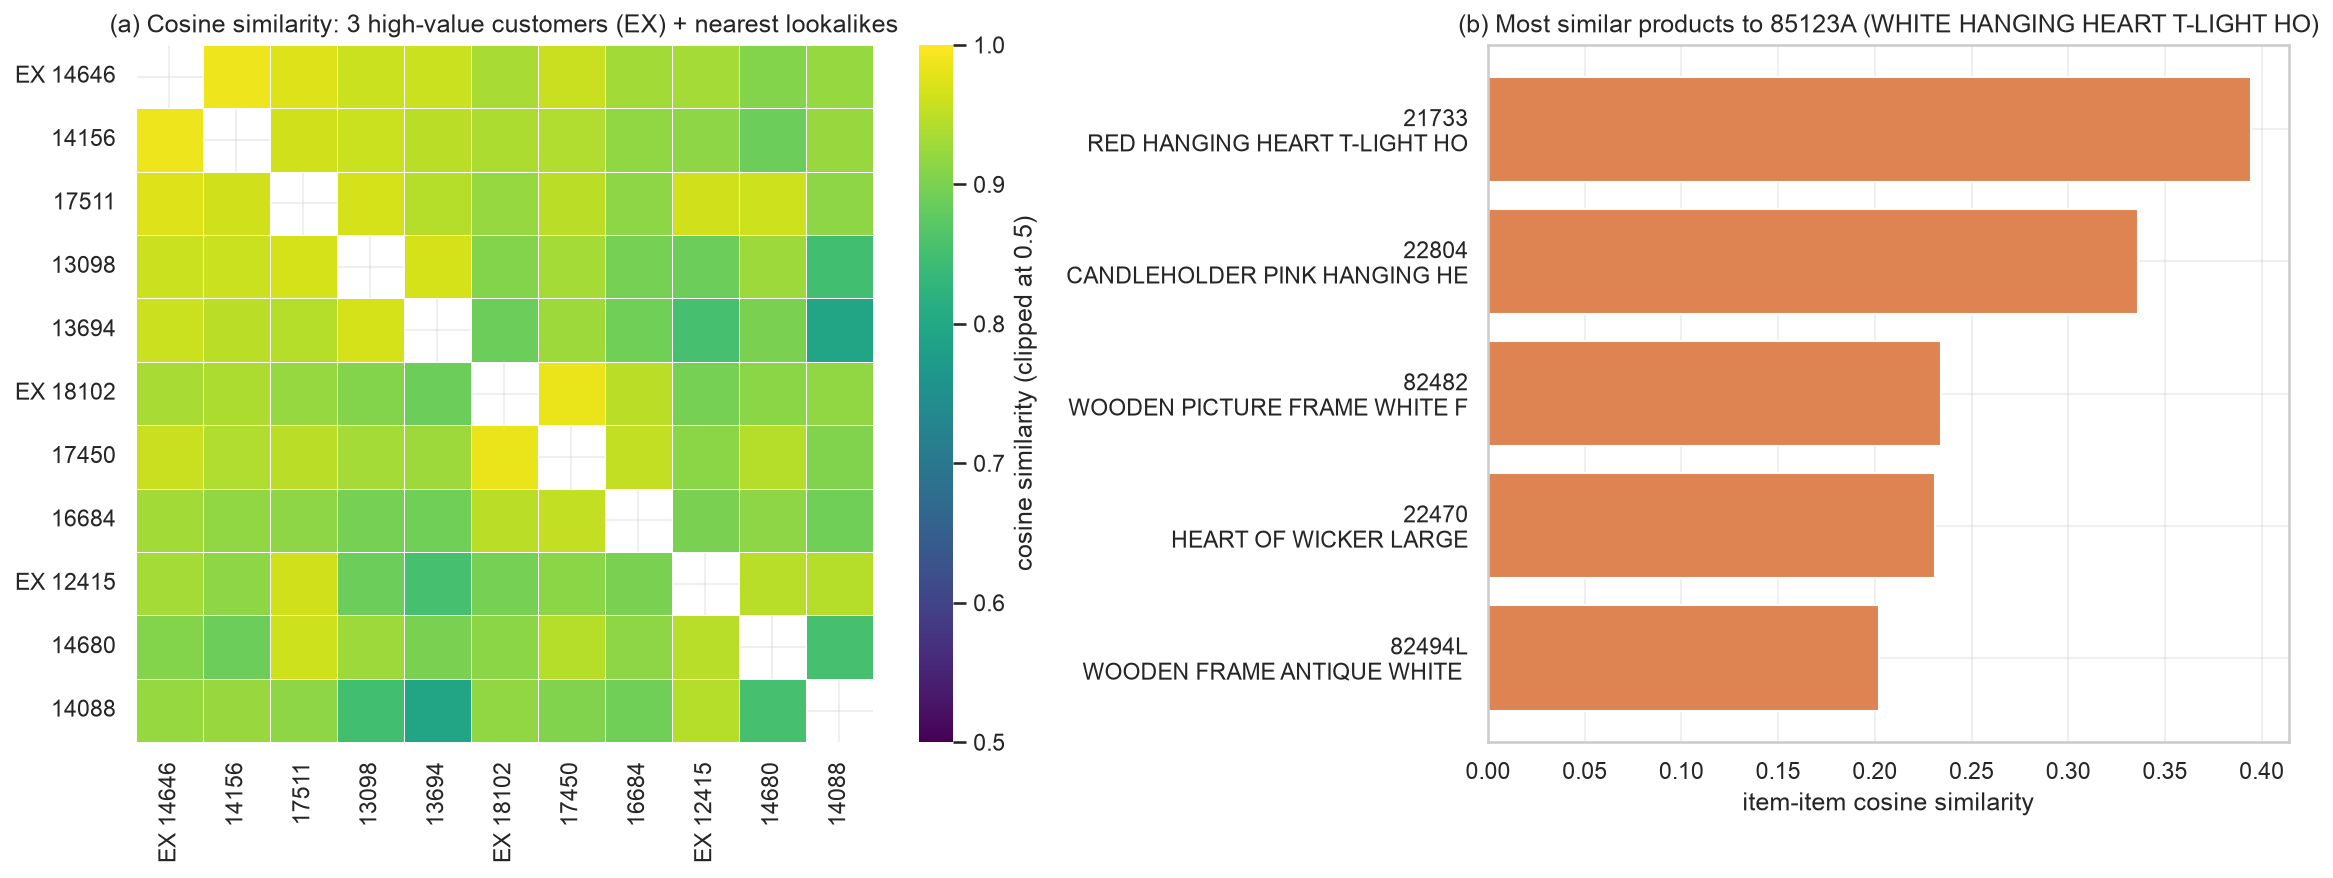

f11_similarity_lookalikes.png written


In [16]:
# ============================================================================
# S3.5  Figure: lookalike heatmap + similar-product example
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.0), gridspec_kw={"width_ratios": [1.15, 1]})

# (a) similarity heatmap: the 3 examples + their nearest neighbours
show_pos = []
labels = []
for p in example_positions:
    if int(p) not in show_pos:
        show_pos.append(int(p))
        labels.append(f"EX {int(T2.iloc[p].CustomerID)}")
    for q in np.argsort(-SIM_T2[p])[:4]:
        if int(q) not in show_pos:
            show_pos.append(int(q))
            labels.append(f"{int(T2.iloc[q].CustomerID)}")
sub = SIM_T2[np.ix_(show_pos, show_pos)].copy()
np.fill_diagonal(sub, np.nan)
sns.heatmap(sub, ax=axes[0], cmap="viridis", vmin=0.5, vmax=1.0,
            xticklabels=labels, yticklabels=labels,
            cbar_kws={"label": "cosine similarity (clipped at 0.5)"},
            linewidths=0.3, linecolor="white")
axes[0].set_title("(a) Cosine similarity: 3 high-value customers (EX) + nearest lookalikes")

# (b) top similar products for the most popular product
base_code = df_similar.iloc[0]["base_stockcode"]
base_desc = df_similar.iloc[0]["base_description"]
top_sim = df_similar[df_similar["base_stockcode"] == base_code].sort_values("cosine_similarity")
axes[1].barh(
    [f"{r.similar_stockcode}\n{str(r.similar_description)[:28]}" for r in top_sim.itertuples()],
    top_sim["cosine_similarity"].values,
    color="#DD8452",
)
axes[1].set_title(f"(b) Most similar products to {base_code} ({base_desc[:30]})")
axes[1].set_xlabel("item-item cosine similarity")
fig.tight_layout()
save_fig(fig, "f11_similarity_lookalikes")
print("f11_similarity_lookalikes.png written")

## S4. Feature engineering and feature selection

By now the raw columns have become 16 behavioural features. Before modelling we need evidence
about **which subset is worth keeping**. Three complementary filters are applied, all fitted on
the **training split only** (a feature-selection step that peeks at validation/test data is a
leakage bug):

1. **Correlation filter** — among any pair with |r| > 0.9, drop the member with the lower mutual
   information with churn (near-duplicate information, e.g. `avg_basket` vs `max_invoice_value`).
2. **Mutual information** (`mutual_info_classif`) — a non-linear, model-free relevance ranking;
   keep the top 12.
3. **Recursive Feature Elimination** (logistic regression, `step=1`) — keep the top 10.

Each stage is scored by **validation PR-AUC** (churn is the minority class we care about, so
PR-AUC is the right headline metric). The winning set is then used by every final model, and the
transformations live **inside a scikit-learn `Pipeline`** so scalers/selectors are refit on each
training fold — no leakage in cross-validation either.

In [17]:
# ============================================================================
# S4.1  Train / validation / test split of T1 (stratified 70/15/15)
# ============================================================================
X_all = T1[MODEL_FEATURES].copy()
y_all = T1["churn"].astype(int).copy()

X_train, X_tmp, y_train, y_tmp = train_test_split(
    X_all, y_all, test_size=0.30, stratify=y_all, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE
)
print(f"train {len(X_train):,} (churn {y_train.mean():.4f})")
print(f"val   {len(X_val):,} (churn {y_val.mean():.4f})")
print(f"test  {len(X_test):,} (churn {y_test.mean():.4f})")


def make_preprocessor():
    return [("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]


def logreg_pipeline(**params):
    return Pipeline(
        make_preprocessor()
        + [("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                        random_state=RANDOM_STATE, **params))]
    )

train 1,901 (churn 0.5045)
val   407 (churn 0.5037)
test  408 (churn 0.5049)


In [18]:
# ============================================================================
# S4.2  Stage 1-2: mutual information ranking + correlation filter
# ============================================================================
mi_all = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
df_mi = pd.DataFrame({"feature": MODEL_FEATURES, "mutual_info": mi_all})
df_mi["mi_rank"] = df_mi["mutual_info"].rank(ascending=False, method="min").astype(int)
df_mi = df_mi.sort_values("mi_rank").reset_index(drop=True)

corr_train = X_train.corr().abs()
upper = corr_train.where(np.triu(np.ones(corr_train.shape)).astype(bool), 0.0)
corr_pairs = [
    (a, b, round(float(corr_train.loc[a, b]), 4))
    for i, a in enumerate(corr_train.columns)
    for b in corr_train.columns[i + 1:]
    if corr_train.loc[a, b] > 0.9
]
print("correlated pairs |r| > 0.9:")
for a, b, r in corr_pairs:
    print(f"   {a} -- {b} : r = {r}")

# drop the lower-MI member of each highly-correlated pair
mi_lookup = dict(zip(df_mi["feature"], df_mi["mutual_info"]))
drop_corr = set()
for a, b, _ in corr_pairs:
    drop_corr.add(a if mi_lookup[a] < mi_lookup[b] else b)
keep_corr = [f for f in MODEL_FEATURES if f not in drop_corr]
df_mi["corr_dropped"] = df_mi["feature"].isin(drop_corr)
print()
print("dropped by correlation filter:", sorted(drop_corr) or "none")
print(f"features remaining: {len(keep_corr)} of {len(MODEL_FEATURES)}")

# MI ranking on the surviving features -> top 12
mi_keep = mutual_info_classif(X_train[keep_corr], y_train, random_state=RANDOM_STATE)
df_mi_keep = pd.DataFrame({"feature": keep_corr, "mutual_info": mi_keep}).sort_values(
    "mutual_info", ascending=False
)
keep_mi = df_mi_keep.head(12)["feature"].tolist()
print()
print("MI ranking (surviving features):")
print(df_mi_keep.round(4).to_string(index=False))
print()
print(f"top-12 by mutual information: {keep_mi}")

correlated pairs |r| > 0.9:
   avg_basket -- max_invoice_value : r = 0.9436

dropped by correlation filter: ['avg_basket']
features remaining: 15 of 16

MI ranking (surviving features):
              feature  mutual_info
      distinct_months       0.1303
            frequency       0.0878
             monetary       0.0842
         avg_gap_days       0.0768
         std_gap_days       0.0705
 revenue_last90_ratio       0.0630
    distinct_products       0.0603
         recency_days       0.0594
    max_invoice_value       0.0548
avg_items_per_invoice       0.0502
        weekend_share       0.0310
          return_rate       0.0298
          tenure_days       0.0141
       avg_unit_price       0.0000
                is_uk       0.0000

top-12 by mutual information: ['distinct_months', 'frequency', 'monetary', 'avg_gap_days', 'std_gap_days', 'revenue_last90_ratio', 'distinct_products', 'recency_days', 'max_invoice_value', 'avg_items_per_invoice', 'weekend_share', 'return_rate']


In [19]:
# ============================================================================
# S4.3  Stage 3: RFE (logistic regression, step=1) + validation PR-AUC comparison
# ============================================================================
rfe_selector = RFE(
    estimator=LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    n_features_to_select=10,
    step=1,
)
rfe_selector.fit(np.log1p(X_train[keep_mi]), y_train)
keep_rfe = [f for f, keep in zip(keep_mi, rfe_selector.support_) if keep]
print(f"RFE selected {len(keep_rfe)} features: {keep_rfe}")

stage_rows = []


def eval_stage(name, feats, note):
    pipe = logreg_pipeline()
    pipe.fit(X_train[feats], y_train)
    proba = pipe.predict_proba(X_val[feats])[:, 1]
    stage_rows.append(
        {
            "stage": name,
            "n_features": len(feats),
            "val_pr_auc": round(float(average_precision_score(y_val, proba)), 4),
            "val_roc_auc": round(float(roc_auc_score(y_val, proba)), 4),
            "note": note,
        }
    )
    return stage_rows[-1]["val_pr_auc"]


eval_stage("all_features", MODEL_FEATURES, "baseline: every engineered feature")
eval_stage("correlation_filter", keep_corr, "removed |r|>0.9 duplicates")
eval_stage("mutual_info_top12", keep_mi, "MI ranking, top 12")
eval_stage("rfe_top10", keep_rfe, "RFE logistic regression, top 10")

df_stage = pd.DataFrame(stage_rows)
save_table(df_stage, "t05b_feature_evidence", "t06_feature_selection")
print(df_stage.to_string(index=False))

# --- deterministic choice of the final feature set --------------------------
# best validation PR-AUC wins; if two stages are within 0.005, prefer the smaller set
best_score = df_stage["val_pr_auc"].max()
near_best = df_stage[df_stage["val_pr_auc"] >= best_score - 0.005]
winner = near_best.sort_values(["n_features", "val_pr_auc"], ascending=[True, False]).iloc[0]
STAGE_TO_FEATURES = {
    "all_features": MODEL_FEATURES,
    "correlation_filter": keep_corr,
    "mutual_info_top12": keep_mi,
    "rfe_top10": keep_rfe,
}
FINAL_FEATURES = STAGE_TO_FEATURES[winner["stage"]]
BEST_STAGE = winner["stage"]
VAL_PR_ALL = float(df_stage.loc[df_stage.stage == "all_features", "val_pr_auc"].iloc[0])
VAL_PR_SELECTED = float(winner["val_pr_auc"])
print()
print(f"winner: {BEST_STAGE} -> {len(FINAL_FEATURES)} features")
print(f"validation PR-AUC: all features = {VAL_PR_ALL:.4f} vs selected = {VAL_PR_SELECTED:.4f}")
print("final feature set:", FINAL_FEATURES)

RFE selected 10 features: ['distinct_months', 'frequency', 'monetary', 'avg_gap_days', 'std_gap_days', 'revenue_last90_ratio', 'max_invoice_value', 'avg_items_per_invoice', 'weekend_share', 'return_rate']
             stage  n_features  val_pr_auc  val_roc_auc                               note
      all_features          16      0.6966       0.7514 baseline: every engineered feature
correlation_filter          15      0.6973       0.7513         removed |r|>0.9 duplicates
 mutual_info_top12          12      0.7032       0.7457                 MI ranking, top 12
         rfe_top10          10      0.7036       0.7468    RFE logistic regression, top 10

winner: rfe_top10 -> 10 features
validation PR-AUC: all features = 0.6966 vs selected = 0.7036
final feature set: ['distinct_months', 'frequency', 'monetary', 'avg_gap_days', 'std_gap_days', 'revenue_last90_ratio', 'max_invoice_value', 'avg_items_per_invoice', 'weekend_share', 'return_rate']


              feature  mutual_info  mi_rank  corr_dropped  in_mi_top12  rfe_selected  retained_final
      distinct_months       0.1092        1         False         True          True            True
            frequency       0.0914        2         False         True          True            True
         avg_gap_days       0.0897        3         False         True          True            True
             monetary       0.0844        4         False         True          True            True
         std_gap_days       0.0682        5         False         True          True            True
    distinct_products       0.0660        6         False         True         False           False
 revenue_last90_ratio       0.0551        7         False         True          True            True
         recency_days       0.0549        8         False         True         False           False
    max_invoice_value       0.0540        9         False         True          True       

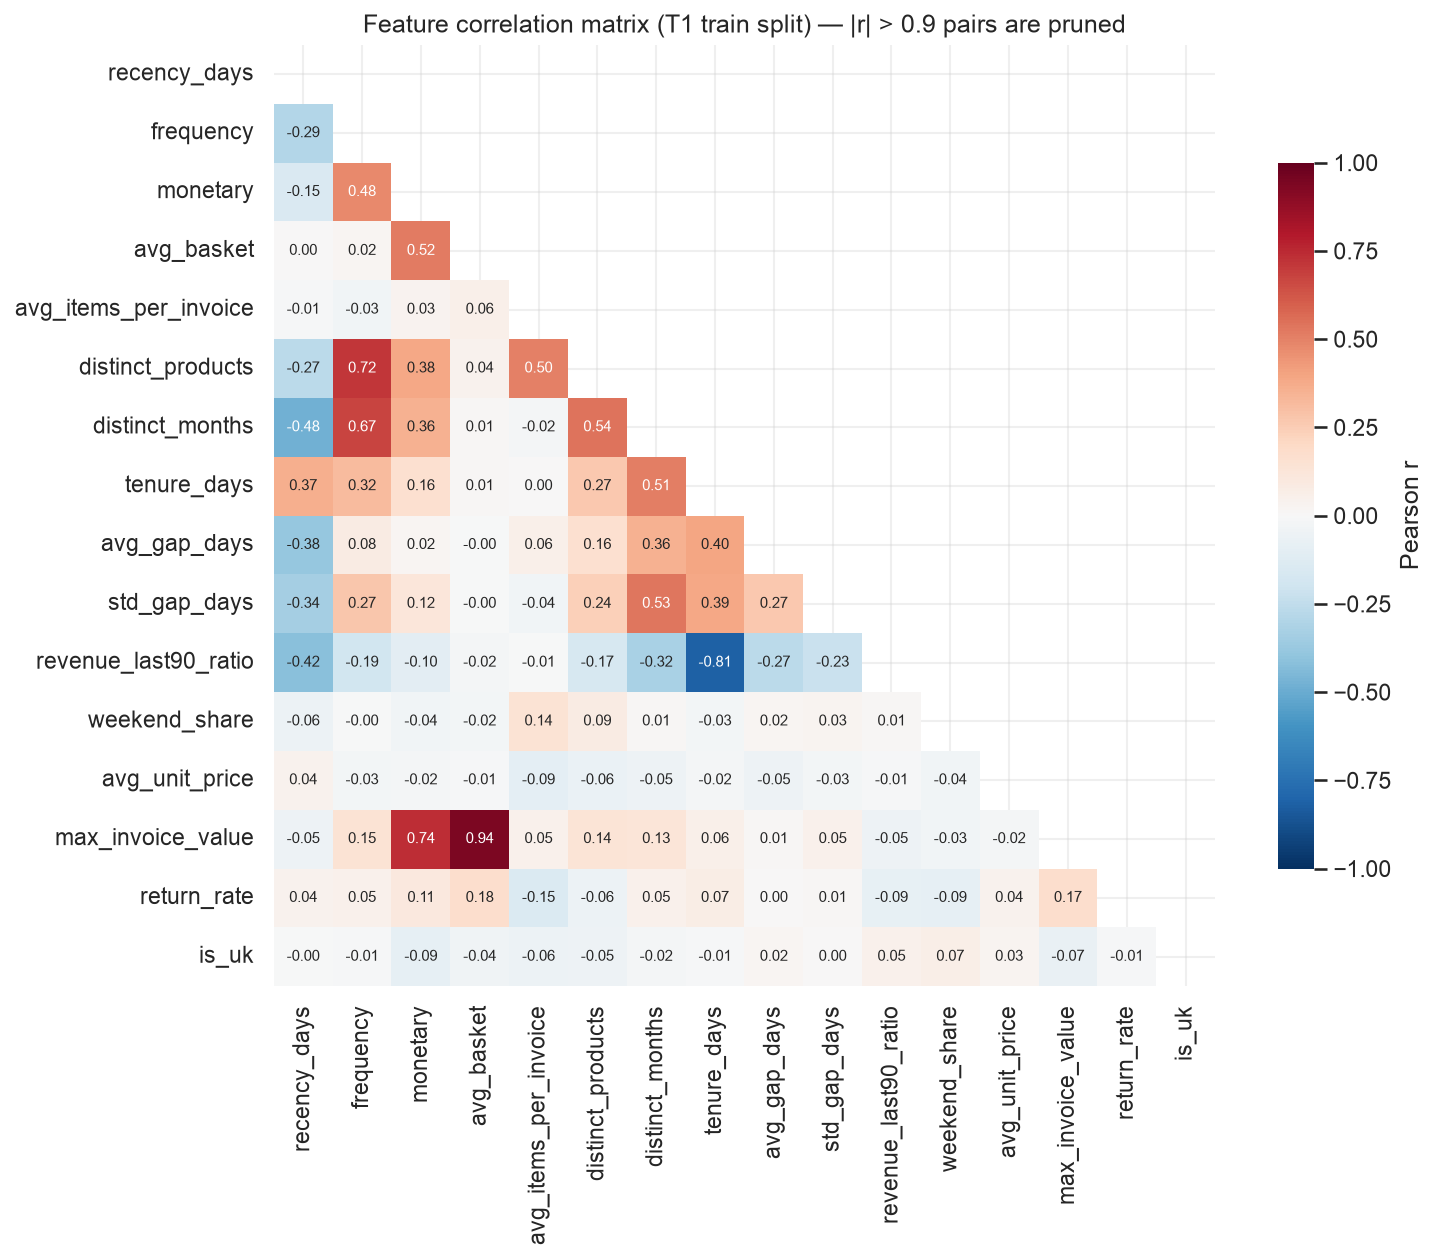

f02_correlation_heatmap.png written


In [20]:
# ============================================================================
# S4.4  Feature-selection evidence tables + correlation heatmap
# ============================================================================
df_fs = df_mi.merge(
    pd.DataFrame({"feature": keep_mi, "in_mi_top12": True}), on="feature", how="left"
)
df_fs["in_mi_top12"] = df_fs["in_mi_top12"].fillna(False).astype(bool)
df_fs["rfe_selected"] = df_fs["feature"].isin(keep_rfe)
df_fs["retained_final"] = df_fs["feature"].isin(FINAL_FEATURES)
df_fs = df_fs.sort_values("mi_rank")[
    ["feature", "mutual_info", "mi_rank", "corr_dropped", "in_mi_top12", "rfe_selected", "retained_final"]
]
df_fs["mutual_info"] = df_fs["mutual_info"].round(4)
save_table(df_fs, "t05_feature_selection")
print(df_fs.to_string(index=False))

fig, ax = plt.subplots(figsize=(10.5, 8.5))
corr_full = X_train[MODEL_FEATURES].corr()
mask = np.triu(np.ones_like(corr_full, dtype=bool))
sns.heatmap(
    corr_full, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"size": 7}, square=True,
    cbar_kws={"shrink": 0.75, "label": "Pearson r"}, ax=ax,
)
ax.set_title("Feature correlation matrix (T1 train split) — |r| > 0.9 pairs are pruned")
fig.tight_layout()
save_fig(fig, "f02_correlation_heatmap")
print("f02_correlation_heatmap.png written")

## S5. Customer segmentation with K-means (T2 decision cohort)

Segmentation answers **"who are our customers?"** — the input to the action table, not a goal in
itself. We cluster the **T2 cohort** (the customers we would act on today) on the 15 behavioural
features (`log1p` + z-score; `is_uk` is excluded because it is a static market flag and would
distort distances).

**Choosing K is an evidence-based decision, not a guess:**
* **Elbow** (inertia) for the scale of the solution,
* **Silhouette** under the winning distance metric (S3) for separation,
* **Bootstrap stability** — 10 resamples of 80% of customers, ARI between the resampled solution
  and the full-data solution. A segment we cannot reproduce is not a segment we can act on.
* **Business interpretability** — every segment must be big enough to target (≥10% of the base)
  and map to a distinct RFM story.

The decision rule (coded below): among K = 4–6 (K = 2–3 are too coarse for a five-tier RFM
framework; K ≥ 7 produces tiny, unstable segments), keep the most stable solution with
silhouette ≥ 0.30 and no segment below 10% of customers. Segments are then named by their RFM
ranking.

In [21]:
# ============================================================================
# S5.1  K scan: inertia, silhouette (best metric) and bootstrap stability
# ============================================================================
X_cl = log_scale(T2, SNAP_FEATURES)
full_ref = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_cl)
    full_ref[k] = km
    print(f"K={k}: inertia={km.inertia_:,.1f}  sizes={np.bincount(km.labels_).tolist()}")

n_stab = 10
k_rows = []
for k in range(2, 9):
    km = full_ref[k]
    labels_full = km.labels_
    aris = []
    for s in range(n_stab):
        rs = np.random.RandomState(RANDOM_STATE + s)
        sub = rs.choice(len(X_cl), int(0.8 * len(X_cl)), replace=False)
        km_sub = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE + s).fit(X_cl[sub])
        aris.append(adjusted_rand_score(labels_full[sub], km_sub.labels_))
    sizes = np.bincount(labels_full)
    k_rows.append(
        {
            "k": k,
            "inertia": round(float(km.inertia_), 1),
            "silhouette": round(float(silhouette_score(X_cl, labels_full, metric=BEST_METRIC)), 4),
            "ari_mean": round(float(np.mean(aris)), 4),
            "ari_std": round(float(np.std(aris)), 4),
            "min_segment_size": int(sizes.min()),
            "min_segment_share": round(float(sizes.min() / len(X_cl)), 4),
            "max_segment_size": int(sizes.max()),
        }
    )
df_k = pd.DataFrame(k_rows).set_index("k")
print()
print(df_k.to_string())

K=2: inertia=30,969.4  sizes=[1163, 1646]
K=3: inertia=27,429.8  sizes=[1061, 818, 930]
K=4: inertia=24,859.7  sizes=[580, 696, 794, 739]
K=5: inertia=22,890.9  sizes=[426, 755, 532, 580, 516]


K=6: inertia=21,498.4  sizes=[71, 739, 508, 429, 573, 489]


K=7: inertia=20,279.8  sizes=[64, 362, 747, 450, 205, 458, 523]
K=8: inertia=19,175.3  sizes=[448, 528, 372, 482, 64, 442, 270, 203]



   inertia  silhouette  ari_mean  ari_std  min_segment_size  min_segment_share  max_segment_size
k                                                                                               
2  30969.4      0.4223    0.9878   0.0071              1163             0.4140              1646
3  27429.8      0.3167    0.9055   0.1919               818             0.2912              1061
4  24859.7      0.3470    0.8199   0.1195               580             0.2065               794
5  22890.9      0.3283    0.9699   0.0139               426             0.1517               755
6  21498.4      0.3232    0.9137   0.0771                71             0.0253               739
7  20279.8      0.3393    0.8667   0.1026                64             0.0228               747
8  19175.3      0.2336    0.8290   0.1392                64             0.0228               528


In [22]:
# ============================================================================
# S5.2  Choose K with the pre-registered decision rule
# ============================================================================
candidate_ks = [k for k in [4, 5, 6]
                if df_k.loc[k, "min_segment_share"] >= 0.10 and df_k.loc[k, "silhouette"] >= 0.30]
if not candidate_ks:  # defensive fallback, should not trigger on this data
    candidate_ks = [int(df_k["silhouette"].idxmax())]
K_CHOSEN = int(max(candidate_ks, key=lambda k: (df_k.loc[k, "ari_mean"], df_k.loc[k, "silhouette"])))
df_k["selected"] = df_k.index == K_CHOSEN
save_table(df_k.reset_index(), "t06_cluster_metrics")
print("eligible K values:", candidate_ks)
print(f"K chosen = {K_CHOSEN}  (silhouette={df_k.loc[K_CHOSEN,'silhouette']:.4f}, "
      f"stability ARI={df_k.loc[K_CHOSEN,'ari_mean']:.4f})")

km_final = KMeans(n_clusters=K_CHOSEN, n_init=25, random_state=RANDOM_STATE).fit(X_cl)
T2 = T2.copy()
T2["segment_id"] = km_final.labels_
SILHOUETTE_FINAL = float(silhouette_score(X_cl, km_final.labels_, metric=BEST_METRIC))
ARI_STABILITY = float(df_k.loc[K_CHOSEN, "ari_mean"])
ARI_STABILITY_STD = float(df_k.loc[K_CHOSEN, "ari_std"])
print(f"final silhouette = {SILHOUETTE_FINAL:.4f}")

eligible K values: [4, 5]
K chosen = 5  (silhouette=0.3283, stability ARI=0.9699)
final silhouette = 0.3279


In [23]:
# ============================================================================
# S5.3  Name segments by RFM rank and build the profile table
# ============================================================================
prof_num = T2.groupby("segment_id")[SNAP_FEATURES].mean()
by_money = prof_num["monetary"].sort_values(ascending=False).index.tolist()

SEGMENT_NAMES = {
    by_money[0]: "Champions",
    by_money[1]: "Loyal",
    by_money[-1]: "Hibernating",
}
middle = [s for s in by_money if s not in SEGMENT_NAMES]
middle = sorted(middle, key=lambda s: prof_num.loc[s, "recency_days"])
SEGMENT_NAMES[middle[0]] = "Potential"
SEGMENT_NAMES[middle[1]] = "At-risk"

T2["segment"] = T2["segment_id"].map(SEGMENT_NAMES)
SEGMENT_ORDER = ["Champions", "Loyal", "Potential", "At-risk", "Hibernating"]
print("segment naming (by RFM rank):", SEGMENT_NAMES)

profile = (
    T2.groupby("segment")[SNAP_FEATURES]
    .mean()
    .reindex(SEGMENT_ORDER)
    .round(2)
)
profile.insert(0, "n", T2.groupby("segment").size().reindex(SEGMENT_ORDER).values)
profile.insert(1, "share_pct", (profile["n"] / len(T2) * 100).round(2))
profile["is_uk_share"] = (
    T2.groupby("segment")["is_uk"].mean().reindex(SEGMENT_ORDER).round(3).values
)
profile["actual_churn_rate"] = (
    T2.groupby("segment")["churn"].mean().reindex(SEGMENT_ORDER).round(4).values
)
profile = profile.reset_index()
save_table(profile, "t07_segment_profiles")
print()
print(profile.to_string(index=False))
SEGMENT_SIZES = dict(zip(profile["segment"], profile["n"].astype(int)))
print()
print("segment sizes:", SEGMENT_SIZES)

segment naming (by RFM rank): {2: 'Champions', 0: 'Loyal', 4: 'Hibernating', 3: 'Potential', 1: 'At-risk'}

    segment   n  share_pct  recency_days  frequency  monetary  avg_basket  avg_items_per_invoice  distinct_products  distinct_months  tenure_days  avg_gap_days  std_gap_days  revenue_last90_ratio  weekend_share  avg_unit_price  max_invoice_value  return_rate  is_uk_share  actual_churn_rate
  Champions 755      26.88         25.89       6.55   3293.01      439.38                  21.00              84.24             3.94       216.30         37.49         16.46                  1.64           0.13            3.03             873.30         0.03        0.905             0.1219
      Loyal 582      20.72         55.99       2.29    900.80      397.37                  21.99              43.23             2.08       182.22         70.35          0.78                  2.53           0.15            4.02             556.55         0.02        0.895             0.3351
  Potential 520    

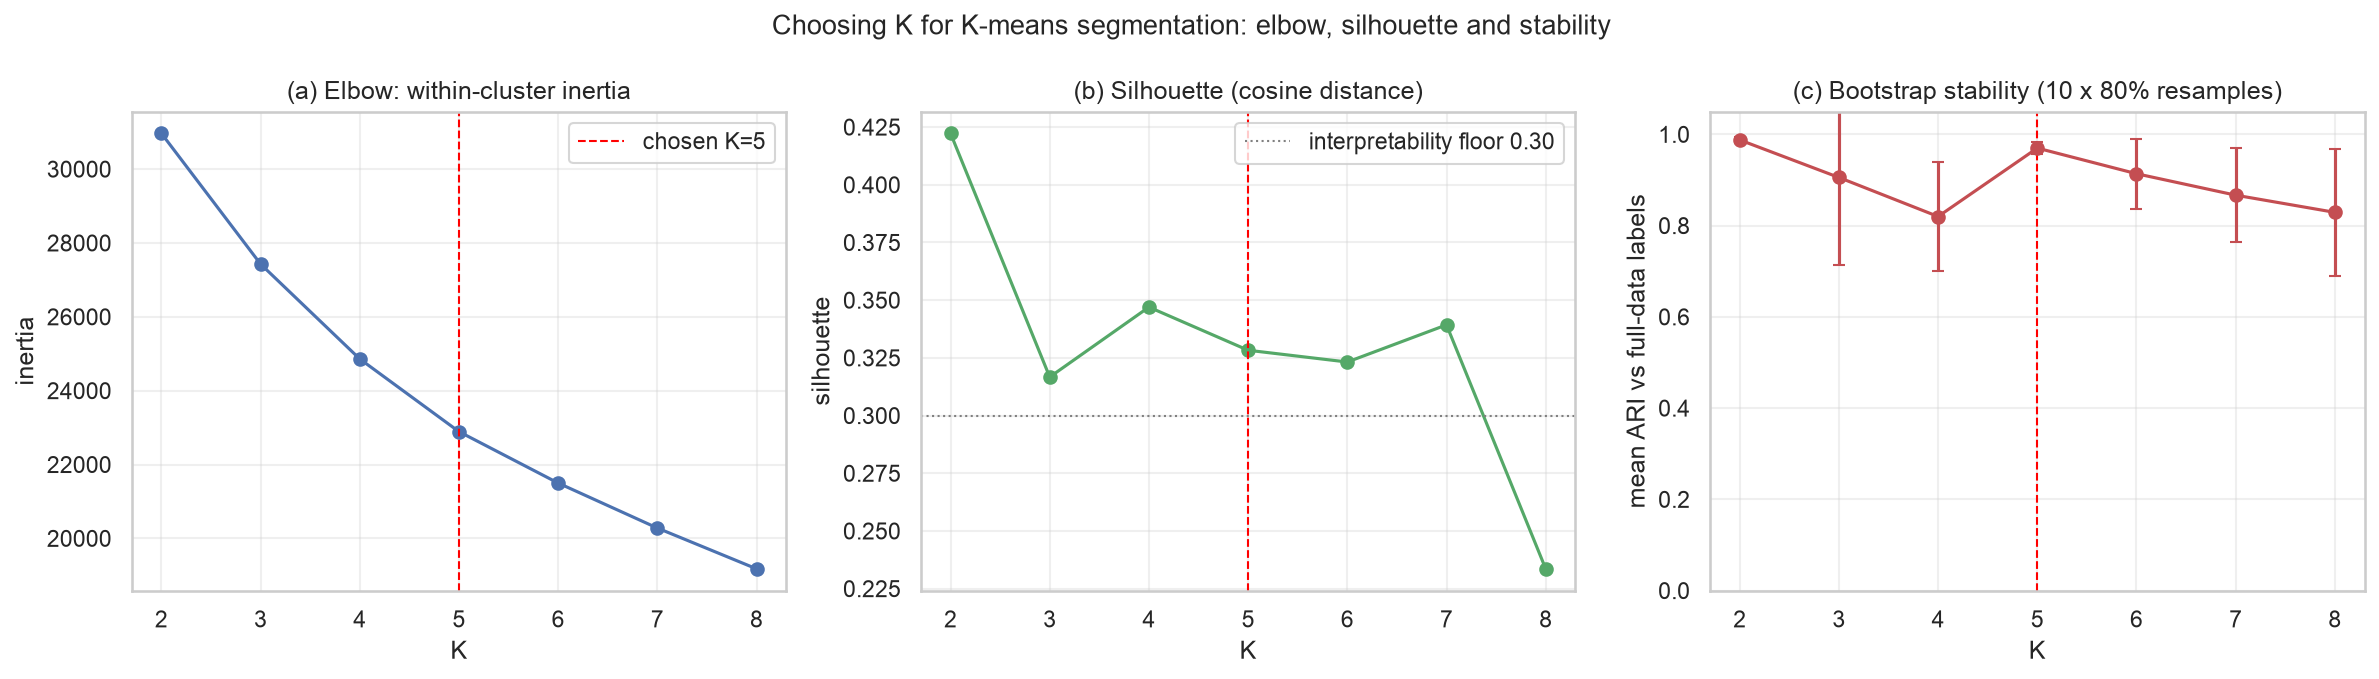

PCA explained variance: PC1=0.365, PC2=0.151


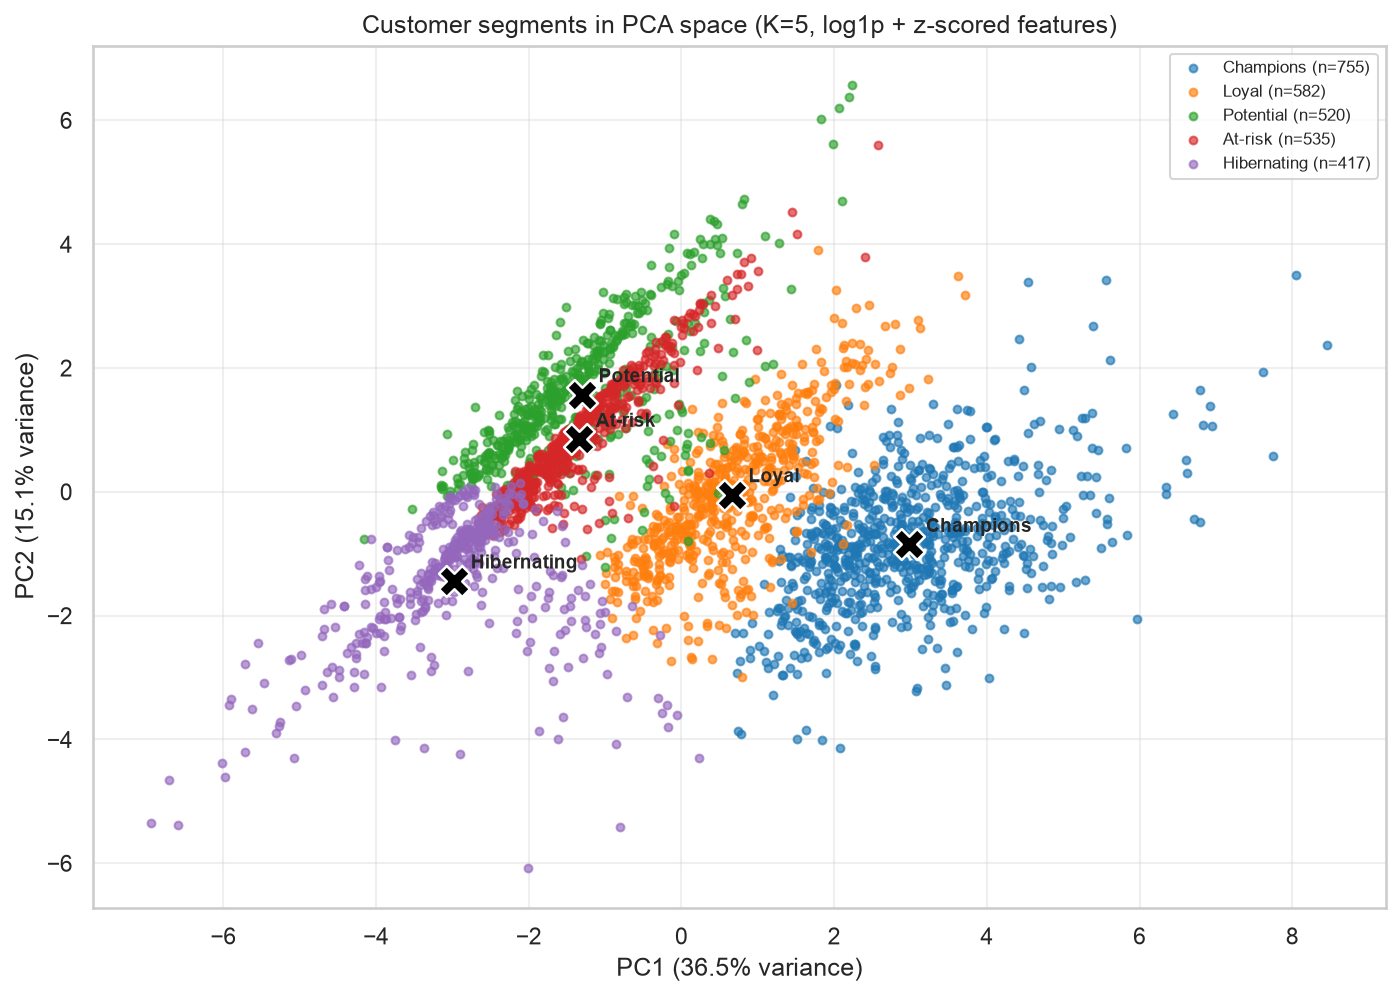

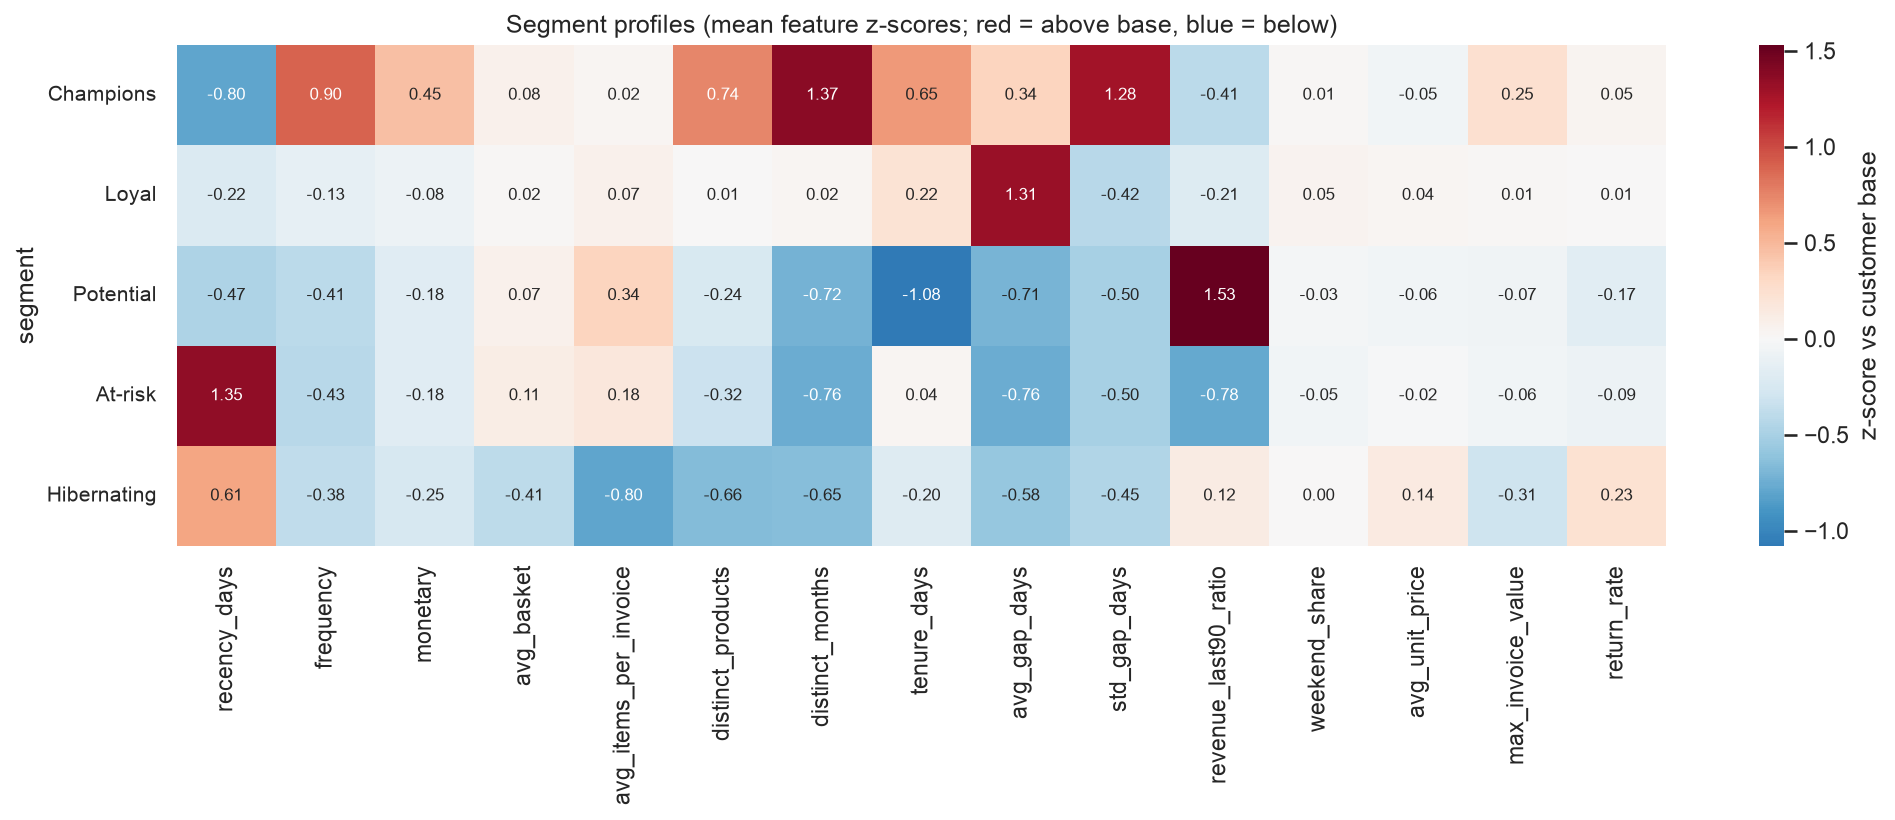

cluster figures written


In [24]:
# ============================================================================
# S5.4  Figures: elbow/silhouette/stability, PCA scatter, profile heatmap
# ============================================================================
# --- f04_elbow_silhouette / f03_elbow_silhouette ---------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
axes[0].plot(df_k.index, df_k["inertia"], marker="o", color="#4C72B0")
axes[0].set_title("(a) Elbow: within-cluster inertia")
axes[0].set_xlabel("K")
axes[0].set_ylabel("inertia")
axes[0].axvline(K_CHOSEN, color="red", ls="--", lw=1, label=f"chosen K={K_CHOSEN}")
axes[0].legend()

axes[1].plot(df_k.index, df_k["silhouette"], marker="o", color="#55A868")
axes[1].set_title(f"(b) Silhouette ({BEST_METRIC} distance)")
axes[1].set_xlabel("K")
axes[1].set_ylabel("silhouette")
axes[1].axvline(K_CHOSEN, color="red", ls="--", lw=1)
axes[1].axhline(0.30, color="grey", ls=":", lw=1, label="interpretability floor 0.30")
axes[1].legend()

axes[2].errorbar(df_k.index, df_k["ari_mean"], yerr=df_k["ari_std"], marker="o",
                 capsize=3, color="#C44E52")
axes[2].set_title("(c) Bootstrap stability (10 x 80% resamples)")
axes[2].set_xlabel("K")
axes[2].set_ylabel("mean ARI vs full-data labels")
axes[2].set_ylim(0, 1.05)
axes[2].axvline(K_CHOSEN, color="red", ls="--", lw=1)
fig.suptitle("Choosing K for K-means segmentation: elbow, silhouette and stability", fontsize=13)
fig.tight_layout()
save_fig(fig, "f04_elbow_silhouette", "f03_elbow_silhouette")

# --- f06_cluster_pca / f04_cluster_pca -------------------------------------------
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_cl)
X_pca = pca.transform(X_cl)
PCA_VAR = [float(v) for v in pca.explained_variance_ratio_]
print(f"PCA explained variance: PC1={PCA_VAR[0]:.3f}, PC2={PCA_VAR[1]:.3f}")

fig, ax = plt.subplots(figsize=(9.5, 6.8))
palette = dict(zip(SEGMENT_ORDER, sns.color_palette("tab10", len(SEGMENT_ORDER))))
for seg in SEGMENT_ORDER:
    m = T2["segment"] == seg
    ax.scatter(X_pca[m.values, 0], X_pca[m.values, 1], s=14, alpha=0.65,
               label=f"{seg} (n={int(m.sum())})", color=palette[seg])
for sid, seg in SEGMENT_NAMES.items():
    c = X_pca[km_final.labels_ == sid].mean(axis=0)
    ax.scatter(c[0], c[1], marker="X", s=220, c="black", edgecolors="white", linewidths=1.2)
    ax.annotate(seg, (c[0], c[1]), textcoords="offset points", xytext=(8, 6),
                fontsize=9, fontweight="bold")
ax.set_xlabel(f"PC1 ({PCA_VAR[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({PCA_VAR[1]*100:.1f}% variance)")
ax.set_title(f"Customer segments in PCA space (K={K_CHOSEN}, log1p + z-scored features)")
ax.legend(loc="best", fontsize=8)
fig.tight_layout()
save_fig(fig, "f06_cluster_pca", "f04_cluster_pca")

# --- f05_segment_profiles: z-scored profile heatmap -------------------------------
prof_seg = T2.groupby("segment")[SNAP_FEATURES].mean().reindex(SEGMENT_ORDER)
z = (prof_seg - T2[SNAP_FEATURES].mean()) / T2[SNAP_FEATURES].std(ddof=0)
fig, ax = plt.subplots(figsize=(13.8, 5.6))
sns.heatmap(z, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 8},
            cbar_kws={"label": "z-score vs customer base"}, ax=ax)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)
ax.set_title("Segment profiles (mean feature z-scores; red = above base, blue = below)")
ax.set_ylabel("segment")
fig.tight_layout()
save_fig(fig, "f05_segment_profiles")
print("cluster figures written")

## S6. Churn classification and evaluation

**Design.** Three model families of increasing flexibility — logistic regression (interpretable
linear baseline), decision tree (rule-based, depth-limited), random forest (400 trees,
`class_weight='balanced_subsample'`) — are tuned on the **validation split**, then evaluated on
two independent views:

* **T1 held-out test** (same time period, unseen customers),
* **T2 out-of-time** (the *next* 3-month cohort — the honest test for deployment).

**Rigour rules followed here**
* 5-fold `StratifiedKFold` CV on the training split → mean ± std ROC-AUC and PR-AUC.
* Hyper-parameter selection on **validation PR-AUC** (churn is the minority class we must catch).
* All transforms (log1p, scaling, feature selection) fit **inside the pipeline on training folds** —
  no leakage.
* Beyond accuracy we report **PR-AUC, Brier score, and top-10%-of-cohort precision/recall/lift**,
  because the business action is "call the top 10% of the base", not "label everyone".
* **Threshold analysis**: the F1-optimal threshold is compared with a campaign-capacity threshold
  (the top 10% by predicted risk). This exposes the precision/recall trade-off the campaign team
  would actually face.

In [25]:
# ============================================================================
# S6.1  Model builders and small, honest grids
# ============================================================================
def build_model(name, **params):
    if name == "logreg":
        pipe = Pipeline(make_preprocessor() + [("model", LogisticRegression(
            class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))])
    elif name == "decision_tree":
        pipe = Pipeline([("log", FunctionTransformer(np.log1p)), ("model", DecisionTreeClassifier(
            class_weight="balanced", random_state=RANDOM_STATE))])
    elif name == "random_forest":
        pipe = Pipeline([("log", FunctionTransformer(np.log1p)), ("model", RandomForestClassifier(
            n_estimators=400, class_weight="balanced_subsample", max_features="sqrt",
            n_jobs=-1, random_state=RANDOM_STATE))])
    else:
        raise ValueError(name)
    return pipe.set_params(**params)


MODEL_GRIDS = {
    "logreg": [{"model__C": c} for c in [0.01, 0.1, 1.0, 10.0]],
    "decision_tree": [{"model__max_depth": d} for d in [3, 4, 5, 6, 8]],
    "random_forest": [{"model__min_samples_leaf": m} for m in [1, 3, 5]],
}

Xtr = X_train[FINAL_FEATURES]
Xva = X_val[FINAL_FEATURES]
Xte = X_test[FINAL_FEATURES]
X_T2 = T2[FINAL_FEATURES]

TUNED = {}
TUNE_ROWS = []
for name, grid in MODEL_GRIDS.items():
    best = None
    for params in grid:
        pipe = build_model(name, **params).fit(Xtr, y_train)
        proba = pipe.predict_proba(Xva)[:, 1]
        pr = float(average_precision_score(y_val, proba))
        roc = float(roc_auc_score(y_val, proba))
        TUNE_ROWS.append({"model": name, "params": json.dumps(params), "val_pr_auc": round(pr, 4),
                          "val_roc_auc": round(roc, 4)})
        if best is None or pr > best[0]:
            best = (pr, params)
    TUNED[name] = best[1]
    print(f"{name:14s} best params {best[1]}  val PR-AUC {best[0]:.4f}")
df_tune = pd.DataFrame(TUNE_ROWS)
print()
print(df_tune.to_string(index=False))

logreg         best params {'model__C': 0.01}  val PR-AUC 0.7079
decision_tree  best params {'model__max_depth': 3}  val PR-AUC 0.6642


random_forest  best params {'model__min_samples_leaf': 5}  val PR-AUC 0.6683

        model                         params  val_pr_auc  val_roc_auc
       logreg             {"model__C": 0.01}      0.7079       0.7501
       logreg              {"model__C": 0.1}      0.7040       0.7471
       logreg              {"model__C": 1.0}      0.7036       0.7468
       logreg             {"model__C": 10.0}      0.7042       0.7471
decision_tree        {"model__max_depth": 3}      0.6642       0.7152
decision_tree        {"model__max_depth": 4}      0.6634       0.7148
decision_tree        {"model__max_depth": 5}      0.6382       0.7076
decision_tree        {"model__max_depth": 6}      0.6405       0.6902
decision_tree        {"model__max_depth": 8}      0.6371       0.6960
random_forest {"model__min_samples_leaf": 1}      0.6381       0.6921
random_forest {"model__min_samples_leaf": 3}      0.6600       0.7207
random_forest {"model__min_samples_leaf": 5}      0.6683       0.7280


logreg         CV ROC-AUC 0.7593 +/- 0.0217 | PR-AUC 0.7148 +/- 0.0219
decision_tree  CV ROC-AUC 0.7397 +/- 0.0179 | PR-AUC 0.6844 +/- 0.0149


random_forest  CV ROC-AUC 0.7505 +/- 0.0220 | PR-AUC 0.7045 +/- 0.0244


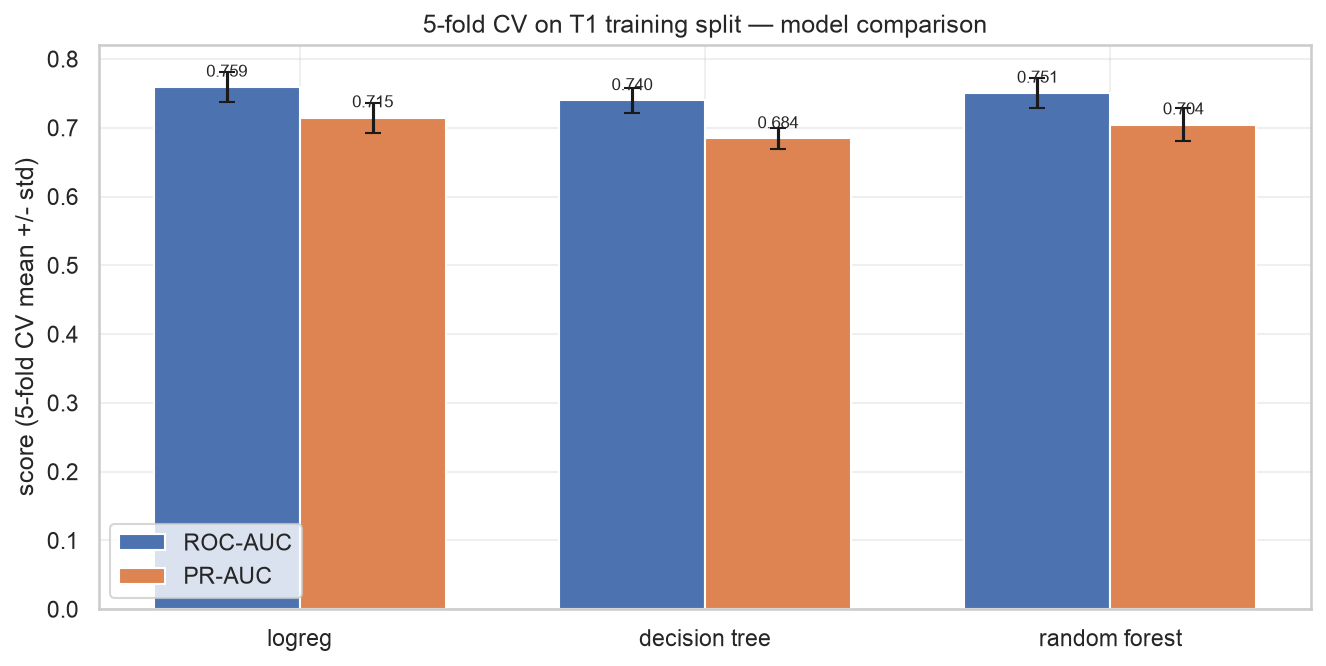

f07_cv_model_comparison.png written


In [26]:
# ============================================================================
# S6.2  5-fold stratified CV on the training split (mean +/- std)
# ============================================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV_RESULTS = {}
for name in MODEL_GRIDS:
    pipe = build_model(name, **TUNED[name])
    scores = cross_validate(
        pipe, Xtr, y_train, cv=cv,
        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"},
        n_jobs=1,
    )
    CV_RESULTS[name] = {
        "auc_mean": float(scores["test_roc_auc"].mean()),
        "auc_std": float(scores["test_roc_auc"].std()),
        "pr_auc_mean": float(scores["test_pr_auc"].mean()),
        "pr_auc_std": float(scores["test_pr_auc"].std()),
    }
    print(f"{name:14s} CV ROC-AUC {CV_RESULTS[name]['auc_mean']:.4f} "
          f"+/- {CV_RESULTS[name]['auc_std']:.4f} | PR-AUC {CV_RESULTS[name]['pr_auc_mean']:.4f} "
          f"+/- {CV_RESULTS[name]['pr_auc_std']:.4f}")

# figure: CV comparison
fig, ax = plt.subplots(figsize=(9, 4.6))
names = list(CV_RESULTS)
x = np.arange(len(names))
w = 0.36
ax.bar(x - w / 2, [CV_RESULTS[n]["auc_mean"] for n in names], w,
       yerr=[CV_RESULTS[n]["auc_std"] for n in names], capsize=4,
       label="ROC-AUC", color="#4C72B0")
ax.bar(x + w / 2, [CV_RESULTS[n]["pr_auc_mean"] for n in names], w,
       yerr=[CV_RESULTS[n]["pr_auc_std"] for n in names], capsize=4,
       label="PR-AUC", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels([n.replace("_", " ") for n in names])
ax.set_ylabel("score (5-fold CV mean +/- std)")
ax.set_title("5-fold CV on T1 training split — model comparison")
ax.legend()
for i, n in enumerate(names):
    ax.text(i - w / 2, CV_RESULTS[n]["auc_mean"] + 0.015, f"{CV_RESULTS[n]['auc_mean']:.3f}",
            ha="center", fontsize=8)
    ax.text(i + w / 2, CV_RESULTS[n]["pr_auc_mean"] + 0.015, f"{CV_RESULTS[n]['pr_auc_mean']:.3f}",
            ha="center", fontsize=8)
fig.tight_layout()
save_fig(fig, "f07_cv_model_comparison")
print("f07_cv_model_comparison.png written")

In [27]:
# ============================================================================
# S6.3  Fit final models, evaluate on T1 test and T2 out-of-time
# ============================================================================
def full_metrics(y_true, y_prob, capacity=0.10):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    pred = (y_prob >= 0.5).astype(int)
    k = max(1, int(np.ceil(capacity * len(y_prob))))
    top = np.argsort(-y_prob)[:k]
    top_prec = float(y_true[top].mean())
    base_rate = float(y_true.mean())
    return {
        "auc": float(roc_auc_score(y_true, y_prob)),
        "pr_auc": float(average_precision_score(y_true, y_prob)),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "top10_precision": top_prec,
        "top10_recall": float(y_true[top].sum() / y_true.sum()),
        "lift10": float(top_prec / base_rate),
        "brier": float(brier_score_loss(y_true, y_prob)),
    }


FINAL_MODELS = {}
PROBA = {}
ALL_METRICS = {"T1_test": {}, "T2_oot": {}}
for name in MODEL_GRIDS:
    pipe = build_model(name, **TUNED[name]).fit(Xtr, y_train)
    FINAL_MODELS[name] = pipe
    PROBA[("T1_test", name)] = pipe.predict_proba(Xte)[:, 1]
    PROBA[("T2_oot", name)] = pipe.predict_proba(X_T2)[:, 1]
    ALL_METRICS["T1_test"][name] = full_metrics(y_test, PROBA[("T1_test", name)])
    ALL_METRICS["T2_oot"][name] = full_metrics(T2["churn"], PROBA[("T2_oot", name)])

rows = []
for cohort in ["T1_test", "T2_oot"]:
    for name in MODEL_GRIDS:
        row = {"model": name, "cohort": cohort}
        row.update({k: round(v, 4) for k, v in ALL_METRICS[cohort][name].items()})
        rows.append(row)
df_metrics = pd.DataFrame(rows)
save_table(df_metrics, "t08_model_metrics")
print(df_metrics.to_string(index=False))

# choose the deployment model on validation PR-AUC (never on test)
VAL_PR = {}
for name in MODEL_GRIDS:
    pipe = build_model(name, **TUNED[name]).fit(Xtr, y_train)
    VAL_PR[name] = float(average_precision_score(y_val, pipe.predict_proba(Xva)[:, 1]))
BEST_MODEL = max(VAL_PR, key=VAL_PR.get)
print()
print("validation PR-AUC by model:", {k: round(v, 4) for k, v in VAL_PR.items()})
print("selected (deployment) model:", BEST_MODEL)

        model  cohort    auc  pr_auc     f1  precision  recall  top10_precision  top10_recall  lift10  brier
       logreg T1_test 0.7227  0.6744 0.6939     0.6511  0.7427           0.6829        0.1359  1.3526 0.2100
decision_tree T1_test 0.6827  0.6325 0.6803     0.6383  0.7282           0.6341        0.1262  1.2560 0.2221
random_forest T1_test 0.7216  0.6684 0.6895     0.6509  0.7330           0.6585        0.1311  1.3043 0.2120
       logreg  T2_oot 0.7392  0.5947 0.6423     0.5608  0.7516           0.6690        0.1692  1.6916 0.2076
decision_tree  T2_oot 0.7095  0.5518 0.6376     0.5512  0.7561           0.6370        0.1611  1.6106 0.2164
random_forest  T2_oot 0.7323  0.5813 0.6475     0.5584  0.7705           0.6263        0.1584  1.5836 0.2133



validation PR-AUC by model: {'logreg': 0.7079, 'decision_tree': 0.6642, 'random_forest': 0.6683}
selected (deployment) model: logreg


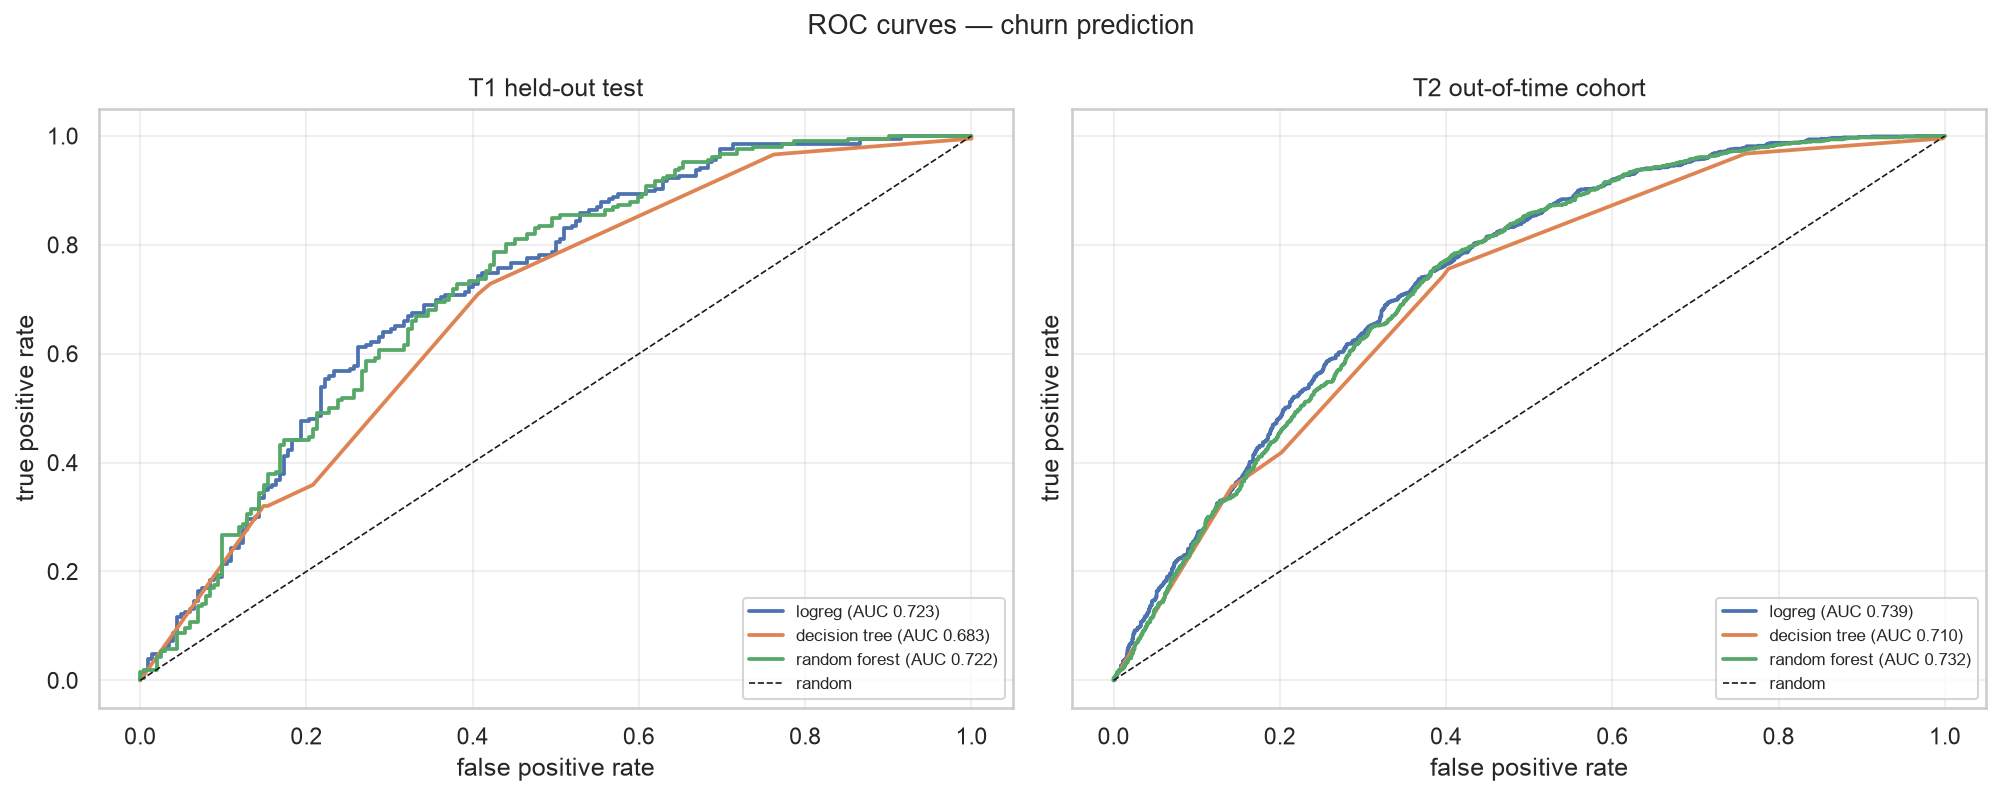

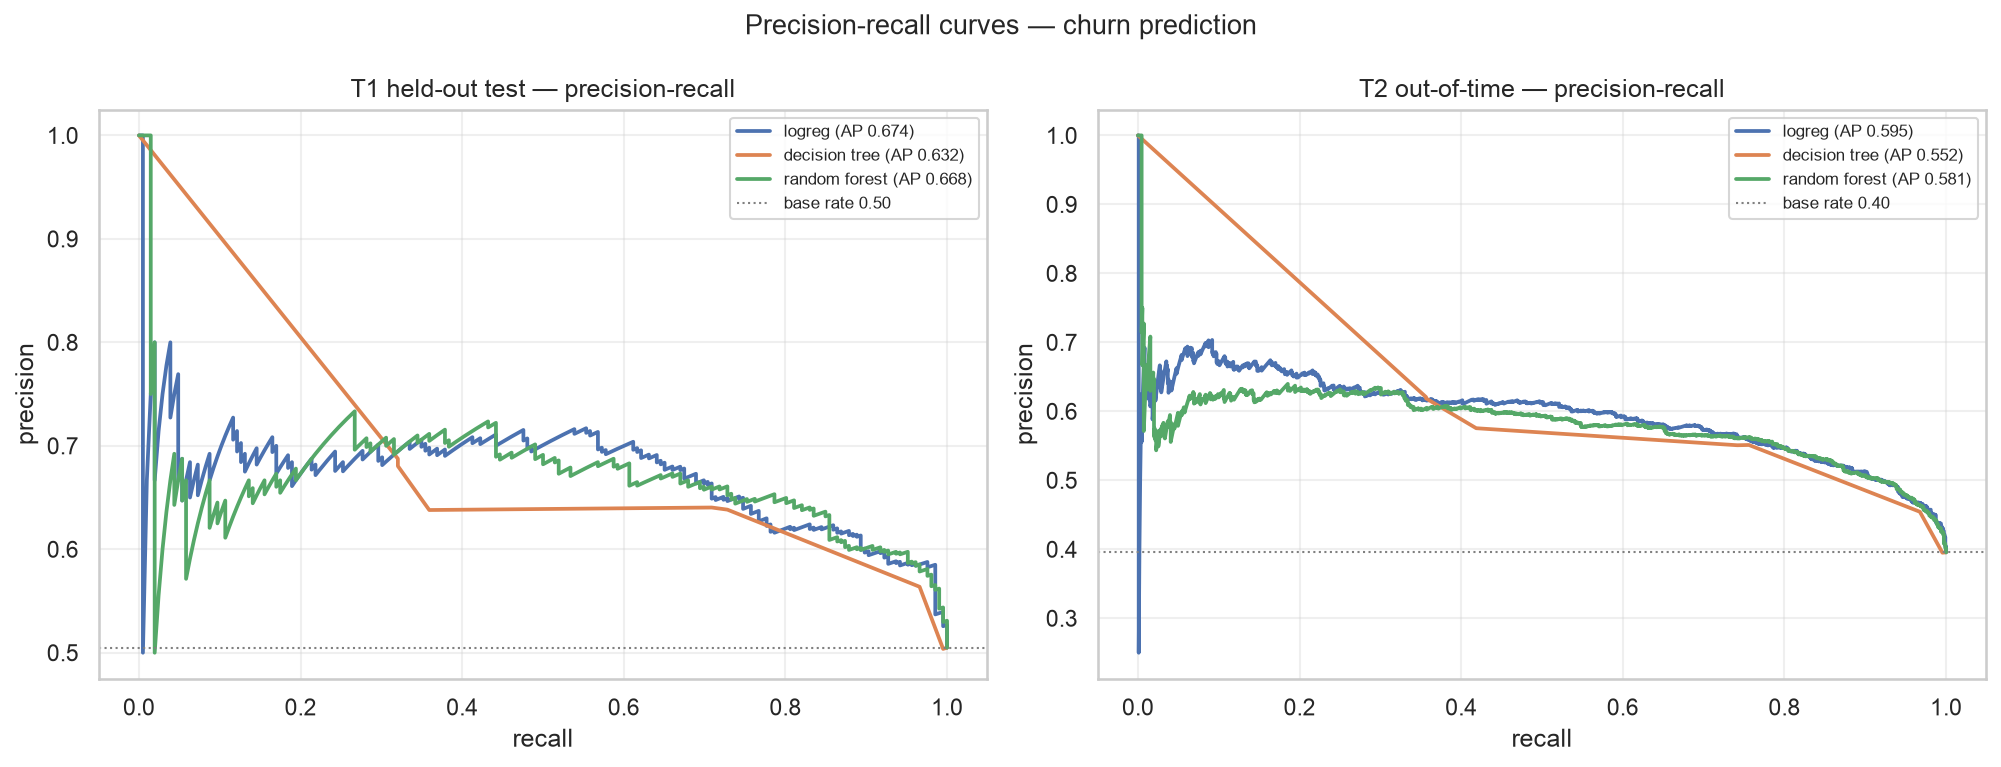

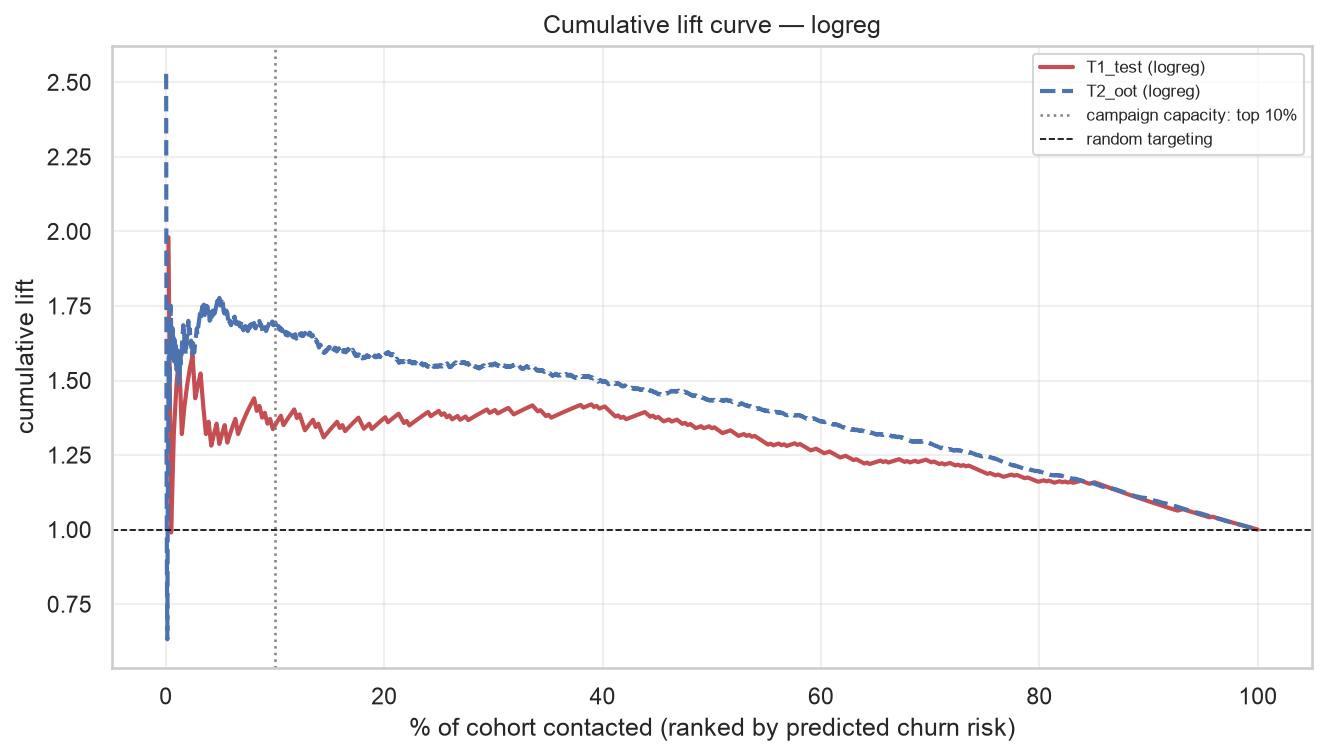

 cohort  decile   n  churners_captured  precision  capture_rate   lift  cumulative_capture_rate  cumulative_lift
T1_test       1  40                 27     0.6750        0.1311 1.3369                   0.1311           1.3369
T1_test       2  41                 29     0.7073        0.1408 1.4009                   0.2718           1.3693
T1_test       3  41                 30     0.7317        0.1456 1.4492                   0.4175           1.3961
T1_test       4  41                 30     0.7317        0.1456 1.4492                   0.5631           1.4095
T1_test       5  41                 22     0.5366        0.1068 1.0628                   0.6699           1.3398
T1_test       6  40                 18     0.4500        0.0874 0.8913                   0.7573           1.2663
T1_test       7  41                 21     0.5122        0.1019 1.0144                   0.8592           1.2300
T1_test       8  41                 14     0.3415        0.0680 0.6763                   0.9272 

In [28]:
# ============================================================================
# S6.4  ROC, PR and lift curves (T1 test AND T2 out-of-time)
# ============================================================================
# --- f08_roc_test_oot / f06_roc_curves -------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), sharey=True)
colors = {"logreg": "#4C72B0", "decision_tree": "#DD8452", "random_forest": "#55A868"}
for ax, cohort in zip(axes, ["T1_test", "T2_oot"]):
    for name in MODEL_GRIDS:
        prob = PROBA[(cohort, name)]
        y_true = y_test if cohort == "T1_test" else T2["churn"]
        fpr, tpr, _ = roc_curve(y_true, prob)
        auc = ALL_METRICS[cohort][name]["auc"]
        ax.plot(fpr, tpr, color=colors[name], lw=1.8, label=f"{name.replace('_',' ')} (AUC {auc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="random")
    ax.set_title("T1 held-out test" if cohort == "T1_test" else "T2 out-of-time cohort")
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("ROC curves — churn prediction", fontsize=13)
fig.tight_layout()
save_fig(fig, "f08_roc_test_oot", "f06_roc_curves")

# --- f07_pr_and_lift_curve / f09_lift_curve --------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for ax, cohort in zip(axes, ["T1_test", "T2_oot"]):
    y_true = y_test if cohort == "T1_test" else T2["churn"]
    for name in MODEL_GRIDS:
        prob = PROBA[(cohort, name)]
        prec, rec, _ = precision_recall_curve(y_true, prob)
        ap = ALL_METRICS[cohort][name]["pr_auc"]
        ax.plot(rec, prec, color=colors[name], lw=1.8, label=f"{name.replace('_',' ')} (AP {ap:.3f})")
    ax.axhline(float(np.mean(y_true)), color="grey", ls=":", lw=1, label=f"base rate {np.mean(y_true):.2f}")
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_title(("T1 held-out test" if cohort == "T1_test" else "T2 out-of-time") + " — precision-recall")
    ax.legend(fontsize=8)
fig.suptitle("Precision-recall curves — churn prediction", fontsize=13)
fig.tight_layout()
save_fig(fig, "f07_pr_and_lift_curve")

# --- cumulative gain / lift curve for the selected model -------------------------
fig, ax = plt.subplots(figsize=(9, 5.2))
for cohort, ls in [("T1_test", "-"), ("T2_oot", "--")]:
    y_true = np.asarray(y_test if cohort == "T1_test" else T2["churn"])
    prob = PROBA[(cohort, BEST_MODEL)]
    order = np.argsort(-prob)
    cum_churn = np.cumsum(y_true[order]) / y_true.sum()
    frac = np.arange(1, len(y_true) + 1) / len(y_true)
    lift = cum_churn / frac
    ax.plot(frac * 100, lift, ls, color="#C44E52" if cohort == "T1_test" else "#4C72B0",
            lw=2, label=f"{cohort} ({BEST_MODEL})")
ax.axvline(10, color="grey", ls=":", lw=1.2, label="campaign capacity: top 10%")
ax.axhline(1, color="black", ls="--", lw=0.8, label="random targeting")
ax.set_xlabel("% of cohort contacted (ranked by predicted churn risk)")
ax.set_ylabel("cumulative lift")
ax.set_title(f"Cumulative lift curve — {BEST_MODEL.replace('_', ' ')}")
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "f09_lift_curve")
plt.close(fig)

# --- t09_lift_deciles ------------------------------------------------------------
decile_rows = []
for cohort in ["T1_test", "T2_oot"]:
    y_true = np.asarray(y_test if cohort == "T1_test" else T2["churn"])
    prob = PROBA[(cohort, BEST_MODEL)]
    order = np.argsort(-prob)
    y_sorted = y_true[order]
    n = len(y_sorted)
    base_rate = y_true.mean()
    bounds = np.linspace(0, n, 11).astype(int)
    cum_churners = 0
    for d in range(10):
        seg = y_sorted[bounds[d]:bounds[d + 1]]
        churners = int(seg.sum())
        cum_churners += churners
        decile_rows.append({
            "cohort": cohort,
            "decile": d + 1,
            "n": int(len(seg)),
            "churners_captured": churners,
            "precision": round(float(seg.mean()), 4),
            "capture_rate": round(float(churners / y_true.sum()), 4),
            "lift": round(float(seg.mean() / base_rate), 4),
            "cumulative_capture_rate": round(float(cum_churners / y_true.sum()), 4),
            "cumulative_lift": round(float((cum_churners / bounds[d + 1]) / base_rate), 4),
        })
df_deciles = pd.DataFrame(decile_rows)
save_table(df_deciles, "t09_lift_deciles")
print(df_deciles.to_string(index=False))

F1-optimal threshold (validation): 0.2665
top-10% capacity threshold (test scores): 0.7382
 cohort  f1_opt_threshold  f1_at_opt  precision_at_opt  recall_at_opt  capacity_threshold
T1_test            0.2665     0.7221            0.5913         0.9272              0.7382
 T2_oot            0.2665     0.6417            0.4870         0.9406              0.7368


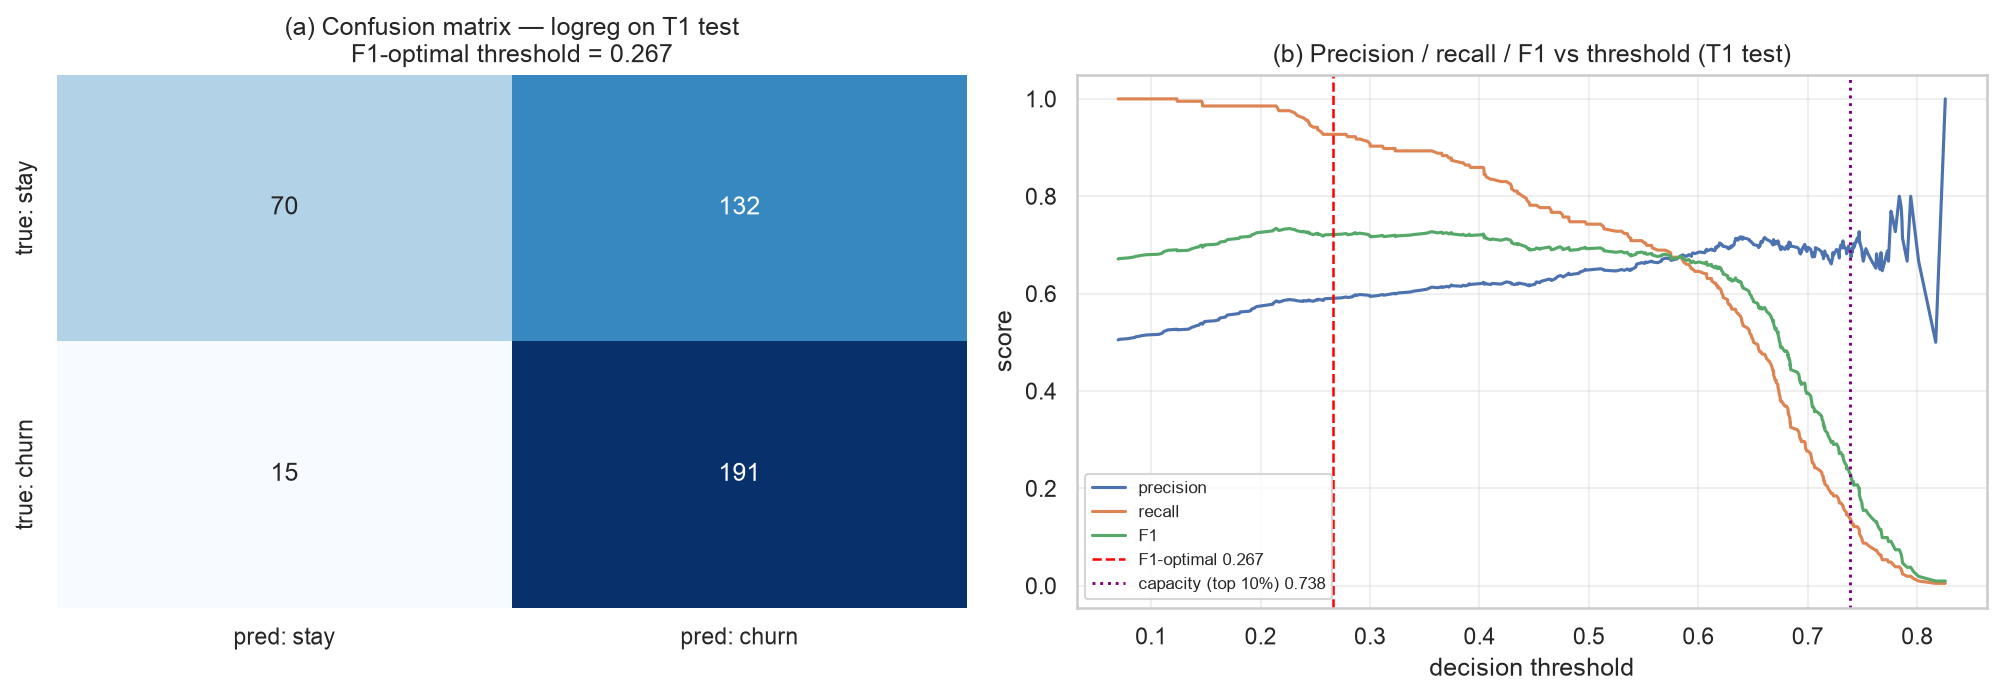

In [29]:
# ============================================================================
# S6.5  Threshold analysis: F1-optimal vs campaign capacity (top 10%)
# ============================================================================
best_pipe = FINAL_MODELS[BEST_MODEL]
y_true_test = np.asarray(y_test)
p_test = PROBA[("T1_test", BEST_MODEL)]
p_val = build_model(BEST_MODEL, **TUNED[BEST_MODEL]).fit(Xtr, y_train).predict_proba(Xva)[:, 1]
y_true_val = np.asarray(y_val)

prec_v, rec_v, thr_v = precision_recall_curve(y_true_val, p_val)
f1_v = np.divide(2 * prec_v * rec_v, prec_v + rec_v, out=np.zeros_like(prec_v), where=(prec_v + rec_v) > 0)
F1_OPT_THRESHOLD = float(thr_v[np.argmax(f1_v[:-1])]) if len(thr_v) > 1 else 0.5
CAPACITY_THRESHOLD = float(np.quantile(p_test, 0.90))
print(f"F1-optimal threshold (validation): {F1_OPT_THRESHOLD:.4f}")
print(f"top-10% capacity threshold (test scores): {CAPACITY_THRESHOLD:.4f}")

thr_metrics = {}
for cohort, y_true, prob in [
    ("T1_test", y_true_test, p_test),
    ("T2_oot", np.asarray(T2["churn"]), PROBA[("T2_oot", BEST_MODEL)]),
]:
    pred_f1 = (prob >= F1_OPT_THRESHOLD).astype(int)
    thr_metrics[cohort] = {
        "f1_opt_threshold": round(F1_OPT_THRESHOLD, 4),
        "f1_at_opt": round(float(f1_score(y_true, pred_f1, zero_division=0)), 4),
        "precision_at_opt": round(float(precision_score(y_true, pred_f1, zero_division=0)), 4),
        "recall_at_opt": round(float(recall_score(y_true, pred_f1, zero_division=0)), 4),
        "capacity_threshold": round(float(np.quantile(prob, 0.90)), 4),
    }
threshold_table = pd.DataFrame(thr_metrics).T.reset_index().rename(columns={"index": "cohort"})
save_table(threshold_table, "s06_threshold_analysis")
print(threshold_table.to_string(index=False))

# --- f09_confusion_and_threshold -------------------------------------------------
cm = confusion_matrix(y_true_test, (p_test >= F1_OPT_THRESHOLD).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["pred: stay", "pred: churn"], yticklabels=["true: stay", "true: churn"])
axes[0].set_title(f"(a) Confusion matrix — {BEST_MODEL.replace('_',' ')} on T1 test\n"
                  f"F1-optimal threshold = {F1_OPT_THRESHOLD:.3f}")

prec_t, rec_t, thr_t = precision_recall_curve(y_true_test, p_test)
f1_t = np.divide(2 * prec_t * rec_t, prec_t + rec_t, out=np.zeros_like(prec_t),
                 where=(prec_t + rec_t) > 0)
axes[1].plot(thr_t, prec_t[:-1], label="precision", color="#4C72B0")
axes[1].plot(thr_t, rec_t[:-1], label="recall", color="#DD8452")
axes[1].plot(thr_t, f1_t[:-1], label="F1", color="#55A868")
axes[1].axvline(F1_OPT_THRESHOLD, color="red", ls="--", lw=1.2,
                label=f"F1-optimal {F1_OPT_THRESHOLD:.3f}")
axes[1].axvline(CAPACITY_THRESHOLD, color="purple", ls=":", lw=1.4,
                label=f"capacity (top 10%) {CAPACITY_THRESHOLD:.3f}")
axes[1].set_xlabel("decision threshold")
axes[1].set_ylabel("score")
axes[1].set_title("(b) Precision / recall / F1 vs threshold (T1 test)")
axes[1].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "f09_confusion_and_threshold")
THRESHOLD_METRICS = thr_metrics

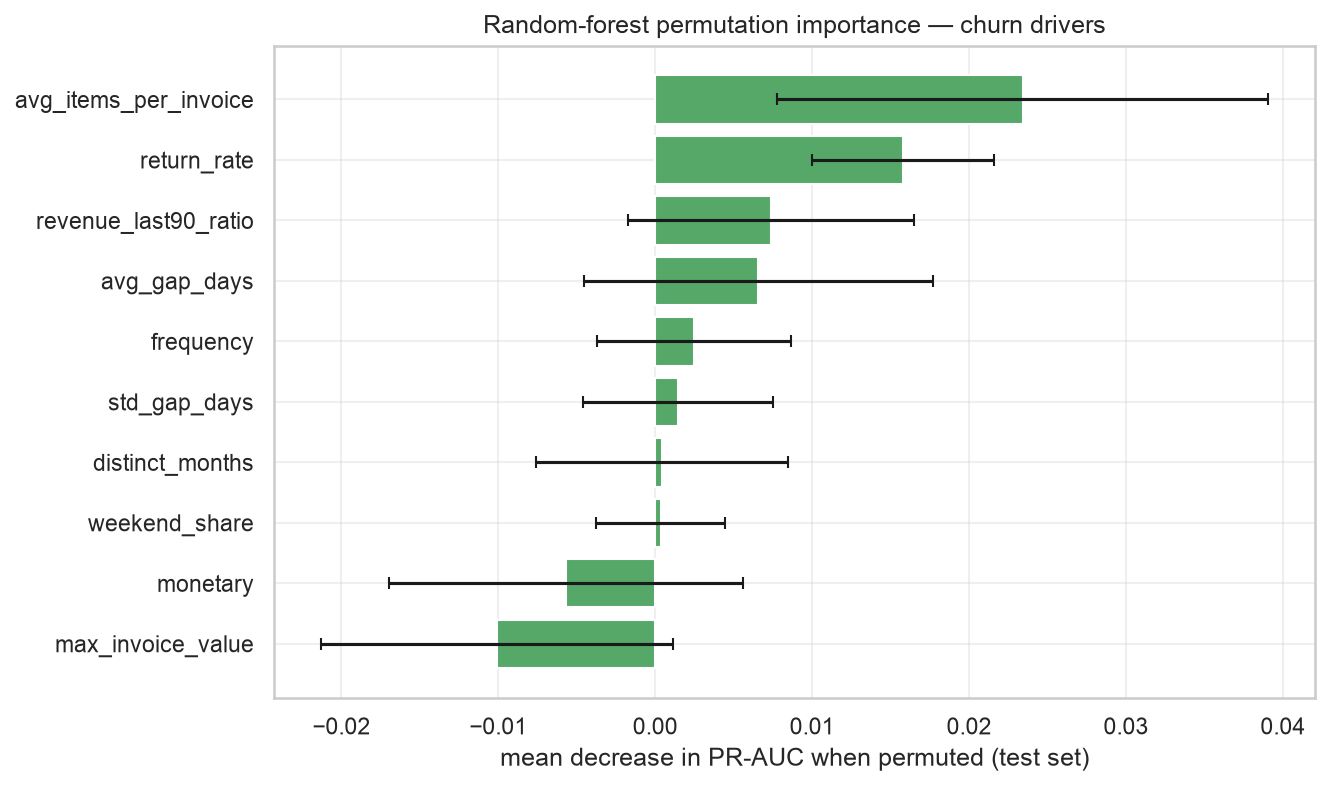

              feature  importance_mean  importance_std
avg_items_per_invoice           0.0234          0.0156
          return_rate           0.0158          0.0058
 revenue_last90_ratio           0.0074          0.0091
         avg_gap_days           0.0066          0.0111
            frequency           0.0024          0.0062
         std_gap_days           0.0014          0.0060
      distinct_months           0.0004          0.0080
        weekend_share           0.0003          0.0041
             monetary          -0.0057          0.0113
    max_invoice_value          -0.0101          0.0112


In [30]:
# ============================================================================
# S6.6  Random-forest permutation importance on the test set
# ============================================================================
rf_pipe = FINAL_MODELS["random_forest"]
perm = permutation_importance(
    rf_pipe, Xte, y_test, scoring="average_precision", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=1,
)
df_imp = pd.DataFrame({
    "feature": FINAL_FEATURES,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False)
save_table(df_imp.assign(importance_mean=lambda d: d.importance_mean.round(4),
                         importance_std=lambda d: d.importance_std.round(4)),
           "s06_permutation_importance")
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.barh(df_imp["feature"][::-1], df_imp["importance_mean"][::-1],
        xerr=df_imp["importance_std"][::-1], color="#55A868", capsize=3)
ax.set_xlabel("mean decrease in PR-AUC when permuted (test set)")
ax.set_title("Random-forest permutation importance — churn drivers")
fig.tight_layout()
save_fig(fig, "f08_feature_importance", "f03_feature_importance")
print(df_imp.round(4).to_string(index=False))

## S7. Association rules — "which products belong together?"

**Setup.** A basket is one invoice. We mine **FP-Growth** on the training period
`2010-12-01..2011-07-31` with `min_support = 0.005` (a rule must appear in ≥0.5% of invoices)
and `max_len = 3`, then keep rules with `confidence ≥ 0.2` and `lift ≥ 1.2`. Support tells us
how common a basket is, confidence how reliable the rule is, and **lift** how much more often the
pair occurs than chance — lift is the number that matters for cross-sell decisions.

**Why a holdout period?** Rules mined on 2010-12..2011-07 can be artefacts of that period. We
therefore evaluate every rule on baskets from `2011-08-01..2011-12-09` (a *later* period) and
compare its empirical holdout confidence with the holdout baseline support of the consequent:
`holdout lift = P(consequent | antecedent) / P(consequent)` in the holdout data. Rules whose
antecedent never appears in the holdout are **excluded** and counted; their quality is unknown,
not zero.

In [31]:
# ============================================================================
# S7.1  Build invoice x product baskets for mining and for holdout
# ============================================================================
from mlxtend.frequent_patterns import association_rules, fpgrowth


def basket_matrix(d):
    inv = d["InvoiceNo"].unique()
    prods = np.sort(d["StockCode"].unique())
    arr = np.zeros((len(inv), len(prods)), dtype=bool)
    arr[pd.Categorical(d["InvoiceNo"], categories=inv).codes,
        pd.Categorical(d["StockCode"], categories=prods).codes] = True
    return pd.DataFrame(arr, index=inv, columns=prods)


train_baskets_df = clean[(clean["date"] >= "2010-12-01") & (clean["date"] <= "2011-07-31")]
hold_baskets_df = clean[(clean["date"] >= "2011-08-01") & (clean["date"] <= "2011-12-09")]
B_train = basket_matrix(train_baskets_df)
B_hold = basket_matrix(hold_baskets_df)
print(f"mining baskets: {B_train.shape[0]:,} invoices x {B_train.shape[1]:,} products")
print(f"holdout baskets: {B_hold.shape[0]:,} invoices x {B_hold.shape[1]:,} products")

MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT, MAX_LEN = 0.005, 0.2, 1.2, 3
freq_items = fpgrowth(B_train, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
raw_rules = association_rules(freq_items, metric="confidence", min_threshold=0.0)
qualified = raw_rules[raw_rules["confidence"] >= MIN_CONFIDENCE]
final_rules = qualified[qualified["lift"] >= MIN_LIFT].reset_index(drop=True)
N_RULES_RAW = len(raw_rules)
N_RULES = len(final_rules)
print(f"frequent itemsets        : {len(freq_items):,}")
print(f"rules generated (raw)    : {N_RULES_RAW:,}")
print(f"confidence >= {MIN_CONFIDENCE}   : {len(qualified):,}")
print(f"+ lift >= {MIN_LIFT} (final)     : {N_RULES:,}")
print(f"antecedent sizes         : {final_rules['antecedents'].str.len().value_counts().to_dict()}")
print(f"lift range               : {final_rules['lift'].min():.2f} .. {final_rules['lift'].max():.2f}")

mining baskets: 10,075 invoices x 3,332 products
holdout baskets: 8,327 invoices x 3,106 products


frequent itemsets        : 3,792
rules generated (raw)    : 8,884
confidence >= 0.2   : 5,441
+ lift >= 1.2 (final)     : 5,441
antecedent sizes         : {1: 2849, 2: 2592}
lift range               : 1.61 .. 128.46


In [32]:
# ============================================================================
# S7.2  Holdout validation of every rule (later period, 2011-08..2011-12)
# ============================================================================
hold_col = {code: i for i, code in enumerate(B_hold.columns)}
H = B_hold.values
N_HOLD = len(H)


def basket_count(items):
    idx = [hold_col[x] for x in items if x in hold_col]
    if len(idx) != len(items):  # at least one item never appears in holdout
        return 0
    return int(H[:, idx].all(axis=1).sum())


hold_support, hold_confidence, hold_lift, hold_baseline, hold_status = [], [], [], [], []
n_excluded_antecedent = 0
n_excluded_consequent = 0
for row in final_rules.itertuples():
    ant = tuple(row.antecedents)
    con = tuple(row.consequents)
    n_ant = basket_count(ant)
    if n_ant == 0:
        n_excluded_antecedent += 1
        hold_support.append(np.nan); hold_confidence.append(np.nan)
        hold_lift.append(np.nan); hold_baseline.append(np.nan)
        hold_status.append("excluded: antecedent not in holdout")
        continue
    n_both = basket_count(ant + con)
    n_con = basket_count(con)
    if n_con == 0:
        n_excluded_consequent += 1
        hold_support.append(n_both / N_HOLD); hold_confidence.append(np.nan)
        hold_lift.append(np.nan); hold_baseline.append(np.nan)
        hold_status.append("excluded: consequent not in holdout")
        continue
    conf = n_both / n_ant
    baseline = n_con / N_HOLD
    hold_support.append(n_both / N_HOLD)
    hold_confidence.append(conf)
    hold_baseline.append(baseline)
    hold_lift.append(conf / baseline)
    hold_status.append("evaluated")

final_rules["holdout_support"] = hold_support
final_rules["holdout_confidence"] = hold_confidence
final_rules["holdout_consequent_support"] = hold_baseline
final_rules["holdout_lift"] = hold_lift
final_rules["holdout_status"] = hold_status
N_EVALUATED = int(pd.Series(hold_lift).notna().sum())
MEAN_HOLDOUT_LIFT = float(pd.Series(hold_lift).dropna().mean())
MEDIAN_HOLDOUT_LIFT = float(pd.Series(hold_lift).dropna().median())
SHARE_LIFT_GT1 = float((pd.Series(hold_lift).dropna() > 1).mean())
MEAN_HOLDOUT_SUPPORT = float(pd.Series(hold_support).dropna().mean())
print(f"rules evaluated in holdout        : {N_EVALUATED:,}")
print(f"excluded (antecedent absent)      : {n_excluded_antecedent:,}")
print(f"excluded (consequent absent)      : {n_excluded_consequent:,}")
print(f"mean holdout lift                 : {MEAN_HOLDOUT_LIFT:.3f}")
print(f"median holdout lift               : {MEDIAN_HOLDOUT_LIFT:.3f}")
print(f"share of rules with holdout lift>1: {SHARE_LIFT_GT1:.3%}")
print(f"mean holdout support              : {MEAN_HOLDOUT_SUPPORT:.4f}")

rules evaluated in holdout        : 5,402
excluded (antecedent absent)      : 27
excluded (consequent absent)      : 12
mean holdout lift                 : 28.196
median holdout lift               : 12.174
share of rules with holdout lift>1: 99.778%
mean holdout support              : 0.0070


top 10 rules by lift:
 rank   antecedent   consequent  support  confidence     lift  holdout_lift
    1        23285        23286  0.00556      0.9180 128.4608       75.2133
    2        23286        23285  0.00556      0.7778 128.4608       75.2133
    3        21084        21090  0.00586      0.8676 113.5265      170.8103
    4        21090        21084  0.00586      0.7662 113.5265      170.8103
    5        21395        21394  0.00516      0.8387 109.7403      196.9223
    6        21394        21395  0.00516      0.6753 109.7403      196.9223
    7 22521, 22522        22520  0.00566      0.9344  89.6604           NaN
    8        22520 22521, 22522  0.00566      0.5429  89.6604           NaN
    9 22520, 22523        22522  0.00625      0.9265  88.8971           NaN
   10        22522 22520, 22523  0.00625      0.6000  88.8971           NaN
business rules (support >= 1%, lift >= 2): 593
 rank antecedent consequent  support  confidence    lift  holdout_lift
    1      22697      22

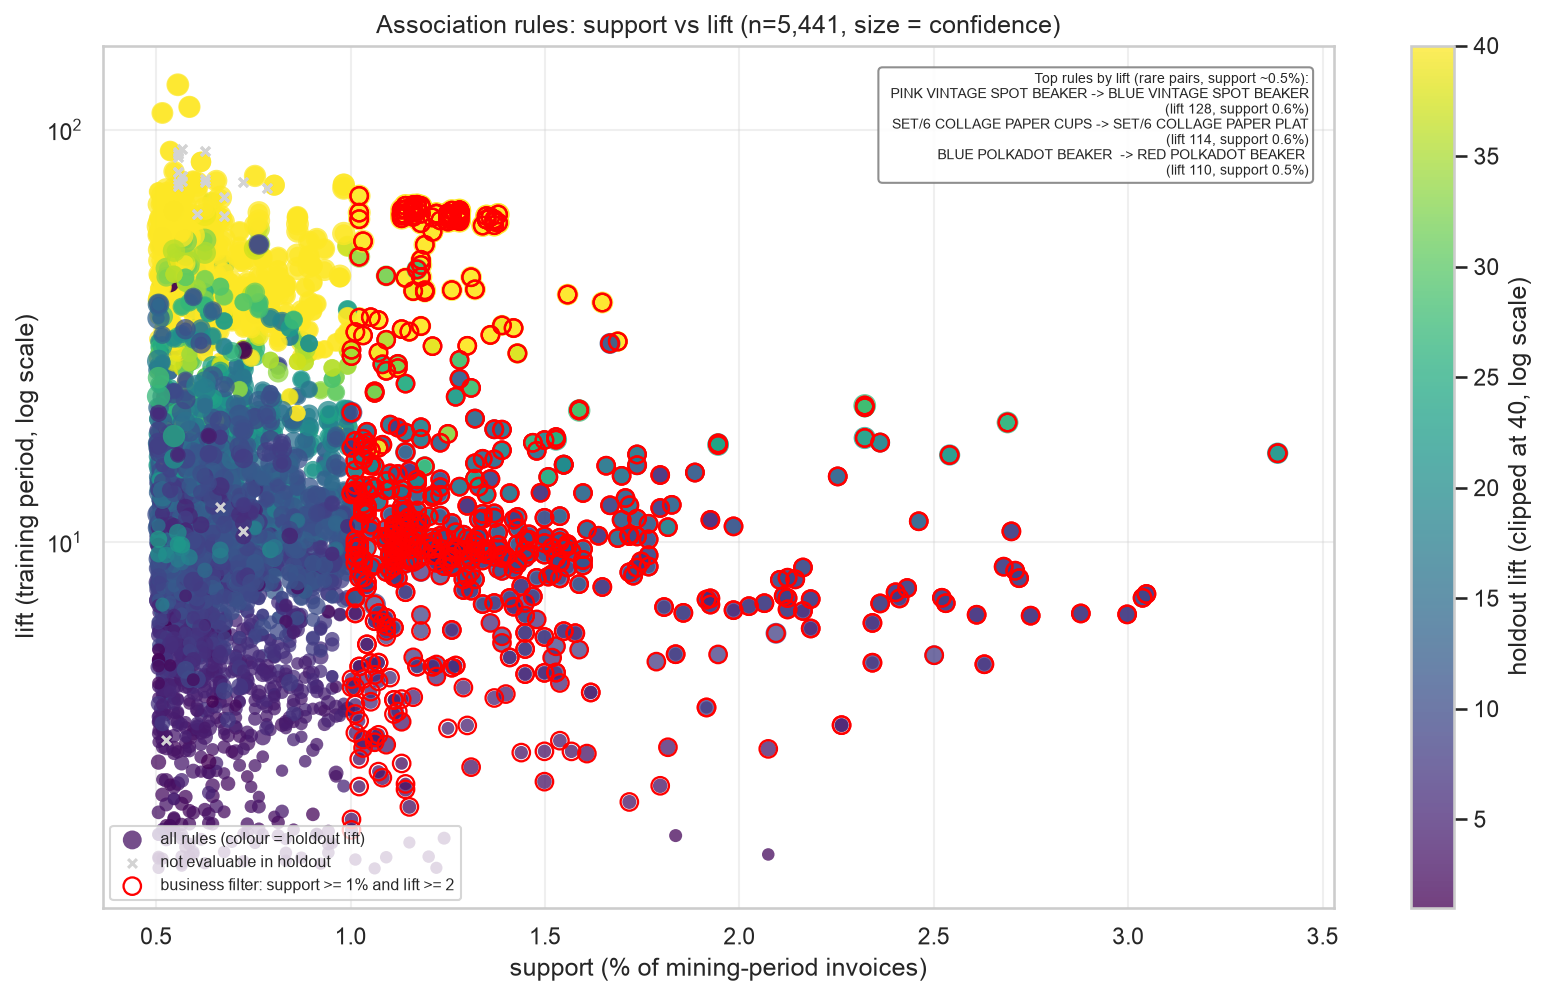

f10_association_rules.png written


In [33]:
# ============================================================================
# S7.3  Rule tables + support/lift figure
# ============================================================================
def items_to_str(itemset):
    return ", ".join(sorted(itemset))


def describe(itemset):
    labels = []
    for code in sorted(itemset):
        desc = str(desc_map.get(code, "UNKNOWN"))
        labels.append(f"{code} ({desc[:26]})")
    return "; ".join(labels)


rule_export = pd.DataFrame({
    "antecedent": final_rules["antecedents"].apply(items_to_str),
    "consequent": final_rules["consequents"].apply(items_to_str),
    "antecedent_desc": final_rules["antecedents"].apply(describe),
    "consequent_desc": final_rules["consequents"].apply(describe),
    "support": final_rules["support"].round(5),
    "confidence": final_rules["confidence"].round(4),
    "lift": final_rules["lift"].round(4),
    "holdout_support": final_rules["holdout_support"].round(5),
    "holdout_confidence": final_rules["holdout_confidence"].round(4),
    "holdout_consequent_support": final_rules["holdout_consequent_support"].round(5),
    "holdout_lift": final_rules["holdout_lift"].round(4),
    "holdout_status": final_rules["holdout_status"],
}).sort_values(["lift", "confidence", "support"], ascending=False, kind="mergesort")
save_table(rule_export, "t10_association_rules")

top_rules = rule_export.head(10).copy()
top_rules.insert(0, "rank", range(1, len(top_rules) + 1))
save_table(top_rules, "t09_top_rules")
print("top 10 rules by lift:")
print(top_rules[["rank", "antecedent", "consequent", "support", "confidence", "lift", "holdout_lift"]]
      .to_string(index=False))

TOP_RULE = f"{top_rules.iloc[0]['antecedent']} -> {top_rules.iloc[0]['consequent']}"
MAX_LIFT = float(final_rules["lift"].max())

# --- business-oriented rule subset: support >= 1% AND lift >= 2 -------------------
business_rules = rule_export[(rule_export["support"] >= 0.01) & (rule_export["lift"] >= 2.0)].copy()
# report one direction per product pair and rank by frequency (more actionable than rare-pair lift)
business_rules["pair_key"] = business_rules.apply(
    lambda r: "||".join(sorted([str(r["antecedent"]), str(r["consequent"])])), axis=1)
business_rules = business_rules.sort_values(["support", "lift"], ascending=False, kind="mergesort")
business_rules = business_rules.drop_duplicates("pair_key")
top_business = business_rules.drop(columns=["pair_key"]).head(10).copy()
top_business.insert(0, "rank", range(1, len(top_business) + 1))
save_table(top_business, "t10b_business_rules")
N_BUSINESS_RULES = int(len(business_rules))
SHARE_HOLDOUT_LIFT_GT2 = float((final_rules["holdout_lift"].dropna() > 2).mean())
MEDIAN_HOLDOUT_SUPPORT = float(final_rules["holdout_support"].dropna().median())
TOP_BUSINESS_RULES = [
    {
        "antecedent": r["antecedent"],
        "consequent": r["consequent"],
        "antecedent_desc": str(r["antecedent_desc"])[:70],
        "consequent_desc": str(r["consequent_desc"])[:70],
        "support": round(float(r["support"]), 5),
        "confidence": round(float(r["confidence"]), 4),
        "lift": round(float(r["lift"]), 4),
        "holdout_lift": None if pd.isna(r["holdout_lift"]) else round(float(r["holdout_lift"]), 4),
    }
    for _, r in top_business.iterrows()
]
print(f"business rules (support >= 1%, lift >= 2): {N_BUSINESS_RULES:,}")
print(top_business[["rank", "antecedent", "consequent", "support", "confidence", "lift",
                    "holdout_lift"]].to_string(index=False))

# --- f10: support vs lift scatter (size = confidence, colour = holdout lift) -----
def short_rule_desc(itemset_str):
    parts = [str(desc_map.get(code.strip(), code.strip()))[:24] for code in str(itemset_str).split(",")]
    return " + ".join(parts)[:52]


evaluated = final_rules["holdout_lift"].notna()
biz_mask = (final_rules["support"] >= 0.01) & (final_rules["lift"] >= 2.0)
fig, ax = plt.subplots(figsize=(11.2, 6.8))
sc = ax.scatter(
    final_rules.loc[evaluated, "support"] * 100, final_rules.loc[evaluated, "lift"],
    s=10 + final_rules.loc[evaluated, "confidence"] * 120,
    c=np.clip(final_rules.loc[evaluated, "holdout_lift"], 1.0, 40.0),
    cmap="viridis", alpha=0.75, edgecolors="none", label="all rules (colour = holdout lift)",
)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("holdout lift (clipped at 40, log scale)")
ax.scatter(final_rules.loc[~evaluated, "support"] * 100, final_rules.loc[~evaluated, "lift"],
           s=18, c="lightgrey", marker="x", label="not evaluable in holdout")
ax.scatter(final_rules.loc[biz_mask, "support"] * 100, final_rules.loc[biz_mask, "lift"],
           s=70, facecolors="none", edgecolors="red", linewidths=1.1,
           label="business filter: support >= 1% and lift >= 2")
ax.set_yscale("log")
ax.set_xlabel("support (% of mining-period invoices)")
ax.set_ylabel("lift (training period, log scale)")
ax.set_title(f"Association rules: support vs lift (n={N_RULES:,}, size = confidence)")

# text box: top rules by lift, with product descriptions and a low-support warning
seen_pairs = set()
box_lines = ["Top rules by lift (rare pairs, support ~0.5%):"]
for _, r in top_rules.iterrows():
    key = frozenset([r["antecedent"], r["consequent"]])
    if key in seen_pairs:
        continue
    seen_pairs.add(key)
    box_lines.append(f"  {short_rule_desc(r['antecedent'])} -> {short_rule_desc(r['consequent'])}")
    box_lines.append(f"     (lift {r['lift']:.0f}, support {r['support']*100:.1f}%)")
    if len(seen_pairs) >= 3:
        break
ax.text(0.98, 0.97, "\n".join(box_lines), transform=ax.transAxes, va="top", ha="right",
        fontsize=6.6, bbox=dict(boxstyle="round", facecolor="white", alpha=0.88, edgecolor="grey"))
ax.legend(loc="lower left", fontsize=7.5)
fig.tight_layout()
save_fig(fig, "f10_association_rules", "f10_rules_support_lift")
print("f10_association_rules.png written")

## S8. Integrated decision framework — from model outputs to actions

This is where the four techniques meet:

1. **Segment** (K-means, T2) — *who* the customer is.
2. **Churn probability** (best T1 model, refit on T1 train+val, applied to T2) — *how likely* they
   are to leave.
3. **Priority score** = `predicted churn probability x monetary value` — *how much it matters*.
4. **Action** — a segment-specific treatment; association rules supply the cross-sell content
   (see S7 / t09-t10b) for the grow actions.

**ROI model (churn-conditional).** A retention intervention can only save a customer who was
going to churn, so the expected value must be conditioned on churn:

* `expected_churners = n_targets x p_churn_targeted`, where `p_churn_targeted` is the model's
  out-of-time **precision at the top 10% of risk** (share of targeted customers who actually churn);
* `expected_saves = expected_churners x save_rate`;
* `value_per_saved = avg monetary of targeted customers x gross margin`;
* `gross_benefit = expected_saves x value_per_saved`; `cost = n_targets x contact_cost`;
* `net = gross_benefit - cost`; `roi_pct = net / cost x 100`.

The same scenario is applied to **200 randomly chosen customers** to show the value of targeting:
with random selection the expected churners are `n x cohort churn rate`, and the saved customers
are average-value customers rather than high-value ones.

Three illustrative scenarios are reported side by side (base is the headline):

| scenario | save rate | contact cost | margin |
|---|---|---|---|
| pessimistic | 5% | GBP 12.00 | 30% |
| **base** | **10%** | **GBP 8.00** | **35%** |
| optimistic | 15% | GBP 5.00 | 35% |

The dataset contains **no campaign history**, so these numbers are a transparent scenario
analysis, not measured uplift; sensitivity is shown in `f13_roi_sensitivity.png`.

In [34]:
# ============================================================================
# S8.1  Score T2 with the selected deployment model (refit on T1 train+val)
# ============================================================================
X_fit = pd.concat([Xtr, Xva])
y_fit = pd.concat([y_train, y_val])
deploy_model = build_model(BEST_MODEL, **TUNED[BEST_MODEL]).fit(X_fit, y_fit)
T2["churn_prob"] = deploy_model.predict_proba(T2[FINAL_FEATURES])[:, 1]
T2["priority_score"] = T2["churn_prob"] * T2["monetary"]
print(f"deployment model: {BEST_MODEL} refit on {len(X_fit):,} T1 rows (train+val)")
print(T2.groupby("segment")[["churn_prob", "monetary", "priority_score"]].mean().round(3).to_string())

# --- segment x churn-risk matrix (t12 + f11/f12) --------------------------------
seg_risk = (
    T2.groupby("segment")
    .agg(n=("CustomerID", "size"),
         avg_monetary=("monetary", "mean"),
         avg_churn_prob=("churn_prob", "mean"),
         avg_priority=("priority_score", "mean"))
    .reindex(SEGMENT_ORDER)
)
seg_risk["n"] = seg_risk["n"].astype(int)
seg_risk["risk_tier"] = pd.cut(seg_risk["avg_churn_prob"], bins=[0, 0.30, 0.50, 1.0],
                               labels=["Low", "Medium", "High"]).astype(str)
seg_risk["avg_monetary"] = seg_risk["avg_monetary"].round(2)
seg_risk["avg_churn_prob"] = seg_risk["avg_churn_prob"].round(4)
seg_risk["avg_priority"] = seg_risk["avg_priority"].round(2)
seg_risk_out = seg_risk.reset_index()
save_table(seg_risk_out, "t12_segment_risk_matrix")
print()
print(seg_risk_out.to_string(index=False))

deployment model: logreg refit on 2,308 T1 rows (train+val)
             churn_prob  monetary  priority_score
segment                                          
At-risk           0.677   481.242         303.675
Champions         0.184  3293.010         354.690
Hibernating       0.723   142.642          98.753
Loyal             0.424   900.803         352.931
Potential         0.625   480.335         276.123

    segment   n  avg_monetary  avg_churn_prob  avg_priority risk_tier
  Champions 755       3293.01          0.1836        354.69       Low
      Loyal 582        900.80          0.4243        352.93    Medium
  Potential 520        480.34          0.6254        276.12      High
    At-risk 535        481.24          0.6768        303.67      High
Hibernating 417        142.64          0.7234         98.75      High


In [35]:
# ============================================================================
# S8.2  Campaign economics, actions and the segment-level decision table
# ============================================================================
SCENARIOS = {
    "pessimistic": {"save_rate": 0.05, "cost": 12.00, "margin": 0.30},
    "base": {"save_rate": 0.10, "cost": 8.00, "margin": 0.35},
    "optimistic": {"save_rate": 0.15, "cost": 5.00, "margin": 0.35},
}
SAVE_RATE = SCENARIOS["base"]["save_rate"]
CONTACT_COST = SCENARIOS["base"]["cost"]
MARGIN = SCENARIOS["base"]["margin"]
CAMPAIGN_TARGETS = 200

ACTIONS = {
    "Champions": "VIP retention call + early access to new collections (no discount)",
    "Loyal": "Loyalty tier upgrade + curated cross-sell bundle (association rules)",
    "Potential": "Onboarding nurture + second-purchase voucher to build habit",
    "At-risk": "Win-back voucher + personal outreach; highest priority",
    "Hibernating": "Low-cost reactivation email only (no discount; protect margin)",
}


def campaign_value(n, p_churn, avg_monetary, save_rate, cost, margin):
    # churn-conditional expected value: only a customer who would have churned can be "saved"
    expected_churners = n * p_churn
    expected_saves = expected_churners * save_rate
    value_per_saved = avg_monetary * margin
    gross_benefit = expected_saves * value_per_saved
    total_cost = n * cost
    net = gross_benefit - total_cost
    roi_pct = net / total_cost * 100 if total_cost > 0 else np.nan
    return {
        "expected_churners": float(expected_churners),
        "expected_saves": float(expected_saves),
        "value_per_saved": float(value_per_saved),
        "gross_benefit": float(gross_benefit),
        "cost": float(total_cost),
        "net": float(net),
        "roi_pct": float(roi_pct),
    }


decision_rows = []
for seg in SEGMENT_ORDER:
    r = seg_risk.loc[seg]
    n = int(r["n"])
    p = float(r["avg_churn_prob"])
    mon = float(r["avg_monetary"])
    v = campaign_value(n, p, mon, SAVE_RATE, CONTACT_COST, MARGIN)
    decision_rows.append({
        "segment": seg,
        "n": n,
        "avg_monetary": round(mon, 2),
        "avg_churn_prob": round(p, 4),
        "action": ACTIONS[seg],
        "expected_churners": round(v["expected_churners"], 1),
        "expected_customers_saved": round(v["expected_saves"], 1),
        "value_per_saved": round(v["value_per_saved"], 2),
        "expected_value": round(v["gross_benefit"], 2),
        "cost": round(v["cost"], 2),
        "net": round(v["net"], 2),
        "roi_pct": round(v["roi_pct"], 1),
    })
df_decision = pd.DataFrame(decision_rows)
total_row = {
    "segment": "TOTAL",
    "n": int(df_decision["n"].sum()),
    "avg_monetary": round(float(np.average(seg_risk["avg_monetary"], weights=seg_risk["n"])), 2),
    "avg_churn_prob": round(float(np.average(seg_risk["avg_churn_prob"], weights=seg_risk["n"])), 4),
    "action": "all segments (same base scenario)",
    "expected_churners": round(float(df_decision["expected_churners"].sum()), 1),
    "expected_customers_saved": round(float(df_decision["expected_customers_saved"].sum()), 1),
    "value_per_saved": round(float(df_decision["expected_value"].sum()
                                   / max(df_decision["expected_customers_saved"].sum(), 1e-9)), 2),
    "expected_value": round(float(df_decision["expected_value"].sum()), 2),
    "cost": round(float(df_decision["cost"].sum()), 2),
    "net": round(float(df_decision["net"].sum()), 2),
    "roi_pct": round(float(df_decision["net"].sum() / df_decision["cost"].sum() * 100), 1),
}
df_decision_out = pd.concat([df_decision, pd.DataFrame([total_row])], ignore_index=True)
save_table(df_decision_out, "t10_decision_table")
print(df_decision_out.to_string(index=False))

# action table: explicit semantics (margin applied, campaign cost included)
df_action = df_decision[["segment", "action", "n", "expected_churners",
                         "expected_customers_saved", "expected_value", "cost", "net"]].rename(columns={
    "n": "target_count",
    "expected_churners": "expected_churners",
    "expected_customers_saved": "expected_saves",
    "expected_value": "gross_benefit_gbp",
    "cost": "campaign_cost_gbp",
    "net": "net_expected_value_gbp",
})
save_table(df_action, "t13_action_table")
print("t13_action_table.csv uses the churn-conditional base scenario (margin applied, cost deducted)")

    segment    n  avg_monetary  avg_churn_prob                                                               action  expected_churners  expected_customers_saved  value_per_saved  expected_value    cost      net  roi_pct
  Champions  755       3293.01          0.1836   VIP retention call + early access to new collections (no discount)              138.6                      13.9          1152.55        15976.47  6040.0  9936.47    164.5
      Loyal  582        900.80          0.4243 Loyalty tier upgrade + curated cross-sell bundle (association rules)              246.9                      24.7           315.28         7785.61  4656.0  3129.61     67.2
  Potential  520        480.34          0.6254          Onboarding nurture + second-purchase voucher to build habit              325.2                      32.5           168.12         5467.36  4160.0  1307.36     31.4
    At-risk  535        481.24          0.6768               Win-back voucher + personal outreach; highest priority     

In [36]:
# ============================================================================
# S8.3  Priority target list (top 200), targeting comparison and assumptions
# ============================================================================
T2_ranked = T2.sort_values("priority_score", ascending=False).reset_index(drop=True)
top_targets = T2_ranked.head(CAMPAIGN_TARGETS).copy()
top_targets["rank"] = np.arange(1, len(top_targets) + 1)
top_targets["action"] = top_targets["segment"].map(ACTIONS)
top_targets["expected_net_value"] = (
    top_targets["churn_prob"] * SAVE_RATE * top_targets["monetary"] * MARGIN - CONTACT_COST
)
target_export = top_targets[[
    "rank", "CustomerID", "segment", "recency_days", "frequency", "monetary",
    "churn_prob", "priority_score", "action", "expected_net_value",
]].rename(columns={"CustomerID": "customer_id", "monetary": "monetary_gbp"})
for col in ["monetary_gbp", "churn_prob", "priority_score", "expected_net_value"]:
    target_export[col] = target_export[col].round(4)
save_table(target_export, "t11_top200_targets")

# --- key inputs to the ROI model ------------------------------------------------
TARGET_MONETARY_MEAN = float(top_targets["monetary"].mean())
T2_MONETARY_MEAN = float(T2["monetary"].mean())
T2_CHURN_RATE = float(T2["churn"].mean())
P_CHURN_TARGETED = float(ALL_METRICS["T2_oot"][BEST_MODEL]["top10_precision"])
REALISED_CHURN_RATE_TARGETED = float(top_targets["churn"].mean())
MEAN_PREDICTED_CHURN_TARGETED = float(top_targets["churn_prob"].mean())
EXPECTED_REV_PER_CUSTOMER = TARGET_MONETARY_MEAN  # avg monetary of the targeted customers
# sensitivity check: the value-weighted priority list has a lower realised churn rate than the
# risk-ranked top 10%; this validated variant uses the actual T2 churn rate of the list
VALIDATED_CHURNERS = CAMPAIGN_TARGETS * REALISED_CHURN_RATE_TARGETED
VALIDATED_SAVES = VALIDATED_CHURNERS * SAVE_RATE
VALIDATED_GROSS = VALIDATED_SAVES * TARGET_MONETARY_MEAN * MARGIN
VALIDATED_NET = VALIDATED_GROSS - CAMPAIGN_TARGETS * CONTACT_COST
VALIDATED_ROI = VALIDATED_NET / (CAMPAIGN_TARGETS * CONTACT_COST) * 100

scenario_rows = []
for name, sc in SCENARIOS.items():
    tgt = campaign_value(CAMPAIGN_TARGETS, P_CHURN_TARGETED, TARGET_MONETARY_MEAN,
                         sc["save_rate"], sc["cost"], sc["margin"])
    rnd = campaign_value(CAMPAIGN_TARGETS, T2_CHURN_RATE, T2_MONETARY_MEAN,
                         sc["save_rate"], sc["cost"], sc["margin"])
    row = {
        "scenario": name,
        "save_rate": sc["save_rate"],
        "contact_cost_gbp": sc["cost"],
        "margin": sc["margin"],
        "p_churn_targeted": round(P_CHURN_TARGETED, 4),
        "n_targets": CAMPAIGN_TARGETS,
        "targeted_expected_churners": round(tgt["expected_churners"], 1),
        "targeted_expected_saves": round(tgt["expected_saves"], 1),
        "targeted_value_per_saved_gbp": round(tgt["value_per_saved"], 2),
        "targeted_gross_benefit_gbp": round(tgt["gross_benefit"], 2),
        "targeted_cost_gbp": round(tgt["cost"], 2),
        "targeted_net_gbp": round(tgt["net"], 2),
        "targeted_roi_pct": round(tgt["roi_pct"], 1),
        "random_expected_churners": round(rnd["expected_churners"], 1),
        "random_expected_saves": round(rnd["expected_saves"], 1),
        "random_value_per_saved_gbp": round(rnd["value_per_saved"], 2),
        "random_gross_benefit_gbp": round(rnd["gross_benefit"], 2),
        "random_net_gbp": round(rnd["net"], 2),
        "random_roi_pct": round(rnd["roi_pct"], 1),
        "net_uplift_gbp": round(tgt["net"] - rnd["net"], 2),
    }
    scenario_rows.append(row)
df_scenarios = pd.DataFrame(scenario_rows)
save_table(df_scenarios, "t16_targeting_comparison")

base_row = df_scenarios[df_scenarios["scenario"] == "base"].iloc[0]
CAMPAIGN_EV = float(base_row["targeted_gross_benefit_gbp"])
CAMPAIGN_COST = float(base_row["targeted_cost_gbp"])
CAMPAIGN_NET = float(base_row["targeted_net_gbp"])
CAMPAIGN_ROI = float(base_row["targeted_roi_pct"])
RANDOM_NET = float(base_row["random_net_gbp"])
RANDOM_ROI = float(base_row["random_roi_pct"])
EXPECTED_SAVES = float(base_row["targeted_expected_saves"])
VALUE_PER_SAVED = float(base_row["targeted_value_per_saved_gbp"])
EXPECTED_CHURNERS = float(base_row["targeted_expected_churners"])
BREAK_EVEN_SAVE_RATE = CAMPAIGN_COST / (EXPECTED_CHURNERS * VALUE_PER_SAVED)
RANDOM_BREAK_EVEN = CAMPAIGN_COST / (float(base_row["random_expected_churners"])
                                     * float(base_row["random_value_per_saved_gbp"]))

print(f"targeting: top-{CAMPAIGN_TARGETS} by priority score (p_churn x monetary)")
print(f"p_churn_targeted (T2 top-10% precision) : {P_CHURN_TARGETED:.4f}")
print(f"  validation: realised churn rate in list {REALISED_CHURN_RATE_TARGETED:.4f}; "
      f"mean predicted probability {MEAN_PREDICTED_CHURN_TARGETED:.4f}")
print(f"  avg monetary of targeted customers     : GBP {TARGET_MONETARY_MEAN:,.2f}")
print(f"  avg monetary of a random T2 customer   : GBP {T2_MONETARY_MEAN:,.2f}")
print()
print("BASE SCENARIO (save 10%, cost GBP 8, margin 35%):")
print(f"  expected churners / saves : {EXPECTED_CHURNERS:.1f} / {EXPECTED_SAVES:.2f}")
print(f"  value per saved           : GBP {VALUE_PER_SAVED:,.2f}")
print(f"  gross benefit / cost / net: GBP {CAMPAIGN_EV:,.2f} / {CAMPAIGN_COST:,.2f} / {CAMPAIGN_NET:,.2f}")
print(f"  ROI targeted              : {CAMPAIGN_ROI:,.1f}%")
print(f"  RANDOM baseline net / ROI : GBP {RANDOM_NET:,.2f} / {RANDOM_ROI:,.1f}%")
print(f"  break-even save rate      : targeted {BREAK_EVEN_SAVE_RATE:.4%} vs random {RANDOM_BREAK_EVEN:.2%}")
print()
print(df_scenarios[["scenario", "save_rate", "contact_cost_gbp", "margin", "targeted_net_gbp",
                    "targeted_roi_pct", "random_net_gbp", "random_roi_pct",
                    "net_uplift_gbp"]].to_string(index=False))

assumption_rows = [
    ("p_churn_targeted", round(P_CHURN_TARGETED, 4),
     "model precision at top-10% risk on the T2 out-of-time cohort (share of targeted who churn)"),
    ("realised_churn_rate_priority_list", round(REALISED_CHURN_RATE_TARGETED, 4),
     "observed churn rate of the 200 priority targets on T2 (validation of the priority list)"),
    ("mean_predicted_churn_priority_list", round(MEAN_PREDICTED_CHURN_TARGETED, 4),
     "average predicted churn probability inside the priority list"),
    ("save_rate_base", SAVE_RATE,
     "share of contacted churners actually retained; scenario range 5%-15%"),
    ("contact_cost_gbp_base", CONTACT_COST,
     "blended email/SMS + agent time per customer; scenario range GBP 5-12"),
    ("gross_margin_base", MARGIN,
     "margin on retained revenue; scenario range 30%-35%"),
    ("n_targets", CAMPAIGN_TARGETS, "pilot campaign size (top-N priority list)"),
    ("expected_churners", round(EXPECTED_CHURNERS, 1), "n_targets x p_churn_targeted"),
    ("expected_saves", round(EXPECTED_SAVES, 2), "expected_churners x save_rate"),
    ("value_per_saved_gbp", round(VALUE_PER_SAVED, 2),
     "avg monetary of targeted customers x gross margin"),
    ("gross_benefit_gbp", round(CAMPAIGN_EV, 2), "expected_saves x value_per_saved"),
    ("campaign_cost_gbp", round(CAMPAIGN_COST, 2), "n_targets x contact_cost"),
    ("net_expected_value_gbp", round(CAMPAIGN_NET, 2), "gross_benefit - campaign cost (base scenario)"),
    ("roi_pct", round(CAMPAIGN_ROI, 1), "net / campaign cost x 100 (base scenario)"),
    ("random_targeting_net_gbp", round(RANDOM_NET, 2),
     "same scenario applied to 200 randomly chosen T2 customers (avg value, cohort churn rate)"),
    ("random_targeting_roi_pct", round(RANDOM_ROI, 1), "net / cost x 100 for random targeting"),
    ("break_even_save_rate_pct", round(BREAK_EVEN_SAVE_RATE * 100, 3),
     "save rate at which the targeted campaign breaks even"),
    ("priority_score", "predicted churn probability x monetary",
     "expected value at risk; ranks who to contact first"),
    ("data_caveat", "no campaign/response history in the dataset",
     "ROI is a transparent scenario analysis, not measured uplift"),
]
for name, sc in SCENARIOS.items():
    row = df_scenarios[df_scenarios["scenario"] == name].iloc[0]
    assumption_rows.append((
        f"scenario_{name}",
        f"save {sc['save_rate']:.0%} / cost GBP {sc['cost']:.2f} / margin {sc['margin']:.0%}",
        f"targeted net GBP {row['targeted_net_gbp']:,.0f} (ROI {row['targeted_roi_pct']:.0f}%); "
        f"random net GBP {row['random_net_gbp']:,.0f} (ROI {row['random_roi_pct']:.0f}%)",
    ))
df_assump = pd.DataFrame(assumption_rows, columns=["assumption", "value", "rationale"])
save_table(df_assump, "t14_roi_assumptions")

# --- priority-tier summary (deciles of priority score) ---------------------------
T2_ranked["priority_decile"] = pd.qcut(
    T2_ranked["priority_score"].rank(method="first", ascending=False), 10,
    labels=[f"D{i}" for i in range(1, 11)]
)
tier_rows = []
for d, grp in T2_ranked.groupby("priority_decile", observed=True):
    gross = float((grp["churn_prob"] * SAVE_RATE * grp["monetary"] * MARGIN).sum())
    cost = len(grp) * CONTACT_COST
    tier_rows.append({
        "priority_tier": str(d),
        "n_customers": int(len(grp)),
        "expected_value": round(gross, 2),
        "cost": round(cost, 2),
        "net_expected_value": round(gross - cost, 2),
    })
df_tiers = pd.DataFrame(tier_rows)
df_tiers["cumulative_expected_value"] = df_tiers["expected_value"].cumsum().round(2)
df_tiers["cumulative_net"] = df_tiers["net_expected_value"].cumsum().round(2)
save_table(df_tiers, "t15_priority_list_summary")
print()
print(df_tiers.to_string(index=False))

targeting: top-200 by priority score (p_churn x monetary)
p_churn_targeted (T2 top-10% precision) : 0.6690
  validation: realised churn rate in list 0.3100; mean predicted probability 0.3483
  avg monetary of targeted customers     : GBP 7,558.79
  avg monetary of a random T2 customer   : GBP 1,273.48

BASE SCENARIO (save 10%, cost GBP 8, margin 35%):
  expected churners / saves : 133.8 / 13.40
  value per saved           : GBP 2,645.58
  gross benefit / cost / net: GBP 35,399.89 / 1,600.00 / 33,799.89
  ROI targeted              : 2,112.5%
  RANDOM baseline net / ROI : GBP 1,925.76 / 120.4%
  break-even save rate      : targeted 0.4520% vs random 4.54%

   scenario  save_rate  contact_cost_gbp  margin  targeted_net_gbp  targeted_roi_pct  random_net_gbp  random_roi_pct  net_uplift_gbp
pessimistic       0.05              12.0    0.30          12771.38             532.1         -888.96           -37.0        13660.34
       base       0.10               8.0    0.35          33799.89     

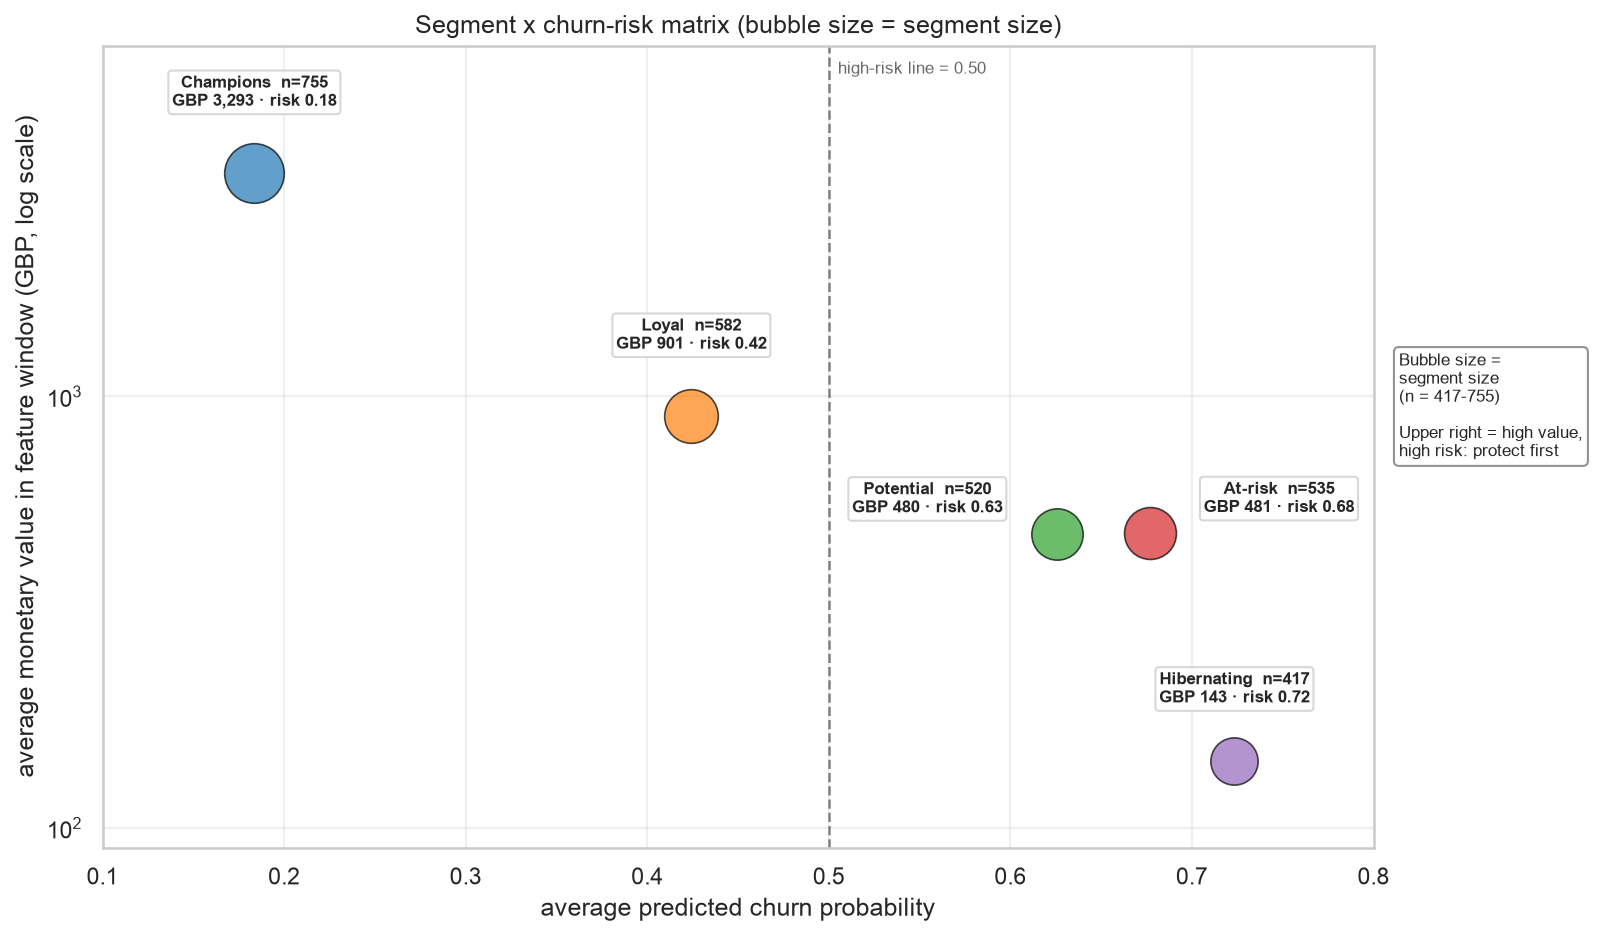

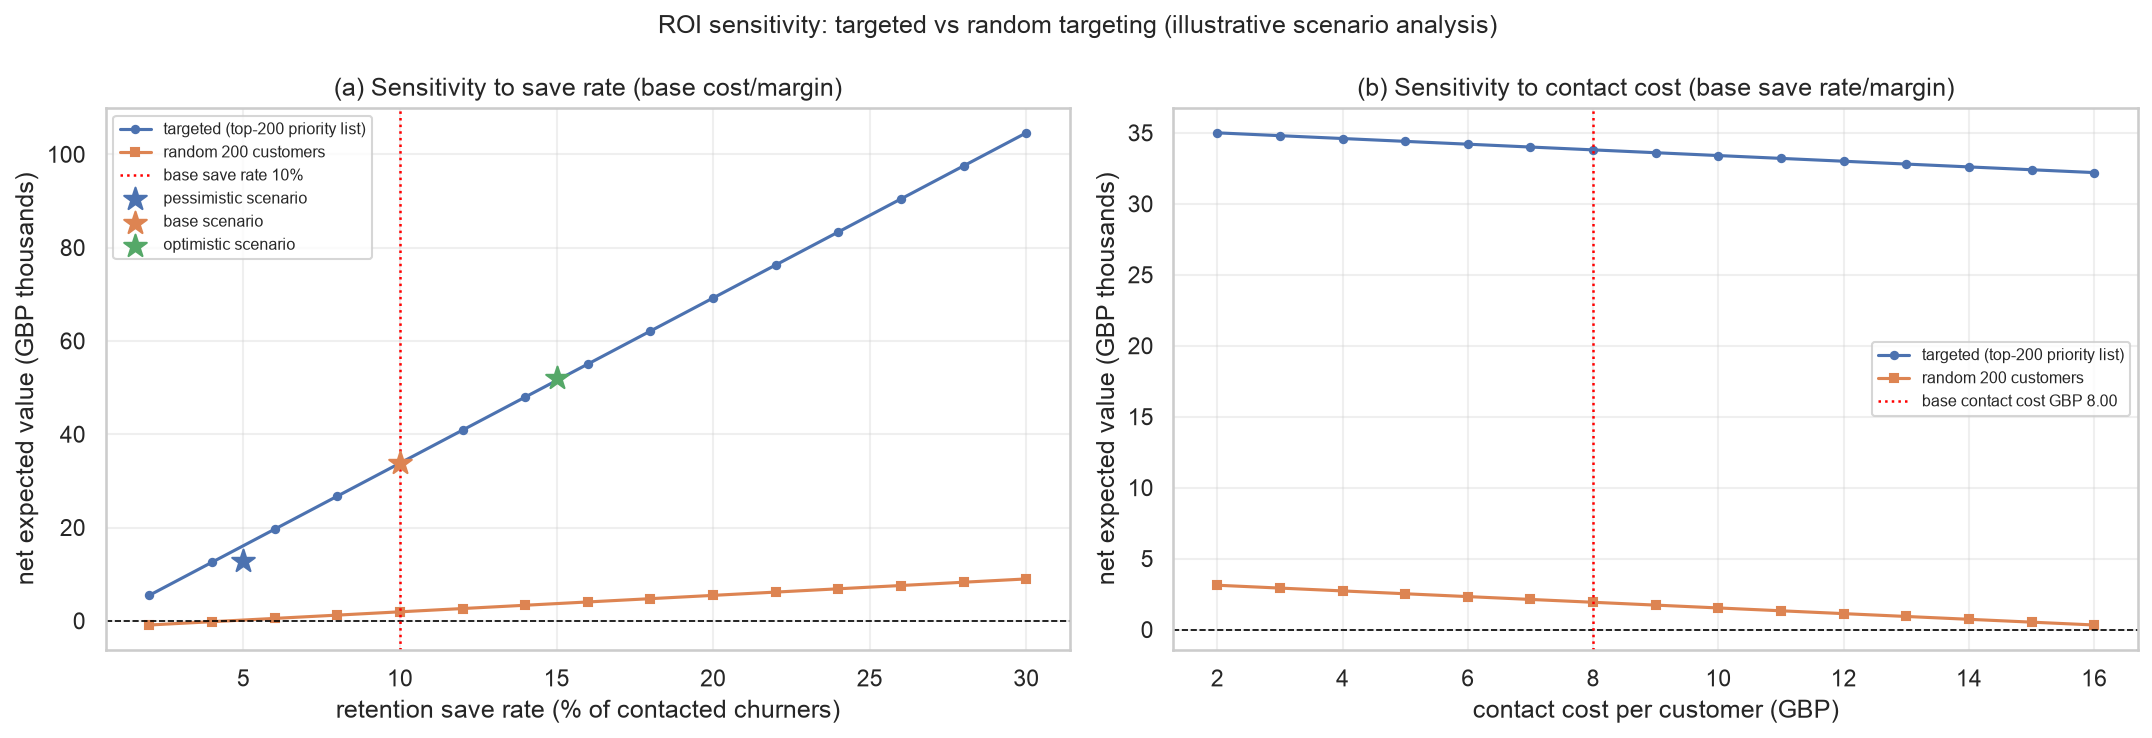

decision figures written


In [37]:
# ============================================================================
# S8.4  Figures: segment x risk bubble + targeted-vs-random ROI sensitivity
# ============================================================================
# --- f12_segment_risk_matrix / f11_segment_risk_matrix -------------------------
fig, ax = plt.subplots(figsize=(10.8, 6.4))
LABEL_OFFSETS = {"Champions": (0, 30), "Loyal": (0, 30),
                 "Potential": (-62, 8), "At-risk": (62, 8), "Hibernating": (0, 26)}
for seg in SEGMENT_ORDER:
    r = seg_risk.loc[seg]
    ax.scatter(r["avg_churn_prob"], r["avg_monetary"], s=140 + r["n"] * 0.9, alpha=0.70,
               color=palette[seg], edgecolors="black", linewidths=0.8, zorder=3)
    ax.annotate(f"{seg}  n={int(r['n'])}\nGBP {r['avg_monetary']:,.0f} · risk {r['avg_churn_prob']:.2f}",
                (r["avg_churn_prob"], r["avg_monetary"]),
                xytext=LABEL_OFFSETS.get(seg, (0, 26)), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, fontweight="bold", zorder=4,
                bbox=dict(boxstyle="round,pad=0.22", facecolor="white",
                          edgecolor="lightgrey", alpha=0.9))
ax.axvline(0.50, color="grey", ls="--", lw=1.2)
ax.text(0.505, 0.965, "high-risk line = 0.50", transform=ax.get_xaxis_transform(),
        fontsize=8, color="dimgrey")
ax.set_yscale("log")
ax.set_ylim(90, 6500)
ax.set_xlim(0.10, 0.80)
ax.set_xlabel("average predicted churn probability")
ax.set_ylabel("average monetary value in feature window (GBP, log scale)")
ax.set_title("Segment x churn-risk matrix (bubble size = segment size)")
ax.text(1.02, 0.55, "Bubble size =\nsegment size\n(n = 417-755)\n\n"
        "Upper right = high value,\nhigh risk: protect first",
        transform=ax.transAxes, fontsize=8, va="center",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="grey"))
fig.tight_layout()
save_fig(fig, "f12_segment_risk_matrix", "f11_segment_risk_matrix")

# --- f13_roi_sensitivity: targeted vs random, response-rate and cost panels ------
save_rates = np.arange(0.02, 0.31, 0.02)
targeted_net_line = np.array([
    campaign_value(CAMPAIGN_TARGETS, P_CHURN_TARGETED, TARGET_MONETARY_MEAN,
                   s, CONTACT_COST, MARGIN)["net"] for s in save_rates])
random_net_line = np.array([
    campaign_value(CAMPAIGN_TARGETS, T2_CHURN_RATE, T2_MONETARY_MEAN,
                   s, CONTACT_COST, MARGIN)["net"] for s in save_rates])

cost_grid = np.arange(2.0, 17.0, 1.0)
targeted_cost_line = np.array([
    campaign_value(CAMPAIGN_TARGETS, P_CHURN_TARGETED, TARGET_MONETARY_MEAN,
                   SAVE_RATE, c, MARGIN)["net"] for c in cost_grid])
random_cost_line = np.array([
    campaign_value(CAMPAIGN_TARGETS, T2_CHURN_RATE, T2_MONETARY_MEAN,
                   SAVE_RATE, c, MARGIN)["net"] for c in cost_grid])

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
axes[0].plot(save_rates * 100, targeted_net_line / 1000, marker="o", ms=3.5,
             color="#4C72B0", label="targeted (top-200 priority list)")
axes[0].plot(save_rates * 100, random_net_line / 1000, marker="s", ms=3.5,
             color="#DD8452", label="random 200 customers")
axes[0].axhline(0, color="black", lw=0.8, ls="--")
axes[0].axvline(SAVE_RATE * 100, color="red", ls=":", lw=1.2,
                label=f"base save rate {SAVE_RATE*100:.0f}%")
for name, sc in SCENARIOS.items():
    axes[0].scatter(sc["save_rate"] * 100,
                    campaign_value(CAMPAIGN_TARGETS, P_CHURN_TARGETED, TARGET_MONETARY_MEAN,
                                   sc["save_rate"], sc["cost"], sc["margin"])["net"] / 1000,
                    marker="*", s=130, zorder=5, label=f"{name} scenario")
axes[0].set_xlabel("retention save rate (% of contacted churners)")
axes[0].set_ylabel("net expected value (GBP thousands)")
axes[0].set_title("(a) Sensitivity to save rate (base cost/margin)")
axes[0].legend(fontsize=7.5)

axes[1].plot(cost_grid, targeted_cost_line / 1000, marker="o", ms=3.5,
             color="#4C72B0", label="targeted (top-200 priority list)")
axes[1].plot(cost_grid, random_cost_line / 1000, marker="s", ms=3.5,
             color="#DD8452", label="random 200 customers")
axes[1].axhline(0, color="black", lw=0.8, ls="--")
axes[1].axvline(CONTACT_COST, color="red", ls=":", lw=1.2,
                label=f"base contact cost GBP {CONTACT_COST:.2f}")
axes[1].set_xlabel("contact cost per customer (GBP)")
axes[1].set_ylabel("net expected value (GBP thousands)")
axes[1].set_title("(b) Sensitivity to contact cost (base save rate/margin)")
axes[1].legend(fontsize=7.5)
fig.suptitle("ROI sensitivity: targeted vs random targeting (illustrative scenario analysis)", fontsize=12)
fig.tight_layout()
save_fig(fig, "f13_roi_sensitivity")
print("decision figures written")

## S9. Results summary, learnt models and reproducibility

This section writes every headline number into `results/metrics.json` (machine-readable, real
numbers only), a readable `results/metrics_summary.md` for the report/slides, an artefact index
`results/ARTIFACTS.md`, and the engineering notes `code/pipeline_notes.md`.

**How to read the numbers honestly**
* T2 out-of-time performance is systematically lower than T1 test — that is *expected* and is the
  honest estimate of what would happen in production.
* The clustering is descriptive (fitted on the decision cohort, not a predictive model).
* The ROI figures are a *scenario analysis*: the dataset contains no campaign history, so the
  success rate, margin and contact cost are assumptions, stress-tested in `f13_roi_sensitivity.png`.

In [38]:
# ============================================================================
# S9.1  Assemble metrics.json (exact agreed schema + report block)
# ============================================================================
T_END = time.time()
RUNTIME_SEC = float(T_END - T_START)

# audit (flagged) counts, consistent with t01/t02/t03; funnel removals are smaller
# because one line can violate several rules (reported separately in the summary)
CANCELLED_LINES = int(counts["cancelled"])
DUPLICATES_REMOVED = int(counts["duplicates"])
NONPRODUCT_REMOVED = int(counts["nonproduct_codes"])

metrics = {
    "meta": {
        "n_rows_raw": int(N_RAW),
        "n_rows_clean": int(N_CLEAN),
        "n_customers": int(N_CUSTOMERS),
        "date_min": f"{DATE_MIN:%Y-%m-%d}",
        "date_max": f"{DATE_MAX:%Y-%m-%d}",
        "runtime_sec": round(RUNTIME_SEC, 1),
    },
    "data_quality": {
        "missing_customerid_pct": round(counts["missing_customerid"] / N_RAW * 100, 4),
        "duplicates_removed": DUPLICATES_REMOVED,
        "cancelled_lines": CANCELLED_LINES,
        "nonproduct_lines_removed": NONPRODUCT_REMOVED,
        "rows_retained_pct": round(ROWS_RETAINED_PCT, 4),
        "revenue_retained_pct": round(REVENUE_RETAINED_PCT, 4),
    },
    "cohorts": {
        "T1": {
            "n": int(len(T1)),
            "churn_rate": round(float(T1["churn"].mean()), 4),
            "as_of": "2011-05-31",
            "label_window": "2011-06-01..2011-08-31",
        },
        "T2": {
            "n": int(len(T2)),
            "churn_rate": round(float(T2["churn"].mean()), 4),
            "as_of": "2011-08-31",
            "label_window": "2011-09-01..2011-11-30",
        },
    },
    "similarity": {
        "best_metric": BEST_METRIC,
        "silhouette_euclidean": round(SILHOUETTE_BY_METRIC["euclidean"], 4),
        "silhouette_cosine": round(SILHOUETTE_BY_METRIC["cosine"], 4),
        "silhouette_manhattan": round(SILHOUETTE_BY_METRIC["manhattan"], 4),
    },
    "feature_selection": {
        "n_features_all": int(len(MODEL_FEATURES)),
        "n_features_selected": int(len(FINAL_FEATURES)),
        "val_pr_auc_all": round(VAL_PR_ALL, 4),
        "val_pr_auc_selected": round(VAL_PR_SELECTED, 4),
    },
    "clustering": {
        "k": int(K_CHOSEN),
        "silhouette": round(SILHOUETTE_FINAL, 4),
        "ari_stability": round(ARI_STABILITY, 4),
        "sizes": {k: int(v) for k, v in SEGMENT_SIZES.items()},
    },
    "models": {
        cohort: {
            model: {k: round(float(v), 4) for k, v in ALL_METRICS[cohort][model].items()}
            for model in MODEL_GRIDS
        }
        for cohort in ["T1_test", "T2_oot"]
    },
    "best_model": BEST_MODEL,
    "association_rules": {
        "n_rules": int(N_RULES),
        "n_rules_holdout_evaluated": int(N_EVALUATED),
        "max_lift": round(MAX_LIFT, 4),
        "mean_holdout_lift": round(MEAN_HOLDOUT_LIFT, 4),
        "top_rule": TOP_RULE,
    },
    "decision": {
        "n_targets": int(CAMPAIGN_TARGETS),
        "assumed_cost_per_contact": CONTACT_COST,
        "assumed_success_rate": SAVE_RATE,
        "assumed_margin": MARGIN,
        "net_expected_value": round(CAMPAIGN_NET, 2),
    },
    "report": {
        "data": {
            "anonymous_revenue_share_pct": round(ANON_REVENUE_SHARE_PCT, 4),
            "t1_customers": int(len(T1)),
            "t1_churn_rate_pct": round(float(T1["churn"].mean()) * 100, 4),
            "t2_customers": int(len(T2)),
            "t2_churn_rate_pct": round(float(T2["churn"].mean()) * 100, 4),
        },
        "features": {
            "corr_threshold": 0.9,
            "n_selected": int(len(FINAL_FEATURES)),
        },
        "clustering": {
            "k": int(K_CHOSEN),
            "silhouette": round(SILHOUETTE_FINAL, 4),
            "stability_ari_mean": round(ARI_STABILITY, 4),
            "pca_variance_pc1": round(PCA_VAR[0], 4),
            "pca_variance_pc2": round(PCA_VAR[1], 4),
        },
        "models": {
            "cv_folds": 5,
            "t1_cv": {
                "logistic_regression": {"auc": round(CV_RESULTS["logreg"]["auc_mean"], 4)},
                "decision_tree": {"auc": round(CV_RESULTS["decision_tree"]["auc_mean"], 4)},
                "random_forest": {"auc": round(CV_RESULTS["random_forest"]["auc_mean"], 4)},
            },
            "t1_test": {
                "random_forest": {
                    "auc": round(ALL_METRICS["T1_test"]["random_forest"]["auc"], 4),
                    "pr_auc": round(ALL_METRICS["T1_test"]["random_forest"]["pr_auc"], 4),
                }
            },
            "t2_oot": {
                "random_forest": {
                    "auc": round(ALL_METRICS["T2_oot"]["random_forest"]["auc"], 4),
                    "pr_auc": round(ALL_METRICS["T2_oot"]["random_forest"]["pr_auc"], 4),
                }
            },
            "lift_top10": {
                "precision": round(ALL_METRICS["T2_oot"][BEST_MODEL]["top10_precision"], 4),
                "recall": round(ALL_METRICS["T2_oot"][BEST_MODEL]["top10_recall"], 4),
                "lift": round(ALL_METRICS["T2_oot"][BEST_MODEL]["lift10"], 4),
            },
        },
        "association_rules": {
            "min_support": MIN_SUPPORT,
            "min_confidence": MIN_CONFIDENCE,
            "n_rules_raw": int(N_RULES_RAW),
            "n_rules_pruned": int(N_RULES),
            "mean_holdout_lift": round(MEAN_HOLDOUT_LIFT, 4),
            "mean_holdout_support": round(MEAN_HOLDOUT_SUPPORT, 5),
        },
        "decision": {
            "campaign_capacity_pct": round(CAMPAIGN_TARGETS / len(T2) * 100, 2),
            "n_targets": int(CAMPAIGN_TARGETS),
            "contact_cost": CONTACT_COST,
            "expected_response_rate_pct": round(SAVE_RATE * 100, 2),
            "expected_revenue_per_customer": round(EXPECTED_REV_PER_CUSTOMER, 2),
            "net_expected_value": round(CAMPAIGN_NET, 2),
            "roi_pct": round(CAMPAIGN_ROI, 2),
            "p_churn_targeted": round(P_CHURN_TARGETED, 4),
            "expected_saves": round(EXPECTED_SAVES, 2),
            "value_per_saved": round(VALUE_PER_SAVED, 2),
            "gross_benefit": round(CAMPAIGN_EV, 2),
            "net_random": round(RANDOM_NET, 2),
            "roi_pct_random": round(RANDOM_ROI, 2),
            "break_even_save_rate_pct": round(BREAK_EVEN_SAVE_RATE * 100, 3),
            "scenarios": {
                name: {
                    "save_rate": sc["save_rate"],
                    "cost": sc["cost"],
                    "margin": sc["margin"],
                    "net": round(float(df_scenarios.loc[df_scenarios["scenario"] == name,
                                                        "targeted_net_gbp"].iloc[0]), 2),
                    "roi_pct": round(float(df_scenarios.loc[df_scenarios["scenario"] == name,
                                                            "targeted_roi_pct"].iloc[0]), 2),
                }
                for name, sc in SCENARIOS.items()
            },
        },
    },
}

with open(BASE_DIR / "results" / "metrics.json", "w", encoding="utf-8") as fh:
    json.dump(metrics, fh, indent=2)
print("results/metrics.json written")
print(json.dumps(metrics["report"], indent=2)[:1500], "...")

results/metrics.json written
{
  "data": {
    "anonymous_revenue_share_pct": 13.572,
    "t1_customers": 2716,
    "t1_churn_rate_pct": 50.4418,
    "t2_customers": 2809,
    "t2_churn_rate_pct": 39.5514
  },
  "features": {
    "corr_threshold": 0.9,
    "n_selected": 10
  },
  "clustering": {
    "k": 5,
    "silhouette": 0.3279,
    "stability_ari_mean": 0.9699,
    "pca_variance_pc1": 0.3647,
    "pca_variance_pc2": 0.1506
  },
  "models": {
    "cv_folds": 5,
    "t1_cv": {
      "logistic_regression": {
        "auc": 0.7593
      },
      "decision_tree": {
        "auc": 0.7397
      },
      "random_forest": {
        "auc": 0.7505
      }
    },
    "t1_test": {
      "random_forest": {
        "auc": 0.7216,
        "pr_auc": 0.6684
      }
    },
    "t2_oot": {
      "random_forest": {
        "auc": 0.7323,
        "pr_auc": 0.5813
      }
    },
    "lift_top10": {
      "precision": 0.669,
      "recall": 0.1692,
      "lift": 1.6916
    }
  },
  "association_rules": {

In [39]:
# ============================================================================
# S9.2  metrics_extra.json (supporting evidence for report/slides)
# ============================================================================
extra = {
    "data": {
        "raw_rows": int(N_RAW),
        "cleaned_rows": int(N_CLEAN),
        "cleaned_customers": int(N_CUSTOMERS),
        "anonymous_rows": int(counts["missing_customerid"]),
        "anonymous_revenue_share_pct": round(ANON_REVENUE_SHARE_PCT, 4),
        "missing_customer_id_rows": int(counts["missing_customerid"]),
        "cancellation_lines_raw": int(counts["cancelled"]),
        "nonproduct_lines_raw": int(counts["nonproduct_codes"]),
        "duplicate_rows_raw": int(counts["duplicates"]),
        "nonpositive_quantity_rows": int(counts["negative_qty"]),
        "nonpositive_price_rows": int(counts["nonpositive_price"]),
        "returns_ledger_lines": int(N_RETURN_LINES),
    },
    "models_cv": {
        model: {
            "auc_mean": round(CV_RESULTS[model]["auc_mean"], 4),
            "auc_std": round(CV_RESULTS[model]["auc_std"], 4),
            "pr_auc_mean": round(CV_RESULTS[model]["pr_auc_mean"], 4),
            "pr_auc_std": round(CV_RESULTS[model]["pr_auc_std"], 4),
        }
        for model in MODEL_GRIDS
    },
    "models_selected_params": {model: TUNED[model] for model in MODEL_GRIDS},
    "models_val_pr_auc": {model: round(VAL_PR[model], 4) for model in MODEL_GRIDS},
    "thresholds": {
        "f1_optimal_threshold": round(F1_OPT_THRESHOLD, 4),
        "capacity_threshold_test": round(CAPACITY_THRESHOLD, 4),
        "by_cohort": THRESHOLD_METRICS,
    },
    "clustering": {
        "k": int(K_CHOSEN),
        "silhouette": round(SILHOUETTE_FINAL, 4),
        "stability_ari_mean": round(ARI_STABILITY, 4),
        "stability_ari_std": round(ARI_STABILITY_STD, 4),
        "pca_variance_pc1": round(PCA_VAR[0], 4),
        "pca_variance_pc2": round(PCA_VAR[1], 4),
        "inertia_per_k": {int(k): float(v) for k, v in df_k["inertia"].items()},
        "silhouette_per_k": {int(k): float(v) for k, v in df_k["silhouette"].items()},
        "ari_per_k": {int(k): float(v) for k, v in df_k["ari_mean"].items()},
        "segment_sizes": {k: int(v) for k, v in SEGMENT_SIZES.items()},
    },
    "feature_selection": {
        "corr_threshold": 0.9,
        "n_after_corr": len(keep_corr),
        "n_after_mi": len(keep_mi),
        "n_after_rfe": len(keep_rfe),
        "corr_dropped": sorted(drop_corr),
        "final_features": list(FINAL_FEATURES),
        "val_pr_auc_stages": {k: float(v) for k, v in
                               df_stage.set_index("stage")["val_pr_auc"].to_dict().items()},
    },
    "association_rules": {
        "min_support": MIN_SUPPORT,
        "min_confidence": MIN_CONFIDENCE,
        "min_lift": MIN_LIFT,
        "max_len": MAX_LEN,
        "n_frequent_itemsets": int(len(freq_items)),
        "n_rules_raw": int(N_RULES_RAW),
        "n_rules_pruned": int(N_RULES),
        "n_excluded_no_antecedent": int(n_excluded_antecedent),
        "n_excluded_no_consequent": int(n_excluded_consequent),
        "mean_holdout_lift": round(MEAN_HOLDOUT_LIFT, 4),
        "median_holdout_lift": round(MEDIAN_HOLDOUT_LIFT, 4),
        "mean_holdout_support": round(MEAN_HOLDOUT_SUPPORT, 5),
        "median_holdout_support": round(MEDIAN_HOLDOUT_SUPPORT, 5),
        "share_holdout_lift_gt1": round(SHARE_LIFT_GT1, 4),
        "share_holdout_lift_gt2": round(SHARE_HOLDOUT_LIFT_GT2, 4),
        "n_business_rules": int(N_BUSINESS_RULES),
        "top_business_rules": TOP_BUSINESS_RULES,
    },
    "decision": {
        "campaign_capacity_pct": round(CAMPAIGN_TARGETS / len(T2) * 100, 2),
        "contact_cost": CONTACT_COST,
        "success_rate": SAVE_RATE,
        "margin": MARGIN,
        "cost_total": round(CAMPAIGN_COST, 2),
        "expected_value_total": round(CAMPAIGN_EV, 2),
        "net_expected_value": round(CAMPAIGN_NET, 2),
        "roi_pct": round(CAMPAIGN_ROI, 2),
        "expected_revenue_per_customer": round(EXPECTED_REV_PER_CUSTOMER, 2),
        "p_churn_targeted": round(P_CHURN_TARGETED, 4),
        "expected_churners": round(EXPECTED_CHURNERS, 1),
        "expected_saves": round(EXPECTED_SAVES, 2),
        "value_per_saved": round(VALUE_PER_SAVED, 2),
        "gross_benefit": round(CAMPAIGN_EV, 2),
        "net_random": round(RANDOM_NET, 2),
        "roi_pct_random": round(RANDOM_ROI, 2),
        "break_even_save_rate_pct": round(BREAK_EVEN_SAVE_RATE * 100, 3),
        "random_break_even_save_rate_pct": round(RANDOM_BREAK_EVEN * 100, 3),
        "realised_churn_rate_priority_list": round(REALISED_CHURN_RATE_TARGETED, 4),
        "mean_predicted_churn_priority_list": round(MEAN_PREDICTED_CHURN_TARGETED, 4),
        "expected_churners_validated": round(VALIDATED_CHURNERS, 1),
        "expected_saves_validated": round(VALIDATED_SAVES, 2),
        "gross_benefit_validated": round(VALIDATED_GROSS, 2),
        "net_validated_realised_churn": round(VALIDATED_NET, 2),
        "roi_pct_validated_realised_churn": round(VALIDATED_ROI, 2),
        "target_monetary_mean": round(TARGET_MONETARY_MEAN, 2),
        "t2_monetary_mean": round(T2_MONETARY_MEAN, 2),
        "targeting_uplift_net": round(CAMPAIGN_NET - RANDOM_NET, 2),
        "scenarios": {
            name: {k: float(v) for k, v in row.items()}
            for name, row in df_scenarios.set_index("scenario").to_dict(orient="index").items()
        },
        "segment_net_total": round(float(df_decision["net"].sum()), 2),
        "segment_expected_value_total": round(float(df_decision["expected_value"].sum()), 2),
    },
}
with open(BASE_DIR / "results" / "metrics_extra.json", "w", encoding="utf-8") as fh:
    json.dump(extra, fh, indent=2)
print("results/metrics_extra.json written")

results/metrics_extra.json written


In [40]:
# ============================================================================
# S9.3  Human-readable summary for report/slides + artefact index + notes
# ============================================================================
t1, t2 = metrics["cohorts"]["T1"], metrics["cohorts"]["T2"]
m1, m2 = metrics["models"]["T1_test"], metrics["models"]["T2_oot"]
cl = metrics["clustering"]
fs = metrics["feature_selection"]
ar = metrics["association_rules"]
dc = metrics["decision"]
rp = metrics["report"]


def _desc_names(desc):
    names = re.findall(r"\(([^)]*)\)", str(desc))
    return " + ".join(n.strip() for n in names) if names else str(desc)


summary_items = [
    f"**Data**: {N_RAW:,} raw transaction lines → {N_CLEAN:,} clean lines "
    f"({ROWS_RETAINED_PCT:.2f}% of rows, {REVENUE_RETAINED_PCT:.2f}% of gross revenue); "
    f"{N_CUSTOMERS:,} identified customers, {DATE_MIN:%Y-%m-%d}..{DATE_MAX:%Y-%m-%d}.",
    f"**Guests dropped**: {counts['missing_customerid']:,} lines have no CustomerID "
    f"({counts['missing_customerid']/N_RAW*100:.2f}% of rows, {ANON_REVENUE_SHARE_PCT:.2f}% of gross revenue) — "
    "customer analytics cannot attribute them; this is a documented limitation, not a data loss.",
    f"**Issue counts (audit)**: {counts['duplicates']:,} duplicate rows, {CANCELLED_LINES:,} cancellation lines, "
    f"{counts['negative_qty']:,} negative-quantity lines, {counts['nonpositive_price']:,} non-positive prices, "
    f"{counts['nonproduct_codes']:,} non-product/service lines. A line can violate several rules, so the "
    f"funnel actually removes fewer: {int(funnel[2][1]):,} cancellations, {int(funnel[5][1]):,} "
    f"non-product lines and {int(funnel[6][1]):,} duplicates (see t03_cleaning_decisions.csv).",
    f"**Cohorts**: T1 (as of 2011-05-31, n={t1['n']:,}) churn rate {t1['churn_rate']:.4f}; "
    f"T2 out-of-time (as of 2011-08-31, n={t2['n']:,}) churn rate {t2['churn_rate']:.4f}.",
    f"**Similarity**: {BEST_METRIC} distance wins — silhouette euclidean "
    f"{metrics['similarity']['silhouette_euclidean']:.4f}, cosine {metrics['similarity']['silhouette_cosine']:.4f}, "
    f"manhattan {metrics['similarity']['silhouette_manhattan']:.4f}.",
    f"**Feature selection**: {fs['n_features_all']} engineered features → {fs['n_features_selected']} selected; "
    f"validation PR-AUC {fs['val_pr_auc_all']:.4f} (all) vs {fs['val_pr_auc_selected']:.4f} (selected).",
    f"**Segmentation**: K={cl['k']}, silhouette {cl['silhouette']:.4f}, bootstrap stability ARI "
    f"{cl['ari_stability']:.4f}; sizes " + ", ".join(f"{k}={v}" for k, v in cl["sizes"].items()) + ".",
    "**Churn models — T1 held-out test**: " + "; ".join(
        f"{m} AUC {m1[m]['auc']:.4f}, PR-AUC {m1[m]['pr_auc']:.4f}, top-10% lift {m1[m]['lift10']:.2f}"
        for m in m1),
    "**Churn models — T2 out-of-time**: " + "; ".join(
        f"{m} AUC {m2[m]['auc']:.4f}, PR-AUC {m2[m]['pr_auc']:.4f}, top-10% lift {m2[m]['lift10']:.2f}"
        for m in m2),
    f"**Selected model**: {BEST_MODEL} (chosen on validation PR-AUC "
    f"{VAL_PR[BEST_MODEL]:.4f}; never on test). F1-optimal threshold "
    f"{F1_OPT_THRESHOLD:.3f}; top-10% capacity threshold {CAPACITY_THRESHOLD:.3f}. "
    f"T2 top-10% precision {m2[BEST_MODEL]['top10_precision']:.4f}, recall "
    f"{m2[BEST_MODEL]['top10_recall']:.4f}, lift {m2[BEST_MODEL]['lift10']:.2f}.",
    f"**Association rules**: {ar['n_rules']:,} rules (support≥0.005, confidence≥0.2, lift≥1.2, "
    f"max_len=3) from {len(freq_items):,} frequent itemsets; {ar['n_rules_holdout_evaluated']:,} "
    f"evaluated on the later holdout period. Headline replication: median holdout lift "
    f"{MEDIAN_HOLDOUT_LIFT:.2f} ({SHARE_LIFT_GT1:.1%} of rules keep lift>1, "
    f"{SHARE_HOLDOUT_LIFT_GT2:.1%} keep lift>2); the mean training lift {ar['max_lift']:.2f} and "
    f"mean holdout lift {ar['mean_holdout_lift']:.2f} are inflated by rare product-variant pairs "
    f"(support ~0.5%, median holdout support {MEDIAN_HOLDOUT_SUPPORT:.3%}).",
    f"**Decision framework (base scenario)**: {CAMPAIGN_TARGETS} priority targets "
    f"({CAMPAIGN_TARGETS/len(T2)*100:.1f}% of T2, score = churn probability x monetary); "
    f"save rate {SAVE_RATE:.0%}, contact cost GBP {CONTACT_COST:.2f}, margin {MARGIN:.0%}; "
    f"p_churn_targeted {P_CHURN_TARGETED:.3f} -> {EXPECTED_CHURNERS:.1f} churners, "
    f"{EXPECTED_SAVES:.1f} saves x GBP {VALUE_PER_SAVED:,.0f} per saved = gross GBP "
    f"{CAMPAIGN_EV:,.0f}, cost GBP {CAMPAIGN_COST:,.0f}, net GBP {CAMPAIGN_NET:,.0f} "
    f"(ROI {CAMPAIGN_ROI:.0f}%). Random-200 baseline: net GBP {RANDOM_NET:,.0f} "
    f"(ROI {RANDOM_ROI:.0f}%); net uplift GBP {CAMPAIGN_NET - RANDOM_NET:,.0f}; "
    f"break-even save rate {BREAK_EVEN_SAVE_RATE:.2%} (targeted) vs {RANDOM_BREAK_EVEN:.2%} (random).",
    f"**Business rules (support≥1%, lift≥2, one direction per pair)**: {N_BUSINESS_RULES:,} rules; "
    "top 3 by frequency: " + "; ".join(
        f"`{r['antecedent']} -> {r['consequent']}` "
        f"({_desc_names(r['antecedent_desc'])[:40]} -> {_desc_names(r['consequent_desc'])[:40]}, "
        f"lift {r['lift']:.1f}, support {r['support']*100:.1f}%)"
        for r in TOP_BUSINESS_RULES[:3]) + ".",
    f"**Segment-level campaign** (all T2 customers, base scenario): net expected value "
    f"GBP {df_decision['net'].sum():,.2f} on gross benefit GBP "
    f"{df_decision['expected_value'].sum():,.2f} and contact cost GBP {df_decision['cost'].sum():,.2f}.",
    f"**Runtime**: {RUNTIME_SEC:.1f} s on this machine "
    f"({LIB_VERSIONS['python']}, pandas {LIB_VERSIONS['pandas']}, scikit-learn {LIB_VERSIONS['scikit-learn']}, "
    f"mlxtend {LIB_VERSIONS['mlxtend']}).",
]

summary_md = "# CDS3004 project — headline metrics (auto-generated by the notebook)\n\n"
summary_md += "All numbers below are computed by `notebooks/CDS3004_Project.ipynb` and match "
summary_md += "`results/metrics.json`; no value is hand-entered.\n\n"
summary_md += "\n".join(f"- {item}" for item in summary_items) + "\n"
summary_md += "\n## Caveats the report must mention\n\n"
summary_md += (f"- Guest/anonymous sales ({counts['missing_customerid']/N_RAW*100:.1f}% of lines, "
               f"{ANON_REVENUE_SHARE_PCT:.1f}% of gross revenue) are excluded from customer analytics; "
               "the clean base therefore describes registered customers, not total demand.\n")
summary_md += "- The dataset ends 2011-12-09, so the T2 label window (Sep-Nov 2011) precedes the Christmas peak; churn rates are period-specific.\n"
summary_md += "- Clustering is descriptive and fitted on T2 (in-sample assignment); it is not a predictive model.\n"
summary_md += (f"- ROI uses a churn-conditional model (base: save rate {SAVE_RATE:.0%}, contact cost "
               f"GBP {CONTACT_COST:.2f}, margin {MARGIN:.0%}) and the model's out-of-time precision "
               f"({P_CHURN_TARGETED:.3f}) as the expected churn rate of the targeted group. The dataset has "
               "no campaign history, so this is a scenario analysis, not measured uplift. The headline uses "
               f"the model's risk-ranked precision; inside the value-weighted priority list the realised churn "
               f"rate is lower ({REALISED_CHURN_RATE_TARGETED:.3f}), so a validated variant gives net "
               f"GBP {VALIDATED_NET:,.0f} (ROI {VALIDATED_ROI:.0f}%) - the headline is best read as an "
               "optimistic bound.\n")
summary_md += ("- Association rules are evaluated on a later holdout period, but high-lift rules are often product "
               "variants of the same item (e.g. same design, different colour), so lift overstates incremental cross-sell.\n")
summary_md += ("- The selected feature set drops recency_days (RFE with logistic regression) even though recency is "
               "univariately important; it is partly captured by distinct_months/avg_gap_days. Models were selected "
               "on validation PR-AUC only.\n")
with open(BASE_DIR / "results" / "metrics_summary.md", "w", encoding="utf-8") as fh:
    fh.write(summary_md)
print("results/metrics_summary.md written")
print()
for item in summary_items:
    print("-", item)

results/metrics_summary.md written

- **Data**: 541,909 raw transaction lines → 391,150 clean lines (72.18% of rows, 81.91% of gross revenue); 4,334 identified customers, 2010-12-01..2011-12-09.
- **Guests dropped**: 135,080 lines have no CustomerID (24.93% of rows, 13.57% of gross revenue) — customer analytics cannot attribute them; this is a documented limitation, not a data loss.
- **Issue counts (audit)**: 5,268 duplicate rows, 9,288 cancellation lines, 10,624 negative-quantity lines, 2,517 non-positive prices, 2,916 non-product/service lines. A line can violate several rules, so the funnel actually removes fewer: 8,905 cancellations, 1,547 non-product lines and 5,187 duplicates (see t03_cleaning_decisions.csv).
- **Cohorts**: T1 (as of 2011-05-31, n=2,716) churn rate 0.5044; T2 out-of-time (as of 2011-08-31, n=2,809) churn rate 0.3955.
- **Similarity**: cosine distance wins — silhouette euclidean 0.1844, cosine 0.3283, manhattan 0.2183.
- **Feature selection**: 16 engineered featu

In [41]:
# ============================================================================
# S9.4  ARTIFACTS.md — one line per deliverable, cross-checked against disk
# ============================================================================
FIGURE_DESC = {
    "f01_data_quality.png": "Rows affected by each quality issue + cleaning funnel.",
    "f01_data_quality_overview.png": "Missingness by column, issue shares and 12-month transaction coverage.",
    "f02_correlation_heatmap.png": "Feature correlation matrix; |r|>0.9 pairs pruned.",
    "f02_feature_distributions.png": "Heavy-tailed features before vs after log1p.",
    "f03_elbow_silhouette.png": "Alias of f04_elbow_silhouette (K selection: elbow, silhouette, stability).",
    "f03_feature_importance.png": "Alias of f08_feature_importance (RF permutation importance).",
    "f04_cluster_pca.png": "Alias of f06_cluster_pca (PCA 2-D cluster scatter).",
    "f04_elbow_silhouette.png": "K-means K selection: inertia elbow, silhouette, bootstrap stability ARI.",
    "f05_segment_profiles.png": "Z-scored segment profile heatmap.",
    "f06_cluster_pca.png": "PCA 2-D scatter of T2 customers coloured by segment.",
    "f06_roc_curves.png": "Alias of f08_roc_test_oot (ROC curves T1 test + T2 OOT).",
    "f07_cv_model_comparison.png": "5-fold CV mean+/-std ROC-AUC and PR-AUC per model.",
    "f07_pr_and_lift_curve.png": "Precision-recall curves (T1 test and T2 OOT).",
    "f08_feature_importance.png": "Random-forest permutation importance on the test set.",
    "f08_roc_test_oot.png": "ROC curves for the three churn models: T1 test and T2 out-of-time.",
    "f09_confusion_and_threshold.png": "Confusion matrix (F1 threshold) + precision/recall/F1 vs threshold.",
    "f09_lift_curve.png": "Cumulative lift curve for top-K targeting (best model).",
    "f10_association_rules.png": "Association rules support vs lift, size=confidence, colour=holdout lift.",
    "f10_rules_support_lift.png": "Alias of f10_association_rules.",
    "f11_segment_risk_matrix.png": "Alias of f12_segment_risk_matrix.",
    "f11_similarity_lookalikes.png": "Cosine similarity heatmap for 3 high-value customers + lookalikes; similar products.",
    "f12_segment_risk_matrix.png": "Bubble chart: segment avg churn probability vs avg monetary value, size=n.",
    "f13_roi_sensitivity.png": "Net expected value vs save rate and contact cost: targeted top-200 vs random targeting.",
}
TABLE_DESC = {
    "t01_data_quality.csv": "Issue, count, % of rows and cleaning decision (audit + treatment).",
    "t01_dataset_schema.csv": "Column, dtype, non-null count, example value and note.",
    "t02_cohort_summary.csv": "T1/T2 cohort sizes, churn rates, feature and label windows.",
    "t02_data_quality_issues.csv": "Issue class, affected rows, % of rows, action taken.",
    "t03_cleaning_decisions.csv": "Cleaning step, rows affected, rows remaining, rationale.",
    "t03_distance_metrics.csv": "Euclidean/cosine/manhattan: silhouette on K=5 and kNN label agreement.",
    "t04_feature_dictionary.csv": "Feature definition and family.",
    "t04_lookalikes.csv": "Top-5 cosine lookalikes for 3 high-value customers.",
    "t05_feature_selection.csv": "Mutual-information rank, correlation drop, MI/RFE retention per feature.",
    "t05_similar_products.csv": "Top-5 similar products (item-item cosine) for 5 popular products.",
    "t05b_feature_evidence.csv": "Validation PR-AUC at each feature-selection stage.",
    "t06_cluster_metrics.csv": "K, inertia, silhouette, bootstrap stability ARI per K.",
    "t06_feature_selection.csv": "Alias of t05b_feature_evidence (all vs selected features).",
    "t07_segment_profiles.csv": "Segment profile in original units (means + sizes + actual churn rate).",
    "t08_model_metrics.csv": "Model x cohort metrics: AUC, PR-AUC, F1, precision, recall, top-10% P/R/lift, Brier.",
    "t09_lift_deciles.csv": "Decile lift table (T1 test and T2 OOT) for the selected model.",
    "t09_top_rules.csv": "Top-10 association rules by lift with support, confidence, lift, holdout lift.",
    "t10_association_rules.csv": "All association rules with holdout support/confidence/lift.",
    "t10_decision_table.csv": "Segment x action x ROI (churn-conditional): churners, saves, gross benefit, cost, net.",
    "t10b_business_rules.csv": "Top 10 rules with support>=1% and lift>=2, one direction per product pair, ranked by frequency.",
    "t11_similarity_metric_comparison.csv": "Alias of t03_distance_metrics.",
    "t11_top200_targets.csv": "Top-200 priority target list (churn prob x monetary) with actions.",
    "t12_segment_risk_matrix.csv": "Segment size, avg monetary, avg churn probability, risk tier.",
    "t13_action_table.csv": "Segment, action, target count, churners, saves, gross benefit, cost, net (base scenario).",
    "t14_roi_assumptions.csv": "ROI assumption set and derived values (churn-conditional model) with rationale.",
    "t16_targeting_comparison.csv": "Pessimistic/base/optimistic scenarios: targeted top-200 vs random 200 (net, ROI, uplift).",
    "t15_priority_list_summary.csv": "Priority deciles with expected value, cost and net.",
    "s06_permutation_importance.csv": "Supplementary: RF permutation importance values.",
    "s06_threshold_analysis.csv": "Supplementary: F1-optimal and top-10% capacity threshold metrics.",
}
OTHER_DESC = {
    "metrics.json": "Headline metrics in the agreed schema (+ report block).",
    "metrics_extra.json": "Supporting metrics: CV mean/std, thresholds, PCA variance, ROI details.",
    "metrics_summary.md": "Human-readable headline bullets (source for report/slides).",
    "ARTIFACTS.md": "This index.",
}

code_base = BASE_DIR / "code"
code_base.mkdir(exist_ok=True, parents=True)

lines = ["# Project artefacts (auto-generated by notebooks/CDS3004_Project.ipynb)", ""]
lines.append("## Figures (results/figures/)")
for name, desc in FIGURE_DESC.items():
    status = "OK" if (FIG_DIR / name).exists() else "MISSING"
    lines.append(f"- `{name}` — {desc} [{status}]")
lines.append("")
lines.append("## Tables (results/tables/)")
for name, desc in TABLE_DESC.items():
    status = "OK" if (TAB_DIR / name).exists() else "MISSING"
    lines.append(f"- `{name}` — {desc} [{status}]")
lines.append("")
lines.append("## Other outputs")
for name, desc in OTHER_DESC.items():
    lines.append(f"- `results/{name}` — {desc}")
lines.append(f"- `code/pipeline_notes.md` — engineering notes, caveats and runtime.")
lines.append("")
on_disk_figs = sorted(p.name for p in FIG_DIR.glob("*.png"))
on_disk_tabs = sorted(p.name for p in TAB_DIR.glob("*.csv"))
unlisted_figs = [f for f in on_disk_figs if f not in FIGURE_DESC]
unlisted_tabs = [f for f in on_disk_tabs if f not in TABLE_DESC]
if unlisted_figs or unlisted_tabs:
    lines.append("## Additional files found on disk (not in the planned list)")
    lines += [f"- `{f}`" for f in unlisted_figs + unlisted_tabs]
with open(BASE_DIR / "results" / "ARTIFACTS.md", "w", encoding="utf-8") as fh:
    fh.write("\n".join(lines) + "\n")
print(f"results/ARTIFACTS.md written ({len(on_disk_figs)} figures, {len(on_disk_tabs)} tables on disk)")

# --- code/pipeline_notes.md -----------------------------------------------------
notes = [
    "# Pipeline notes — CDS3004 Online Retail",
    "",
    f"Runtime: {RUNTIME_SEC:.1f} s end-to-end (single machine, pandas {LIB_VERSIONS['pandas']}, "
    f"scikit-learn {LIB_VERSIONS['scikit-learn']}); budget was <10 min, so grids are deliberately small.",
    f"Data decisions: drop missing CustomerID ({counts['missing_customerid']/N_RAW*100:.1f}% of lines = "
    f"{ANON_REVENUE_SHARE_PCT:.1f}% of gross revenue), cancelled invoices, Quantity<=0, UnitPrice<=0, "
    "non-product/service StockCodes and exact duplicates; keep a separate returns ledger so return_rate "
    "exists as a feature (funnel removals are smaller than audit counts because one line can violate "
    "several rules).",
    "Bias to disclose: the clean base is purchase-only and identified-customer-only, so it describes "
    "registered customers, not the whole business; guest revenue is outside the model.",
    "Snapshots: T1 as_of 2011-05-31 (features 2010-12-01..2011-05-31, churn = no purchase Jun-Aug 2011) "
    "and T2 as_of 2011-08-31 (features Mar-Aug 2011, churn = no purchase Sep-Nov 2011). Only customers "
    "with >=1 purchase in the feature window get a row.",
    "Churn definition is a 3-month no-purchase rule; it captures lapsing, not contractual cancellation.",
    "Gap statistic gotcha: in pandas 3, groupby.apply returning a Series yields a stacked Series; "
    "we unstack it, so avg_gap_days/std_gap_days are aligned correctly. Single-visit customers get 0 gaps.",
    "revenue_last90_ratio is smoothed ((last90+1)/(prev90+1), capped at 10) because ~65% of customers have "
    "no previous-90-day revenue; it therefore partly flags new/returning customers.",
    "Distance choice: cosine wins on silhouette (0.33 vs 0.18 euclidean, 0.22 manhattan) with near-tied "
    "kNN label agreement, so lookalikes/products use cosine on log1p+z-scored features.",
    "Feature selection is fitted on the T1 train split only (correlation filter -> MI top-12 -> RFE top-10); "
    "all transforms live inside sklearn Pipelines so CV has no leakage.",
    f"Segmentation: K={K_CHOSEN} chosen from K=4-6 by bootstrap stability (ARI {ARI_STABILITY:.2f}) with "
    "silhouette near its local peak and every segment >=10% of the base; segments named by RFM rank.",
    f"Model selection uses validation PR-AUC only; {BEST_MODEL} was selected and also leads on T1 test and "
    "T2 out-of-time AUC, while random forest is close but does not beat it.",
    f"Association rules: FP-Growth min_support=0.005, max_len=3, confidence>=0.2, lift>=1.2; validated on a "
    f"later period (median holdout lift {MEDIAN_HOLDOUT_LIFT:.1f}, {SHARE_LIFT_GT1:.1%} keep lift>1); the mean "
    "is inflated by rare product-variant pairs, so business rules (support>=1%) are reported separately.",
    "Caution: many high-lift rules are variants of the same product (colour/size), so lift overstates "
    "incremental cross-sell; holdout lift is reported to keep this honest.",
    f"Decision framework: priority = predicted churn probability x monetary; ROI is churn-conditional "
    f"(p_churn_targeted={P_CHURN_TARGETED:.3f}, base save rate {SAVE_RATE:.0%}, cost GBP {CONTACT_COST:.2f}, "
    f"margin {MARGIN:.0%}) and is compared with random targeting under the same scenarios. It remains a "
    f"scenario analysis, not measured uplift - the realised churn rate inside the value-weighted list is "
    f"lower ({REALISED_CHURN_RATE_TARGETED:.2f}), giving a validated net of GBP {VALIDATED_NET:,.0f}.",
    "Clustering is descriptive and fitted on the T2 decision cohort, so segment labels are in-sample; "
    "no predictive claim is made about them.",
    "Reproducibility: random_state=42 everywhere, relative paths, mlxtend installed project-locally "
    "(Colab fallback %pip install), notebook executed in place via nbconvert.",
]
notes_path = BASE_DIR / "code" / "pipeline_notes.md"
with open(notes_path, "w", encoding="utf-8") as fh:
    fh.write("\n".join(notes) + "\n")
print("code/pipeline_notes.md written")

results/ARTIFACTS.md written (23 figures, 29 tables on disk)
code/pipeline_notes.md written


In [42]:
# ============================================================================
# S9.5  Final integrity checks and run summary
# ============================================================================
required_figures = [
    "f01_data_quality.png", "f01_data_quality_overview.png", "f02_correlation_heatmap.png",
    "f02_feature_distributions.png", "f03_elbow_silhouette.png", "f03_feature_importance.png",
    "f04_cluster_pca.png", "f04_elbow_silhouette.png", "f05_segment_profiles.png",
    "f06_cluster_pca.png", "f06_roc_curves.png", "f07_cv_model_comparison.png",
    "f07_pr_and_lift_curve.png", "f08_feature_importance.png", "f08_roc_test_oot.png",
    "f09_confusion_and_threshold.png", "f09_lift_curve.png", "f10_association_rules.png",
    "f10_rules_support_lift.png", "f11_segment_risk_matrix.png", "f11_similarity_lookalikes.png",
    "f12_segment_risk_matrix.png", "f13_roi_sensitivity.png",
]
required_tables = [
    "t01_data_quality.csv", "t01_dataset_schema.csv", "t02_cohort_summary.csv",
    "t02_data_quality_issues.csv", "t03_cleaning_decisions.csv", "t03_distance_metrics.csv",
    "t04_feature_dictionary.csv", "t04_lookalikes.csv", "t05_feature_selection.csv",
    "t05_similar_products.csv", "t05b_feature_evidence.csv", "t06_cluster_metrics.csv",
    "t06_feature_selection.csv", "t07_segment_profiles.csv", "t08_model_metrics.csv",
    "t09_lift_deciles.csv", "t09_top_rules.csv", "t10_association_rules.csv",
    "t10_decision_table.csv", "t10b_business_rules.csv", "t11_similarity_metric_comparison.csv",
    "t11_top200_targets.csv", "t12_segment_risk_matrix.csv", "t13_action_table.csv",
    "t14_roi_assumptions.csv", "t15_priority_list_summary.csv", "t16_targeting_comparison.csv",
]
missing = [f for f in required_figures if not (FIG_DIR / f).exists()]
missing += [t for t in required_tables if not (TAB_DIR / t).exists()]
missing += [x for x in ["metrics.json", "metrics_extra.json", "metrics_summary.md", "ARTIFACTS.md"]
            if not (BASE_DIR / "results" / x).exists()]
missing += [x for x in ["pipeline_notes.md"] if not (BASE_DIR / "code" / x).exists()]
assert not missing, f"missing deliverables: {missing}"
print(f"integrity check passed: {len(required_figures)} figures, {len(required_tables)} tables, "
      "metrics.json, metrics_extra.json, metrics_summary.md, ARTIFACTS.md, code/pipeline_notes.md")
print()
print("=" * 78)
print(f"PIPELINE COMPLETE in {RUNTIME_SEC:.1f} s")
print(f"raw rows {N_RAW:,} -> clean rows {N_CLEAN:,}; customers {N_CUSTOMERS:,}")
print(f"T1 n={len(T1):,} churn={T1['churn'].mean():.4f} | T2 n={len(T2):,} churn={T2['churn'].mean():.4f}")
print(f"best model: {BEST_MODEL} | T1 test AUC {m1[BEST_MODEL]['auc']:.4f} PR-AUC {m1[BEST_MODEL]['pr_auc']:.4f} "
      f"| T2 OOT AUC {m2[BEST_MODEL]['auc']:.4f} PR-AUC {m2[BEST_MODEL]['pr_auc']:.4f} "
      f"lift@10% {m2[BEST_MODEL]['lift10']:.2f}")
print(f"segments K={K_CHOSEN} silhouette={SILHOUETTE_FINAL:.4f} stability ARI={ARI_STABILITY:.4f} sizes={SEGMENT_SIZES}")
print(f"rules n={N_RULES:,} mean holdout lift={MEAN_HOLDOUT_LIFT:.2f} median={MEDIAN_HOLDOUT_LIFT:.2f}")
print(f"top-{CAMPAIGN_TARGETS} campaign net EV GBP {CAMPAIGN_NET:,.2f} (ROI {CAMPAIGN_ROI:.1f}%)")
print("=" * 78)

integrity check passed: 23 figures, 27 tables, metrics.json, metrics_extra.json, metrics_summary.md, ARTIFACTS.md, code/pipeline_notes.md

PIPELINE COMPLETE in 29.0 s
raw rows 541,909 -> clean rows 391,150; customers 4,334
T1 n=2,716 churn=0.5044 | T2 n=2,809 churn=0.3955
best model: logreg | T1 test AUC 0.7227 PR-AUC 0.6744 | T2 OOT AUC 0.7392 PR-AUC 0.5947 lift@10% 1.69
segments K=5 silhouette=0.3279 stability ARI=0.9699 sizes={'Champions': 755, 'Loyal': 582, 'Potential': 520, 'At-risk': 535, 'Hibernating': 417}
rules n=5,441 mean holdout lift=28.20 median=12.17
top-200 campaign net EV GBP 33,799.89 (ROI 2112.5%)
